# Proyecto final: pronóstico semanal de dengue

Buscamos pronosticar los casos de la semana **t+4** en cinco municipios del Valle del Cauca. Comparamos historias de **8, 12, 16, 20 y 24 semanas**, usando regresión lineal, Random Forest, XGBoost y LSTM globales y locales.

Los puntos 1–12 preparan los datos. El 13 construye las ventanas; el 14 entrena los baselines y el 17, las LSTM. Comparamos sus resultados en validación y elegimos el enfoque con **menor MAE de validación, sin redondear**. El test se utiliza al final, después de fijar esa selección.

Entrenamiento comprende 2007–2021; validación, 2022–2023; y test, 2024–2025. Este último periodo ya se había observado en etapas anteriores, por lo que la evaluación actual se interpreta con ese antecedente. Todas las tablas y figuras de esta corrida se calculan después de entrenar los modelos desde cero. Las conclusiones están escritas en Markdown a partir de esos resultados.

Para retomar desde los conjuntos limpios, ejecutamos 1, 2 y 9.2 y continuamos desde el 10. Las rutas son relativas a la raíz del proyecto.


## 1. Preparar el entorno

Definimos la carpeta del proyecto y el entorno de Python que vamos a usar. Estas rutas son relativas y no se muestran en la salida.

La comprobación del entorno se realiza al final del punto 2, después de importar las librerías necesarias.


In [2]:
# Configuración inicial: rutas relativas a la raíz del proyecto.
CARPETA_PROYECTO = '.'
CARPETA_ENTORNO = '.venv'


## 2. Librerías del proyecto

Aquí reunimos los imports del notebook y las dependencias de sus módulos de apoyo, agrupados por uso. Las celdas siguientes utilizan estas librerías sin volver a importarlas.

Los módulos `.py` conservan sus imports internos para poder ejecutarse por separado. Las dependencias están registradas en `requirements.txt` y las versiones instaladas, en `requirements-lock.txt`. Para instalar una librería adicional desde el notebook podemos usar `%pip install nombre_libreria`.


In [3]:
# Biblioteca estándar
import csv
import gc
import hashlib
import importlib.metadata
import json
import math
import os
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from uuid import uuid4

# Lectura, procesamiento y almacenamiento de datos
import joblib
import numpy as np
import pandas as pd
import python_calamine

# Gráficas y presentación de resultados
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Transformaciones y modelos
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Lectura de los archivos anuales del proyecto
from datos_dengue import (
    COLUMNAS_CASOS,
    DEPARTAMENTO,
    codigo_departamento,
    leer_archivo_dengue,
    ruta_archivo_dengue,
)

# Funciones para preparar secuencias, comparar resultados y exportar modelos

if 'modelado_notebook' in sys.modules:
    importlib.reload(sys.modules['modelado_notebook'])
from modelado_notebook import (
    HISTORIAS, HORIZONTE, RECETAS, RECETAS_64, EPOCAS_MAX, PACIENCIA_ES, CONFIG_XGB,
    construir_secuencias, catalogo_redes, nueva_ejecucion,
    datos_municipales, crear_red, dataset_red, predecir_red_actual, predecir_spec, invertir,
    tabla_predicciones, resumir_predicciones, graficar_baselines,
    resumir_validacion, graficar_desarrollo,
    exportar_resultados_actuales, evaluar_al_cierre, graficar_al_cierre,
)

if 'analisis_validacion' in sys.modules:
    importlib.reload(sys.modules['analisis_validacion'])
from analisis_validacion import (
    preparar_analisis_validacion, graficar_comparacion_municipal, graficar_series_candidato, guardar_analisis_validacion,
)

# Comprobar la configuración definida en el punto 1.
PROYECTO = Path(CARPETA_PROYECTO)
assert (PROYECTO / 'DataRaw').is_dir(), 'Abre Jupyter desde la carpeta ProyectoFinal.'
assert Path(sys.prefix).resolve() == (PROYECTO / CARPETA_ENTORNO).resolve(), 'Selecciona el kernel Python (ProyectoFinal).'
print(f'Python: {sys.version.split()[0]}')


Python: 3.13.3


## 3. Revisar los archivos de dengue

Trabajamos con los CSV anuales de `DataRaw`, con nombres como `Datos_AAAA_210.csv`. Contienen únicamente los registros del Valle del Cauca y las cinco columnas que usa el proyecto: `COD_DPTO_O`, `COD_MUN_O`, `SEMANA`, `ANO` e `INI_SIN`.

Los Excel completos de los 19 años se conservan en `DataRawOriginal`. La reducción mantiene todos los municipios del departamento, las fechas faltantes y las filas repetidas; la limpieza y la elección de municipios siguen en los pasos posteriores.

La siguiente celda revisa los archivos de 2007–2025. La primera lectura utiliza 2007–2023; los años 2024–2025 se preparan por separado. La función de lectura prefiere los CSV y también admite Excel si se necesita trabajar con ese formato.


In [4]:
DATOS_RAW = PROYECTO / 'DataRaw'

ANOS = range(2007, 2026)
ANOS_ENTRENAMIENTO = range(2007, 2022)
ANOS_VALIDACION = range(2022, 2024)
ANOS_TEST = range(2024, 2026)
ANOS_ANALISIS = range(2007, 2024)
COLUMNAS = COLUMNAS_CASOS.copy()
archivos_dengue = [ruta_archivo_dengue(ano, DATOS_RAW) for ano in ANOS]

print(f'Archivos encontrados: {len(archivos_dengue)} (2007–2025). Departamento: {DEPARTAMENTO}.')
print('Se utilizan los CSV reducidos de DataRaw. Los Excel completos están en DataRawOriginal.')
pd.DataFrame({
    'ANO_ARCHIVO': list(ANOS),
    'ARCHIVO': [archivo.name for archivo in archivos_dengue],
    'TAMANO_MB': [round(archivo.stat().st_size / 1024**2, 2) for archivo in archivos_dengue],
})


Archivos encontrados: 19 (2007–2025). Departamento: 76.
Se utilizan los CSV reducidos de DataRaw. Los Excel completos están en DataRawOriginal.


,ANO_ARCHIVO,ARCHIVO,TAMANO_MB
0,2007,Datos_2007_210.csv,0.02
1,2008,Datos_2008_210.csv,0.08
2,2009,Datos_2009_210.csv,0.40
3,2010,Datos_2010_210.csv,0.76
4,2011,Datos_2011_210.csv,0.10
5,2012,Datos_2012_210.csv,0.12
6,2013,Datos_2013_210.csv,0.87
7,2014,Datos_2014_210.csv,0.41
8,2015,Datos_2015_210.csv,0.79
9,2016,Datos_2016_210.csv,1.02


## 4. Leer y unir los registros de 2007–2023

Leemos los archivos reducidos del Valle del Cauca de 2007–2023 y los reunimos en `df_dengue`. Antes de unirlos, excluimos las filas sin fecha de inicio de síntomas (`INI_SIN`), siguiendo el criterio de limpieza del proyecto. Las filas con campos coincidentes se mantienen.

Los códigos de departamento y municipio se guardan como texto para conservar los ceros iniciales. `ANO` y `SEMANA` se leen como enteros y `INI_SIN` conserva el texto del archivo. El conteo posterior utiliza el año y la semana registrados; no recalculamos la semana a partir de la fecha de síntomas.

Los mensajes de carga muestran cuántas filas se leyeron, cuántas se descartaron y cuántas quedaron en cada archivo.


In [5]:
inicio = perf_counter()
partes = []
resumen_archivos = []
print('Se eliminarán las filas sin INI_SIN antes de unir, agrupar y analizar los datos.', flush=True)

for ano_archivo, archivo in zip(ANOS, archivos_dengue):
    if ano_archivo not in ANOS_ANALISIS:
        continue  # No abrir los archivos reservados para test (2024 y 2025).
    print(f'Leyendo {archivo.name}...', flush=True)
    try:
        datos_ano = leer_archivo_dengue(archivo, COLUMNAS)
        datos_ano = datos_ano.loc[
            codigo_departamento(datos_ano['COD_DPTO_O']).eq(DEPARTAMENTO).fillna(False)
        ].copy()
        # Unificar nulos, textos vacíos y espacios antes de contar las exclusiones.
        datos_ano['INI_SIN'] = datos_ano['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
        casos_originales = len(datos_ano)
        eliminados_ini_sin = int(datos_ano['INI_SIN'].isna().sum())
        datos_ano = datos_ano.dropna(subset=['INI_SIN']).reset_index(drop=True)
        for columna in ['SEMANA', 'ANO']:
            datos_ano[columna] = pd.to_numeric(datos_ano[columna], errors='raise').astype('Int64')
    except Exception as error:
        raise RuntimeError(f'No se pudo cargar {archivo.name}: {error}') from error

    resumen_archivos.append({
        'ANO_ARCHIVO': ano_archivo,
        'ARCHIVO': archivo.name,
        'CASOS_ORIGINALES': casos_originales,
        'FILAS_ELIMINADAS_INI_SIN': eliminados_ini_sin,
        'CASOS': len(datos_ano),
        'ANO_FALTANTE': int(datos_ano['ANO'].isna().sum()),
        'ANO_DISTINTO_AL_ARCHIVO': int(datos_ano['ANO'].ne(ano_archivo).fillna(False).sum()),
    })
    partes.append(datos_ano)
    print(f'  {len(datos_ano):,} casos conservados; {eliminados_ini_sin:,} filas eliminadas.', flush=True)

df_dengue = pd.concat(partes, ignore_index=True).loc[:, COLUMNAS]
resumen_carga = pd.DataFrame(resumen_archivos)
filas_antes_limpieza = int(resumen_carga['CASOS_ORIGINALES'].sum())
filas_eliminadas = int(resumen_carga['FILAS_ELIMINADAS_INI_SIN'].sum())
assert len(df_dengue) == resumen_carga['CASOS'].sum(), 'El total unido no coincide con los archivos.'
assert len(df_dengue) == filas_antes_limpieza - filas_eliminadas
assert df_dengue['INI_SIN'].notna().all(), 'El DataFrame final contiene INI_SIN faltantes.'
assert df_dengue['ANO'].isin(ANOS_ANALISIS).all(), 'La carga de desarrollo contiene datos fuera de 2007-2023.'
del partes, datos_ano

print(f'\nFilas eliminadas por INI_SIN faltante: {filas_eliminadas:,}')
print(f'Total limpio: {len(df_dengue):,} casos y {df_dengue.shape[1]} columnas.')
print(f'Tiempo de carga: {perf_counter() - inicio:.1f} segundos.')
df_dengue.head()

Se eliminarán las filas sin INI_SIN antes de unir, agrupar y analizar los datos.


Leyendo Datos_2007_210.csv...


  577 casos conservados; 0 filas eliminadas.


Leyendo Datos_2008_210.csv...


  1,909 casos conservados; 0 filas eliminadas.


Leyendo Datos_2009_210.csv...


... (27 outputs left out)

Leyendo Datos_2023_210.csv...


  23,983 casos conservados; 0 filas eliminadas.


Filas eliminadas por INI_SIN faltante: 12
Total limpio: 194,409 casos y 5 columnas.
Tiempo de carga: 0.7 segundos.


,COD_DPTO_O,COD_MUN_O,SEMANA,ANO,INI_SIN
0,76,147,26,2007,22/06/2007 12:00:00 a. m.
1,76,109,5,2007,12/01/2007 12:00:00 a. m.
2,76,001,23,2007,31/05/2007 12:00:00 a. m.
3,76,001,16,2007,18/04/2007 12:00:00 a. m.
4,76,036,30,2007,18/07/2007 12:00:00 a. m.


### 4.1. Comprobar las filas sin fecha de inicio de síntomas

La lectura anterior ya excluye las filas sin `INI_SIN`. Esta celda permite aplicar la misma limpieza al DataFrame que esté en memoria, sin volver a leer los archivos anuales. Considera faltantes tanto los valores nulos como los textos vacíos o formados solo por espacios.


In [6]:
# ELIMINAR FILAS SIN INI_SIN DEL DATAFRAME ACTUAL
# Convertir textos vacios o con solo espacios a valores faltantes.
df_dengue['INI_SIN'] = df_dengue['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)

# Eliminar directamente las filas cuyo INI_SIN es faltante.
df_dengue.dropna(subset=['INI_SIN'], inplace=True)
df_dengue.reset_index(drop=True, inplace=True)

print(f"Faltantes en INI_SIN: {df_dengue['INI_SIN'].isna().sum()}")
print(f'Casos restantes: {len(df_dengue):,}')

Faltantes en INI_SIN: 0
Casos restantes: 194,409


## 5. Revisar los datos después de la limpieza

La tabla `resumen_carga` reúne, por archivo, las filas originales, las eliminadas por falta de `INI_SIN` y los casos conservados. También señala si el valor de `ANO` difiere del año indicado en el nombre del archivo. Esos valores originales no se cambian.


In [7]:
resumen_carga

,ANO_ARCHIVO,ARCHIVO,CASOS_ORIGINALES,FILAS_ELIMINADAS_INI_SIN,CASOS,ANO_FALTANTE,ANO_DISTINTO_AL_ARCHIVO
0,2007,Datos_2007_210.csv,577,0,577,0,0
1,2008,Datos_2008_210.csv,1909,0,1909,0,0
2,2009,Datos_2009_210.csv,10139,0,10139,0,0
3,2010,Datos_2010_210.csv,19079,4,19075,0,0
4,2011,Datos_2011_210.csv,2567,1,2566,0,0
5,2012,Datos_2012_210.csv,2985,0,2985,0,0
6,2013,Datos_2013_210.csv,21963,5,21958,0,0
7,2014,Datos_2014_210.csv,10190,0,10190,0,0
8,2015,Datos_2015_210.csv,19818,0,19818,0,0
9,2016,Datos_2016_210.csv,25730,2,25728,0,0


### 5.1. Revisar los valores faltantes

La tabla siguiente muestra los faltantes que quedan en `df_dengue`. Como la limpieza ya se aplicó, `INI_SIN` debe tener cero valores faltantes. Las filas descartadas se contabilizan en `resumen_carga` y ya no forman parte de este DataFrame.


In [8]:
print(f'Filas eliminadas durante la carga por INI_SIN faltante: {filas_eliminadas:,}')
print(f'Casos disponibles para agrupar y analizar: {len(df_dengue):,}')
assert df_dengue['INI_SIN'].notna().all(), 'Ejecuta de nuevo la celda de lectura y limpieza.'
pd.DataFrame({
    'TIPO': df_dengue.dtypes.astype(str),
    'VALORES_FALTANTES_DATOS_LIMPIOS': df_dengue.isna().sum(),
})

Filas eliminadas durante la carga por INI_SIN faltante: 12
Casos disponibles para agrupar y analizar: 194,409


,TIPO,VALORES_FALTANTES_DATOS_LIMPIOS
COD_DPTO_O,string,0
COD_MUN_O,string,0
SEMANA,Int64,0
ANO,Int64,0
INI_SIN,string,0


In [9]:
df_dengue.groupby('ANO', dropna=False).size().rename('CASOS').to_frame()

,CASOS
ANO,
2007,577
2008,1909
2009,10139
2010,19075
2011,2566
2012,2985
2013,21958
2014,10190
2015,19818


## 6. Explorar los datos de desarrollo

### 6.1. Separar los periodos de trabajo

Dividimos la serie en orden cronológico:

| Conjunto | Periodo | Uso |
| --- | --- | --- |
| Entrenamiento | 2007–2021 | Ajustar las transformaciones y entrenar los modelos. |
| Validación | 2022–2023 | Comparar historias, arquitecturas y configuraciones. |
| Evaluación o test | 2024–2025 | Revisar el modelo al cerrar la selección. |

`df_analisis` reúne entrenamiento y validación para las tablas y gráficas de esta parte. `df_entrenamiento` y `df_validacion` conservan los periodos separados. Los pasos siguientes preparan también el archivo de evaluación, pero la comparación actual de modelos utiliza únicamente entrenamiento y validación.


In [10]:
# Periodos cronologicos: el test de 2024-2025 permanece reservado.
ANOS_ENTRENAMIENTO = range(2007, 2022)
ANOS_VALIDACION = range(2022, 2024)
ANOS_TEST = range(2024, 2026)
ANOS_ANALISIS = range(2007, 2024)

df_analisis = df_dengue.loc[df_dengue['ANO'].isin(ANOS_ANALISIS)].copy()
df_entrenamiento = df_analisis.loc[df_analisis['ANO'].isin(ANOS_ENTRENAMIENTO)].copy()
df_validacion = df_analisis.loc[df_analisis['ANO'].isin(ANOS_VALIDACION)].copy()

assert not df_analisis.empty, 'No hay datos de 2007-2023 para analizar.'
assert df_analisis['ANO'].le(2023).all(), 'El analisis contiene datos de test.'
assert len(df_entrenamiento) + len(df_validacion) == len(df_analisis)
print('Analisis limitado a 2007-2023. Test 2024-2025 reservado para la evaluacion final.')
pd.DataFrame({
    'CONJUNTO': ['Entrenamiento', 'Validacion'],
    'PERIODO': ['2007-2021', '2022-2023'],
    'CASOS': [len(df_entrenamiento), len(df_validacion)],
})

Analisis limitado a 2007-2023. Test 2024-2025 reservado para la evaluacion final.


,CONJUNTO,PERIODO,CASOS
0,Entrenamiento,2007-2021,166210
1,Validacion,2022-2023,28199


### 6.2. Observar la evolución anual del Valle del Cauca

Contamos los registros de `df_analisis` por año durante 2007–2023. Como `DataRaw` ya contiene únicamente el departamento 76, la gráfica muestra solo Valle del Cauca. Las combinaciones sin registros aparecen con cero.


In [11]:
# Contar los casos por departamento y año.
assert df_analisis['INI_SIN'].notna().all(), 'Ejecuta primero la celda de limpieza de INI_SIN.'
casos_departamento_ano = (
    df_analisis.groupby(['COD_DPTO_O', 'ANO'], dropna=False)
    .size()
    .unstack('ANO', fill_value=0)
    .reindex(columns=ANOS_ANALISIS, fill_value=0)
    .sort_index()
)
casos_departamento_ano.index.name = 'COD_DPTO_O'
casos_departamento_ano.columns.name = 'ANO'
casos_departamento_ano

ANO,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
COD_DPTO_O,,,,,,,,,,,,,,,,,
76,577,1909,10139,19075,2566,2985,21958,10190,19818,25728,4859,2284,7378,28300,8444,4216,23983


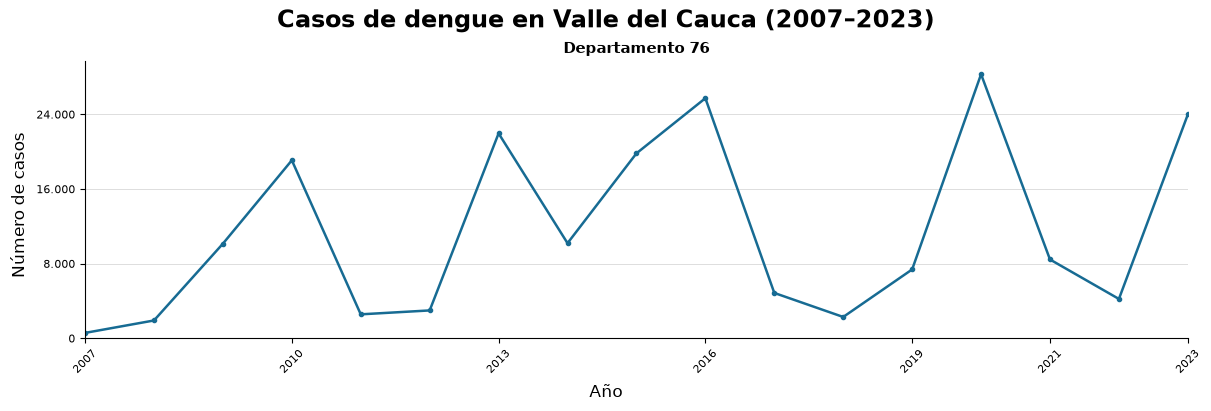

In [12]:
if casos_departamento_ano.empty:
    raise ValueError('No hay casos disponibles para graficar.')

departamentos = casos_departamento_ano.index.tolist()
anos_grafica = casos_departamento_ano.columns.to_numpy(dtype=int)
n_columnas = min(4, len(departamentos))
n_filas = math.ceil(len(departamentos) / n_columnas)
fig, ejes = plt.subplots(
    n_filas, n_columnas,
    figsize=(12 if n_columnas == 1 else 16, (4 if n_columnas == 1 else 2.8) * n_filas),
    squeeze=False,
    layout='constrained',
)
formato_casos = FuncFormatter(lambda valor, _: f'{valor:,.0f}'.replace(',', '.'))

for eje, departamento in zip(ejes.flat, departamentos):
    serie = casos_departamento_ano.loc[departamento]
    eje.plot(anos_grafica, serie.to_numpy(), color='#176B93', marker='o', markersize=3, linewidth=1.8)
    eje.set_title(f'Departamento {departamento}', fontsize=11, fontweight='bold')
    eje.set_xlim(2007, 2023)
    eje.set_ylim(bottom=0)
    eje.set_xticks([2007, 2010, 2013, 2016, 2019, 2021, 2023])
    eje.tick_params(axis='x', labelrotation=45, labelsize=8)
    eje.tick_params(axis='y', labelsize=8)
    eje.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
    eje.yaxis.set_major_formatter(formato_casos)
    eje.grid(axis='y', color='#DDDDDD', linewidth=0.7)
    eje.spines[['top', 'right']].set_visible(False)

for eje in list(ejes.flat)[len(departamentos):]:
    eje.set_visible(False)

fig.suptitle('Casos de dengue en Valle del Cauca (2007–2023)', fontsize=17, fontweight='bold')
fig.supxlabel('Año', fontsize=12)
fig.supylabel('Número de casos', fontsize=12)
plt.show()

### 6.3. Departamento de trabajo: Valle del Cauca

El departamento elegido para el proyecto es **Valle del Cauca, código 76**. Los archivos de trabajo ya están filtrados a ese departamento. La gráfica anterior describe su evolución; con esta versión reducida no comparamos el volumen de casos entre departamentos.


## 7. Asignar los nombres de los municipios

Usamos `MunicipiosValledelCauca.csv` para agregar el nombre del municipio a los registros del departamento 76. Los códigos se conservan como texto: por ejemplo, `001` corresponde a Cali y no debe convertirse en `1`. El valor `="001"` del catálogo se interpreta como el texto `001`.

Aplicamos el mismo catálogo a los tres periodos. En esta primera revisión mantenemos las filas cuyo código no encuentra correspondencia y contamos cuántas hay en cada conjunto. El punto 8 las elimina de las tablas de trabajo.

La columna `COD_MUN_O_ORIGINAL` guarda el código tal como se leyó. Los archivos originales se mantienen sin cambios.


In [13]:
# Leer el catálogo como texto: nunca convertir los códigos a enteros.
catalogo_municipios = pd.read_csv(
    PROYECTO / 'MunicipiosValledelCauca.csv',
    sep=',', encoding='utf-8-sig', dtype='string', keep_default_na=False,
)

def normalizar_codigo_texto(serie, ancho):
    return (
        serie.astype('string').str.strip()
        .str.replace(r'^="([^"]*)"$', r'\1', regex=True)
        .replace('', pd.NA)
        .str.zfill(ancho)
    )

catalogo_municipios['CODIGO_DEPARTAMENTO'] = normalizar_codigo_texto(
    catalogo_municipios['CODIGO_DEPARTAMENTO'], 2
)
catalogo_municipios['CODIGO_MUNICIPIO'] = normalizar_codigo_texto(
    catalogo_municipios['CODIGO_MUNICIPIO'], 3
)
catalogo_municipios['MUNICIPIO'] = catalogo_municipios['MUNICIPIO'].str.strip()
catalogo_valle = catalogo_municipios.loc[
    catalogo_municipios['CODIGO_DEPARTAMENTO'].eq('76')
].copy()
assert not catalogo_valle.empty, 'El catálogo no contiene municipios del departamento 76.'
assert catalogo_valle['CODIGO_MUNICIPIO'].str.fullmatch(r'\d{3}').fillna(False).all(), 'Hay códigos de municipio inválidos en el CSV.'
assert not catalogo_valle['CODIGO_MUNICIPIO'].duplicated().any(), 'Hay códigos de municipio repetidos en el CSV.'
assert catalogo_valle['MUNICIPIO'].ne('').all(), 'Hay nombres de municipio vacíos en el CSV.'
municipios_por_codigo = catalogo_valle.set_index('CODIGO_MUNICIPIO')['MUNICIPIO']
print(f'Municipios disponibles en el catálogo: {len(catalogo_valle)}')
catalogo_valle[['CODIGO_DEPARTAMENTO', 'CODIGO_MUNICIPIO', 'MUNICIPIO']]

Municipios disponibles en el catálogo: 42


,CODIGO_DEPARTAMENTO,CODIGO_MUNICIPIO,MUNICIPIO
0,76,001,CALI
1,76,020,ALCALA
2,76,036,ANDALUCIA
3,76,041,ANSERMANUEVO
4,76,054,ARGELIA
5,76,100,BOLIVAR
6,76,109,BUENAVENTURA
7,76,111,GUADALAJARA DE BUGA
8,76,113,BUGALAGRANDE
9,76,122,CAICEDONIA


In [14]:
def asignar_municipio_valle(datos):
    resultado = datos.copy()
    if 'COD_MUN_O_ORIGINAL' not in resultado.columns:
        resultado['COD_MUN_O_ORIGINAL'] = resultado['COD_MUN_O'].astype('string')
    resultado['COD_DPTO_O'] = normalizar_codigo_texto(resultado['COD_DPTO_O'], 2)
    resultado['COD_MUN_O'] = normalizar_codigo_texto(resultado['COD_MUN_O'], 3)
    resultado['MUNICIPIO'] = pd.Series(pd.NA, index=resultado.index, dtype='string')
    es_valle = resultado['COD_DPTO_O'].eq('76').fillna(False)
    resultado.loc[es_valle, 'MUNICIPIO'] = resultado.loc[es_valle, 'COD_MUN_O'].map(municipios_por_codigo)
    assert len(resultado) == len(datos), 'La asignación cambió el número de filas.'
    return resultado

# Agregar MUNICIPIO a las filas del departamento 76 en los datos de desarrollo.
df_dengue = asignar_municipio_valle(df_dengue)
df_analisis = asignar_municipio_valle(df_analisis)
df_entrenamiento = asignar_municipio_valle(df_entrenamiento)
df_validacion = asignar_municipio_valle(df_validacion)

df_valle_entrenamiento = df_entrenamiento.loc[df_entrenamiento['COD_DPTO_O'].eq('76')].copy()
df_valle_validacion = df_validacion.loc[df_validacion['COD_DPTO_O'].eq('76')].copy()

# Leer el test solo para asignar municipios y auditar los códigos.
# No incorporar el test a df_analisis ni a las gráficas de desarrollo.
partes_valle_test = []
for ano_test in ANOS_TEST:
    archivo_test = ruta_archivo_dengue(ano_test, DATOS_RAW)
    print(f'Asignando municipios en {archivo_test.name}...', flush=True)
    datos_test = leer_archivo_dengue(archivo_test, COLUMNAS)
    datos_test['INI_SIN'] = datos_test['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
    datos_test = datos_test.dropna(subset=['INI_SIN']).reset_index(drop=True)
    for columna in ['SEMANA', 'ANO']:
        datos_test[columna] = pd.to_numeric(datos_test[columna], errors='raise').astype('Int64')
    datos_test = asignar_municipio_valle(datos_test)
    assert datos_test['ANO'].isin(ANOS_TEST).all(), 'El archivo de test contiene años fuera de 2024-2025.'
    partes_valle_test.append(datos_test.loc[datos_test['COD_DPTO_O'].eq('76')].copy())

df_valle_test = pd.concat(partes_valle_test, ignore_index=True)
del partes_valle_test, datos_test

conjuntos_valle = {
    'Entrenamiento': df_valle_entrenamiento,
    'Validación': df_valle_validacion,
    'Test': df_valle_test,
}
# df_valle_todos se usa solo para la auditoría administrativa de códigos.
df_valle_todos = pd.concat(
    [datos.assign(CONJUNTO=nombre) for nombre, datos in conjuntos_valle.items()],
    ignore_index=True,
)
df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)
assert df_valle_analisis['ANO'].le(2023).all(), 'El análisis del Valle contiene datos de test.'
print('Municipios asignados. El test permanece separado del análisis y del entrenamiento.')

Asignando municipios en Datos_2024_210.csv...


Asignando municipios en Datos_2025_210.csv...


Municipios asignados. El test permanece separado del análisis y del entrenamiento.


In [15]:
resumen_municipios = pd.DataFrame([
    {
        'CONJUNTO': nombre,
        'FILAS_DEPTO_76': len(datos),
        'FILAS_CON_MUNICIPIO': int(datos['MUNICIPIO'].notna().sum()),
        'FILAS_SIN_MUNICIPIO': int(datos['MUNICIPIO'].isna().sum()),
        'CODIGOS_NO_RECONOCIDOS': datos.loc[datos['MUNICIPIO'].isna(), 'COD_MUN_O'].nunique(dropna=False),
    }
    for nombre, datos in conjuntos_valle.items()
])
filas_sin_municipio = df_valle_todos.loc[df_valle_todos['MUNICIPIO'].isna()].copy()
codigos_no_correspondientes = (
    filas_sin_municipio.groupby(
        ['CONJUNTO', 'COD_MUN_O_ORIGINAL', 'COD_MUN_O'], dropna=False,
    ).size().rename('FILAS_SIN_MUNICIPIO').reset_index()
)
assert (resumen_municipios['FILAS_CON_MUNICIPIO'] + resumen_municipios['FILAS_SIN_MUNICIPIO']).equals(resumen_municipios['FILAS_DEPTO_76'])
print(f'Antes del paso 8: filas del Valle sin correspondencia en el catálogo: {len(filas_sin_municipio):,}')
print(f'Códigos distintos sin correspondencia: {filas_sin_municipio["COD_MUN_O"].nunique(dropna=False)}')
resumen_municipios

Antes del paso 8: filas del Valle sin correspondencia en el catálogo: 296
Códigos distintos sin correspondencia: 1


,CONJUNTO,FILAS_DEPTO_76,FILAS_CON_MUNICIPIO,FILAS_SIN_MUNICIPIO,CODIGOS_NO_RECONOCIDOS
0,Entrenamiento,166210,165914,296,1
1,Validación,28199,28199,0,0
2,Test,95648,95648,0,0


In [16]:
# Auditoria antes del paso 8: codigos no reconocidos que se eliminan.
codigos_no_correspondientes

,CONJUNTO,COD_MUN_O_ORIGINAL,COD_MUN_O,FILAS_SIN_MUNICIPIO
0,Entrenamiento,000,000,296


## 8. Retirar los registros con municipios no reconocidos

Excluimos las filas sin municipio, con códigos ajenos al catálogo o con nombres que no coinciden con el código asignado. La regla es la misma para entrenamiento, validación y evaluación.

Las filas retiradas quedan en `filas_descartadas_municipios` para poder revisarlas. Las tablas `df_valle_entrenamiento`, `df_valle_validacion` y `df_valle_test` se actualizan con los registros válidos; `df_valle_analisis` reúne las dos primeras.

La comprobación final revisa que todos los códigos y nombres restantes correspondan al catálogo.


In [17]:
# ELIMINAR FILAS SIN MUNICIPIO CORRESPONDIENTE O CON CODIGO NO RECONOCIDO.
def mascara_municipio_valido(datos):
    codigo_reconocido = datos['COD_MUN_O'].isin(municipios_por_codigo.index)
    municipio_presente = datos['MUNICIPIO'].notna() & datos['MUNICIPIO'].str.strip().ne('')
    municipio_correspondiente = datos['MUNICIPIO'].eq(datos['COD_MUN_O'].map(municipios_por_codigo))
    return (codigo_reconocido & municipio_presente & municipio_correspondiente).fillna(False)

conjuntos_valle_limpios = {}
registros_limpieza = []
partes_descartadas = []
for nombre, datos in conjuntos_valle.items():
    conservar = mascara_municipio_valido(datos)
    limpios = datos.loc[conservar].copy().reset_index(drop=True)
    descartados = datos.loc[~conservar].copy()
    partes_descartadas.append(descartados.assign(CONJUNTO=nombre))
    conjuntos_valle_limpios[nombre] = limpios
    registros_limpieza.append({
        'CONJUNTO': nombre,
        'FILAS_ANTES': len(datos),
        'FILAS_ELIMINADAS': len(descartados),
        'FILAS_LIMPIAS': len(limpios),
    })

# Reemplazar los tres conjuntos de trabajo con los datos válidos.
df_valle_entrenamiento = conjuntos_valle_limpios['Entrenamiento']
df_valle_validacion = conjuntos_valle_limpios['Validación']
df_valle_test = conjuntos_valle_limpios['Test']
conjuntos_valle = conjuntos_valle_limpios
filas_descartadas_municipios = pd.concat(partes_descartadas, ignore_index=True)
del partes_descartadas

df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)
df_valle_todos = pd.concat(
    [datos.assign(CONJUNTO=nombre) for nombre, datos in conjuntos_valle.items()],
    ignore_index=True,
)

# Retirar también los registros inválidos del Valle de los DataFrames generales.
# La condición de municipio se aplica exclusivamente al departamento 76.
def retirar_municipios_invalidos_del_valle(datos):
    es_valle = datos['COD_DPTO_O'].eq('76').fillna(False)
    conservar = ~es_valle | mascara_municipio_valido(datos)
    return datos.loc[conservar].copy().reset_index(drop=True)

df_dengue = retirar_municipios_invalidos_del_valle(df_dengue)
df_analisis = retirar_municipios_invalidos_del_valle(df_analisis)
df_entrenamiento = retirar_municipios_invalidos_del_valle(df_entrenamiento)
df_validacion = retirar_municipios_invalidos_del_valle(df_validacion)

resumen_limpieza_municipios = pd.DataFrame(registros_limpieza)
assert (resumen_limpieza_municipios['FILAS_ANTES'] - resumen_limpieza_municipios['FILAS_ELIMINADAS']).equals(resumen_limpieza_municipios['FILAS_LIMPIAS'])
assert df_valle_analisis['ANO'].le(2023).all(), 'El análisis del Valle contiene datos de test.'
print(f"Filas eliminadas por municipio inválido: {resumen_limpieza_municipios['FILAS_ELIMINADAS'].sum():,}")
resumen_limpieza_municipios

Filas eliminadas por municipio inválido: 296


,CONJUNTO,FILAS_ANTES,FILAS_ELIMINADAS,FILAS_LIMPIAS
0,Entrenamiento,166210,296,165914
1,Validación,28199,0,28199
2,Test,95648,0,95648


In [18]:
verificacion_municipios_limpios = pd.DataFrame([
    {
        'CONJUNTO': nombre,
        'FILAS_LIMPIAS': len(datos),
        'MUNICIPIOS_FALTANTES_O_VACIOS': int((datos['MUNICIPIO'].isna() | datos['MUNICIPIO'].str.strip().eq('').fillna(False)).sum()),
        'CODIGOS_NO_RECONOCIDOS': int((~datos['COD_MUN_O'].isin(municipios_por_codigo.index)).sum()),
        'NOMBRES_NO_CORRESPONDIENTES': int((~datos['MUNICIPIO'].eq(datos['COD_MUN_O'].map(municipios_por_codigo)).fillna(False)).sum()),
    }
    for nombre, datos in conjuntos_valle.items()
])
columnas_errores = ['MUNICIPIOS_FALTANTES_O_VACIOS', 'CODIGOS_NO_RECONOCIDOS', 'NOMBRES_NO_CORRESPONDIENTES']
assert verificacion_municipios_limpios[columnas_errores].eq(0).all().all(), 'Quedan errores de correspondencia de municipio.'
assert df_valle_entrenamiento['ANO'].between(2007, 2021).all()
assert df_valle_validacion['ANO'].between(2022, 2023).all()
assert df_valle_test['ANO'].between(2024, 2025).all()
print('Los tres conjuntos tienen municipios válidos y mantienen su separación temporal.')
verificacion_municipios_limpios

Los tres conjuntos tienen municipios válidos y mantienen su separación temporal.


,CONJUNTO,FILAS_LIMPIAS,MUNICIPIOS_FALTANTES_O_VACIOS,CODIGOS_NO_RECONOCIDOS,NOMBRES_NO_CORRESPONDIENTES
0,Entrenamiento,165914,0,0,0
1,Validación,28199,0,0,0
2,Test,95648,0,0,0


## 9. Guardar y cargar los conjuntos limpios

Los datos limpios del Valle del Cauca quedan en tres archivos, separados por periodo:

| Archivo | DataFrame | Periodo |
| --- | --- | --- |
| `training.csv` | `df_valle_entrenamiento` | 2007–2021 |
| `validation.csv` | `df_valle_validacion` | 2022–2023 |
| `test.csv` | `df_valle_test` | 2024–2025 |

### 9.1. Guardar los conjuntos

Ejecutamos esta parte después de completar la limpieza del punto 8. Se revisan los periodos y municipios antes de guardar todas las columnas, sin índice y con codificación `utf-8-sig`.

Esta celda actualiza los tres CSV. Si ya existen y solo queremos continuar el análisis, la omitimos y pasamos directamente al punto 9.2.


In [19]:
exportaciones_csv = {
    'training.csv': (df_valle_entrenamiento, 2007, 2021),
    'validation.csv': (df_valle_validacion, 2022, 2023),
    'test.csv': (df_valle_test, 2024, 2025),
}

# Comprobar los tres conjuntos antes de escribir cualquier archivo.
for nombre_archivo, (datos, ano_inicio, ano_fin) in exportaciones_csv.items():
    assert not datos.empty, f'{nombre_archivo}: el conjunto está vacío.'
    assert datos['ANO'].between(ano_inicio, ano_fin).all(), f'{nombre_archivo}: hay años fuera de su periodo.'
    assert datos['COD_DPTO_O'].eq('76').all(), f'{nombre_archivo}: hay otros departamentos.'
    assert mascara_municipio_valido(datos).all(), f'{nombre_archivo}: hay municipios inválidos.'
    assert datos['INI_SIN'].notna().all(), f'{nombre_archivo}: hay INI_SIN faltantes.'
    for columna in ['COD_DPTO_O', 'COD_MUN_O', 'COD_MUN_O_ORIGINAL']:
        assert isinstance(datos[columna].dtype, pd.StringDtype), f'{nombre_archivo}: {columna} debe ser string.'

registros_exportacion = []
for nombre_archivo, (datos, ano_inicio, ano_fin) in exportaciones_csv.items():
    ruta_csv = PROYECTO / nombre_archivo
    datos.to_csv(ruta_csv, index=False, encoding='utf-8-sig', quoting=csv.QUOTE_NONNUMERIC)
    registros_exportacion.append({
        'ARCHIVO': nombre_archivo,
        'PERIODO': f'{ano_inicio}-{ano_fin}',
        'FILAS_GUARDADAS': len(datos),
        'COLUMNAS': len(datos.columns),
        'RUTA': str(ruta_csv),
    })
    print(f'Guardado {nombre_archivo}: {len(datos):,} filas.')

resumen_exportacion_csv = pd.DataFrame(registros_exportacion)
resumen_exportacion_csv

Guardado training.csv: 165,914 filas.
Guardado validation.csv: 28,199 filas.


Guardado test.csv: 95,648 filas.


,ARCHIVO,PERIODO,FILAS_GUARDADAS,COLUMNAS,RUTA
0,training.csv,2007-2021,165914,7,training.csv
1,validation.csv,2022-2023,28199,7,validation.csv
2,test.csv,2024-2025,95648,7,test.csv


### 9.2. Cargar los conjuntos guardados

Para retomar el trabajo en otra sesión, ejecutamos los puntos 1 y 2, y después esta celda. No hace falta repetir los puntos 3 al 8 ni el guardado del 9.1. Una vez cargados los datos, podemos continuar desde el punto 10.

La lectura conserva los códigos como texto, incluidos los ceros iniciales. Comprueba las columnas, los periodos y los campos necesarios, sin volver a limpiar ni sobrescribir los archivos. Recupera los mismos nombres de los DataFrames que utilizamos en el resto del notebook.

Entrenamiento y validación se reúnen en `df_valle_analisis`. El conjunto de evaluación se mantiene separado.


In [20]:
# Lectura independiente: solo necesita la configuración y las librerías de 1 y 2.
archivos_conjuntos_limpios = {
    'Entrenamiento': ('training.csv', 2007, 2021),
    'Validación': ('validation.csv', 2022, 2023),
    'Test': ('test.csv', 2024, 2025),
}
tipos_conjuntos_limpios = {
    'COD_DPTO_O': 'string',
    'COD_MUN_O': 'string',
    'SEMANA': 'Int64',
    'ANO': 'Int64',
    'INI_SIN': 'string',
    'COD_MUN_O_ORIGINAL': 'string',
    'MUNICIPIO': 'string',
}
faltantes_conjuntos = [
    archivo for archivo, _, _ in archivos_conjuntos_limpios.values()
    if not (PROYECTO / archivo).is_file()
]
if faltantes_conjuntos:
    raise FileNotFoundError(
        f'Faltan conjuntos limpios: {faltantes_conjuntos}. '
        'Completa la limpieza y ejecuta el punto 9.1 antes de usar esta carga.'
    )

conjuntos_limpios_cargados = {}
registros_carga_conjuntos = []
for nombre, (archivo, inicio, fin) in archivos_conjuntos_limpios.items():
    datos = pd.read_csv(
        PROYECTO / archivo, dtype=tipos_conjuntos_limpios,
        encoding='utf-8-sig', keep_default_na=False, na_values=[''],
    )
    ausentes = sorted(set(tipos_conjuntos_limpios) - set(datos.columns))
    if ausentes:
        raise ValueError(f'{archivo}: faltan columnas: {ausentes}.')
    if datos.empty:
        raise ValueError(f'{archivo}: el conjunto está vacío.')
    if datos[list(tipos_conjuntos_limpios)].isna().any().any():
        raise ValueError(f'{archivo}: hay valores faltantes en las columnas requeridas.')
    if not datos['ANO'].between(inicio, fin).all():
        raise ValueError(f'{archivo}: hay registros fuera del periodo {inicio}–{fin}.')
    if not datos['SEMANA'].between(1, 53).all():
        raise ValueError(f'{archivo}: hay semanas fuera del rango 1–53.')
    if not datos['COD_DPTO_O'].eq(DEPARTAMENTO).all():
        raise ValueError(f'{archivo}: contiene registros de otro departamento.')
    if not datos['COD_MUN_O'].str.fullmatch(r'\d{3}').all():
        raise ValueError(f'{archivo}: los códigos municipales deben tener tres caracteres.')
    if datos[['INI_SIN', 'MUNICIPIO']].apply(lambda c: c.str.strip().eq('')).any().any():
        raise ValueError(f'{archivo}: hay fechas o nombres de municipio vacíos.')
    conjuntos_limpios_cargados[nombre] = datos
    registros_carga_conjuntos.append({
        'CONJUNTO': nombre, 'ARCHIVO': archivo, 'PERIODO': f'{inicio}–{fin}',
        'FILAS': len(datos), 'COLUMNAS': len(datos.columns),
    })

# Actualizar los DataFrames solo después de comprobar los tres archivos.
df_valle_entrenamiento = conjuntos_limpios_cargados['Entrenamiento']
df_valle_validacion = conjuntos_limpios_cargados['Validación']
df_valle_test = conjuntos_limpios_cargados['Test']
conjuntos_valle = conjuntos_limpios_cargados
conjuntos_valle_limpios = conjuntos_limpios_cargados
df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)

# Mantener también los nombres de los datos de desarrollo usados al inicio.
df_entrenamiento = df_valle_entrenamiento.copy()
df_validacion = df_valle_validacion.copy()
df_analisis = df_valle_analisis.copy()
df_dengue = df_valle_analisis.copy()

resumen_carga_conjuntos_limpios = pd.DataFrame(registros_carga_conjuntos)
print('Conjuntos limpios cargados. Puedes continuar desde el punto 10.')
display(resumen_carga_conjuntos_limpios)


Conjuntos limpios cargados. Puedes continuar desde el punto 10.


,CONJUNTO,ARCHIVO,PERIODO,FILAS,COLUMNAS
0,Entrenamiento,training.csv,2007–2021,165914,7
1,Validación,validation.csv,2022–2023,28199,7
2,Test,test.csv,2024–2025,95648,7


## 10. Seleccionar los cinco municipios con más casos

Sumamos los casos de cada municipio entre 2007 y 2023 a partir de `training.csv` y `validation.csv`. Ordenamos los totales de mayor a menor y guardamos los cinco primeros en `top_5_municipios_valle`.

La selección utiliza cantidades acumuladas de casos, no tasas ajustadas por población. Los datos de evaluación no participan en este ranking.


In [21]:
# Leer únicamente entrenamiento y validación, ya limpios en los pasos 8 y 9.
# Para retomar: ejecutar primero 1, 2 y 9.2, y continuar desde esta celda.
ruta_proyecto_ranking = Path('.')
columnas_ranking = ['COD_DPTO_O', 'COD_MUN_O', 'MUNICIPIO', 'ANO', 'INI_SIN']
tipos_ranking = {
    'COD_DPTO_O': 'string',
    'COD_MUN_O': 'string',
    'MUNICIPIO': 'string',
    'ANO': 'Int64',
    'INI_SIN': 'string',
}
partes_ranking = []
for archivo, inicio, fin in [
    ('training.csv', 2007, 2021),
    ('validation.csv', 2022, 2023),
]:
    datos_ranking = pd.read_csv(
        ruta_proyecto_ranking / archivo,
        encoding='utf-8-sig',
        usecols=columnas_ranking,
        dtype=tipos_ranking,
    )
    assert not datos_ranking.empty, f'{archivo}: no contiene casos.'
    assert datos_ranking['ANO'].notna().all() and datos_ranking['ANO'].between(inicio, fin).all(), f'{archivo}: periodo incorrecto.'
    assert datos_ranking['COD_DPTO_O'].eq('76').fillna(False).all(), f'{archivo}: contiene otros departamentos.'
    assert datos_ranking[['COD_MUN_O', 'MUNICIPIO', 'INI_SIN']].notna().all().all(), f'{archivo}: contiene valores faltantes.'
    assert datos_ranking['MUNICIPIO'].str.strip().ne('').all(), f'{archivo}: contiene municipios vacíos.'
    partes_ranking.append(datos_ranking)

df_historico_valle = pd.concat(partes_ranking, ignore_index=True)
casos_historicos_municipio = (
    df_historico_valle.groupby(['COD_MUN_O', 'MUNICIPIO'])
    .size()
    .rename('CASOS')
    .reset_index()
    .sort_values(['CASOS', 'COD_MUN_O'], ascending=[False, True])
    .reset_index(drop=True)
)
assert casos_historicos_municipio['CASOS'].sum() == len(df_historico_valle)

top_5_municipios_valle = casos_historicos_municipio.head(5).copy()
top_5_municipios_valle.insert(0, 'POSICION', range(1, len(top_5_municipios_valle) + 1))
print(f'Valle del Cauca (76), 2007–2023: {len(df_historico_valle):,} casos limpios en total.')
print('Cinco municipios con más casos acumulados. Test 2024–2025 reservado.')
top_5_municipios_valle


Valle del Cauca (76), 2007–2023: 194,113 casos limpios en total.
Cinco municipios con más casos acumulados. Test 2024–2025 reservado.


,POSICION,COD_MUN_O,MUNICIPIO,CASOS
0,1,001,CALI,122040
1,2,520,PALMIRA,17175
2,3,834,TULUA,6771
3,4,892,YUMBO,5695
4,5,111,GUADALAJARA DE BUGA,5411


## 11. Reunir los casos semanales y el clima

Ahora construimos la tabla con la que trabajarán los modelos: una fila por municipio, año y semana epidemiológica, con el número de casos y las condiciones climáticas de esa semana.

Usamos los cinco municipios seleccionados en el punto 10: **Cali, Palmira, Tuluá, Yumbo y Guadalajara de Buga**. Esa selección debe estar disponible en `top_5_municipios_valle` antes de ejecutar esta parte.

La integración sigue estos pasos:

1. Tomamos los conjuntos limpios del punto 9 y seleccionamos los registros de esos municipios. Si no están cargados, el código admite como alternativa los archivos anuales de `DataRaw`, aplicando la limpieza de `INI_SIN`.
2. Contamos las filas por municipio, `ANO` y `SEMANA` para obtener `CASOS`. La semana es la registrada en el archivo; no necesariamente corresponde a la semana de inicio de síntomas. Si dos filas tienen los mismos valores, ambas se cuentan.
3. Reunimos los CSV de `ShapeMunicipios/CLIMA_DENGUE_VALLE`, con precipitación (`PRECIPITACION_MM`) y temperaturas media, máxima y mínima (`TEMP_MEDIA_C`, `TEMP_MAX_C`, `TEMP_MIN_C`). Conservamos también las fechas de cada semana.
4. Unimos los conteos y el clima por municipio, año y semana. Unificamos `ANIO` como `ANO` y `SEMANA` como `SEMANA_EPI`. El código DANE completo combina departamento y municipio: `76` + `001` = `76001` para Cali.
5. Completamos el calendario de cada municipio con las semanas de los archivos climáticos, incluidas las semanas 53. Si una semana no tiene registros de casos, asignamos cero. Si falta una variable climática, la dejamos vacía para detectarla en las comprobaciones posteriores.

Por ejemplo, una fila permite consultar cuántos casos se registraron en Cali durante una semana y cuál fue su precipitación y temperatura. Las series municipales se mantienen separadas: no sumamos ni promediamos el clima de los cinco municipios.


In [22]:
RUTA_SERIES = Path('.')
DEPARTAMENTO_SERIES = '76'
PERIODOS_SERIES = {
    'training': range(2007, 2022),
    'validation': range(2022, 2024),
    'test': range(2024, 2026),
}
ANOS_SERIES = [ano for periodo in PERIODOS_SERIES.values() for ano in periodo]
VARIABLES_CLIMA = ['PRECIPITACION_MM', 'TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
CLAVES_SERIE = ['COD_DANE', 'ANO', 'SEMANA_EPI']

def codigo_serie(serie, ancho):
    # Admitir códigos con ceros iniciales, formato de Excel ="001" o sufijo .0.
    return (
        serie.astype('string').str.strip()
        .str.replace(r'^="([^"]*)"$', r'\1', regex=True)
        .str.replace(r'\.0+$', '', regex=True)
        .replace('', pd.NA).str.zfill(ancho)
    )

municipios_interes = top_5_municipios_valle[['COD_MUN_O', 'MUNICIPIO']].copy()
municipios_interes['COD_MUN_O'] = codigo_serie(municipios_interes['COD_MUN_O'], 3)
if (len(municipios_interes) != 5
        or municipios_interes['COD_MUN_O'].duplicated().any()
        or not municipios_interes['COD_MUN_O'].str.fullmatch(r'\d{3}').fillna(False).all()):
    raise ValueError('Ejecuta el punto 10: se requieren cinco códigos municipales distintos y válidos.')
municipios_interes['COD_DPTO_O'] = DEPARTAMENTO_SERIES
municipios_interes['COD_DANE'] = DEPARTAMENTO_SERIES + municipios_interes['COD_MUN_O']
municipios_interes = municipios_interes.sort_values('COD_DANE').reset_index(drop=True)

# Revisar todos los insumos antes de leer los archivos anuales.
rutas_clima = {
    ano: RUTA_SERIES / 'ShapeMunicipios' / 'CLIMA_DENGUE_VALLE' / f'CLIMA_VALLE_SIVIGILA_{ano}.csv'
    for ano in ANOS_SERIES
}
conjuntos_casos_disponibles = {
    'training': globals().get('df_valle_entrenamiento'),
    'validation': globals().get('df_valle_validacion'),
    'test': globals().get('df_valle_test'),
}
USAR_CONJUNTOS_LIMPIOS = all(
    isinstance(datos, pd.DataFrame) for datos in conjuntos_casos_disponibles.values()
)
rutas_casos = {} if USAR_CONJUNTOS_LIMPIOS else {
    ano: ruta_archivo_dengue(ano, RUTA_SERIES / 'DataRaw')
    for ano in ANOS_SERIES
}
faltantes_series = [str(ruta) for ruta in [*rutas_clima.values(), *rutas_casos.values()] if not ruta.is_file()]
if faltantes_series:
    raise FileNotFoundError(f'Faltan insumos para preparar las series: {faltantes_series}')

display(municipios_interes[['COD_DPTO_O', 'COD_MUN_O', 'COD_DANE', 'MUNICIPIO']])

,COD_DPTO_O,COD_MUN_O,COD_DANE,MUNICIPIO
0,76,001,76001,CALI
1,76,111,76111,GUADALAJARA DE BUGA
2,76,520,76520,PALMIRA
3,76,834,76834,TULUA
4,76,892,76892,YUMBO


In [23]:
# Una observación climática por municipio, año y semana. No sumar ni promediar
# duplicados: podrían multiplicar los conteos durante la unión.
columnas_clima = ['COD_DANE', 'ANIO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN', *VARIABLES_CLIMA]
partes_clima = []
for ano, ruta in rutas_clima.items():
    clima_ano = pd.read_csv(ruta, usecols=columnas_clima, dtype='string', encoding='utf-8-sig')
    clima_ano['COD_DANE'] = codigo_serie(clima_ano['COD_DANE'], 5)
    clima_ano = clima_ano.loc[clima_ano['COD_DANE'].isin(municipios_interes['COD_DANE'])].copy()
    clima_ano = clima_ano.rename(columns={'ANIO': 'ANO'})
    for columna in ['ANO', 'SEMANA_EPI']:
        clima_ano[columna] = pd.to_numeric(clima_ano[columna], errors='raise').astype('Int64')
    if clima_ano.empty or not clima_ano['ANO'].eq(ano).fillna(False).all():
        raise ValueError(f'{ruta.name}: año incorrecto o sin clima para los municipios seleccionados.')
    if not clima_ano['SEMANA_EPI'].between(1, 53).fillna(False).all():
        raise ValueError(f'{ruta.name}: semanas epidemiológicas faltantes o fuera de 1–53.')
    for columna in VARIABLES_CLIMA:
        clima_ano[columna] = pd.to_numeric(clima_ano[columna], errors='raise').astype('Float64')
    for columna in ['FECHA_INICIO', 'FECHA_FIN']:
        clima_ano[columna] = pd.to_datetime(clima_ano[columna], format='%Y-%m-%d', errors='raise')
    partes_clima.append(clima_ano)

df_clima_semanal = pd.concat(partes_clima, ignore_index=True)
del partes_clima, clima_ano
if df_clima_semanal.duplicated(CLAVES_SERIE).any():
    raise ValueError('Hay claves municipio/año/semana repetidas en los insumos de clima.')
if df_clima_semanal[['FECHA_INICIO', 'FECHA_FIN']].isna().any().any():
    raise ValueError('Hay fechas faltantes en el calendario climático.')
if not (df_clima_semanal['FECHA_FIN'] - df_clima_semanal['FECHA_INICIO']).dt.days.eq(6).all():
    raise ValueError('Hay semanas climáticas que no abarcan siete días.')

# Comprobar que cada semana del calendario exista para los cinco municipios
# y que todos compartan las mismas fechas. No generar semanas con calendario ISO.
calendario_series = df_clima_semanal[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']].drop_duplicates()
if calendario_series.duplicated(['ANO', 'SEMANA_EPI']).any():
    raise ValueError('Las fechas de una misma semana difieren entre municipios.')
calendario_series = calendario_series.sort_values(['ANO', 'SEMANA_EPI']).reset_index(drop=True)
if not calendario_series.groupby('ANO')['SEMANA_EPI'].apply(
    lambda semanas: semanas.tolist() == list(range(1, int(semanas.max()) + 1)) and int(semanas.max()) in (52, 53)
).all():
    raise ValueError('El calendario climático contiene años incompletos o semanas intermedias faltantes.')
if not calendario_series['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
    raise ValueError('Hay huecos o solapamientos entre las fechas de las semanas climáticas.')
claves_esperadas = municipios_interes[['COD_DANE']].merge(
    calendario_series[['ANO', 'SEMANA_EPI']], how='cross',
)
if len(df_clima_semanal) != len(claves_esperadas):
    raise ValueError('Faltan semanas climáticas para alguno de los municipios seleccionados.')
print('Calendario climático verificado para los cinco municipios y todos los años de trabajo.')

Calendario climático verificado para los cinco municipios y todos los años de trabajo.


### 11.1. Contar los casos por semana

Procesamos un año a la vez y contamos los registros por municipio y semana.  el dataframe `resumen_carga_semanal` indica la fuente y los registros seleccionados y contados en entrenamiento y validación.

In [24]:
columnas_casos_series = ['COD_DPTO_O', 'COD_MUN_O', 'ANO', 'SEMANA', 'INI_SIN']

def contar_casos_semanales(anos, nombre_conjunto):
    partes_conteo = []
    registros_carga = []
    for ano in anos:
        if USAR_CONJUNTOS_LIMPIOS:
            origen = conjuntos_casos_disponibles[nombre_conjunto]
            datos = origen.loc[origen['ANO'].eq(ano), columnas_casos_series].copy()
            nombre_fuente = f'conjunto limpio {nombre_conjunto}, año {ano}'
        else:
            ruta = rutas_casos[ano]
            datos = leer_archivo_dengue(ruta, columnas_casos_series)
            nombre_fuente = ruta.name
        print(f'[{nombre_conjunto}] Contando casos de {nombre_fuente}...', flush=True)
        datos['COD_DPTO_O'] = codigo_serie(datos['COD_DPTO_O'], 2)
        datos['COD_MUN_O'] = codigo_serie(datos['COD_MUN_O'], 3)
        datos = datos.loc[
            datos['COD_DPTO_O'].eq(DEPARTAMENTO_SERIES)
            & datos['COD_MUN_O'].isin(municipios_interes['COD_MUN_O'])
        ].copy()
        seleccionados = len(datos)
        datos['INI_SIN'] = datos['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
        datos = datos.dropna(subset=['INI_SIN']).copy()
        for columna in ['ANO', 'SEMANA']:
            datos[columna] = pd.to_numeric(datos[columna], errors='raise').astype('Int64')
        if not datos['ANO'].eq(ano).fillna(False).all():
            raise ValueError(f'{nombre_fuente}: hay casos sin ANO o con ANO distinto del archivo. Revisar antes de separar los conjuntos.')
        if not datos['SEMANA'].between(1, 53).fillna(False).all():
            raise ValueError(f'{nombre_fuente}: hay casos sin SEMANA válida. No se pueden agrupar silenciosamente.')
        datos['COD_DANE'] = datos['COD_DPTO_O'] + datos['COD_MUN_O']
        conteos = (
            datos.rename(columns={'SEMANA': 'SEMANA_EPI'})
            .groupby(CLAVES_SERIE).size().rename('CASOS').reset_index()
        )
        assert int(conteos['CASOS'].sum()) == len(datos), 'Se perdieron casos al agrupar.'
        partes_conteo.append(conteos)
        # El test se prepara, pero no se muestran ni almacenan resúmenes exploratorios.
        if nombre_conjunto != 'test':
            registros_carga.append({
                'CONJUNTO': nombre_conjunto, 'ANO': ano,
                'FUENTE': 'Conjunto limpio' if USAR_CONJUNTOS_LIMPIOS else 'Archivo anual',
                'REGISTROS_MUNICIPIOS_INTERES': seleccionados,
                'EXCLUIDOS_SIN_INI_SIN': seleccionados - len(datos),
                'CASOS_CONTADOS': len(datos),
            })
    return pd.concat(partes_conteo, ignore_index=True), registros_carga

conteos_por_conjunto = {}
registros_carga_semanal = []
for conjunto, anos in PERIODOS_SERIES.items():
    conteos_por_conjunto[conjunto], registros = contar_casos_semanales(anos, conjunto)
    registros_carga_semanal.extend(registros)
resumen_carga_semanal = pd.DataFrame(registros_carga_semanal)
display(resumen_carga_semanal)

[training] Contando casos de conjunto limpio training, año 2007...


[training] Contando casos de conjunto limpio training, año 2008...


[training] Contando casos de conjunto limpio training, año 2009...


[training] Contando casos de conjunto limpio training, año 2010...


[training] Contando casos de conjunto limpio training, año 2011...


[training] Contando casos de conjunto limpio training, año 2012...


... (10 outputs left out)

[validation] Contando casos de conjunto limpio validation, año 2023...


[test] Contando casos de conjunto limpio test, año 2024...

[test] Contando casos de conjunto limpio test, año 2025...


,CONJUNTO,ANO,FUENTE,REGISTROS_MUNICIPIOS_INTERES,EXCLUIDOS_SIN_INI_SIN,CASOS_CONTADOS
0,training,2007,Conjunto limpio,325,0,325
1,training,2008,Conjunto limpio,1515,0,1515
2,training,2009,Conjunto limpio,8318,0,8318
3,training,2010,Conjunto limpio,14093,0,14093
4,training,2011,Conjunto limpio,1930,0,1930
5,training,2012,Conjunto limpio,2397,0,2397
6,training,2013,Conjunto limpio,18778,0,18778
7,training,2014,Conjunto limpio,7646,0,7646
8,training,2015,Conjunto limpio,16556,0,16556
9,training,2016,Conjunto limpio,22211,0,22211


In [25]:
def integrar_serie_semanal(conteos, anos, nombre_conjunto):
    clima = df_clima_semanal.loc[df_clima_semanal['ANO'].isin(anos)].copy()
    serie = clima.merge(conteos, on=CLAVES_SERIE, how='outer', validate='one_to_one', indicator=True)
    # Nunca perder casos porque su semana no aparezca en los archivos climáticos.
    if serie['_merge'].eq('right_only').any():
        raise ValueError(f'{nombre_conjunto}: hay claves de casos sin semana climática. Revisar el calendario antes de exportar.')
    serie['CASOS'] = serie['CASOS'].fillna(0).astype('Int64')
    serie = serie.drop(columns='_merge').merge(
        municipios_interes, on='COD_DANE', how='left', validate='many_to_one',
    )
    serie['CLIMA_COMPLETO'] = serie[VARIABLES_CLIMA].notna().all(axis=1)
    serie = serie[[
        'COD_DPTO_O', 'COD_MUN_O', 'COD_DANE', 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
        'FECHA_INICIO', 'FECHA_FIN', 'CASOS', *VARIABLES_CLIMA, 'CLIMA_COMPLETO',
    ]].sort_values(['COD_DANE', 'ANO', 'SEMANA_EPI']).reset_index(drop=True)
    assert serie['CASOS'].sum() == conteos['CASOS'].sum(), 'La unión alteró el total de casos.'
    assert not serie.duplicated(CLAVES_SERIE).any()
    assert serie['ANO'].isin(anos).all()
    return serie

series_por_conjunto = {
    conjunto: integrar_serie_semanal(conteos_por_conjunto[conjunto], anos, conjunto)
    for conjunto, anos in PERIODOS_SERIES.items()
}
df_semanal_entrenamiento = series_por_conjunto['training']
df_semanal_validacion = series_por_conjunto['validation']
df_semanal_test = series_por_conjunto['test']  # Reservado para la evaluación final.
df_semanal_analisis = pd.concat([df_semanal_entrenamiento, df_semanal_validacion], ignore_index=True)
assert df_semanal_analisis['ANO'].between(2007, 2023).all()

# Exportar únicamente cuando los tres conjuntos hayan superado las validaciones.
# Estos archivos semanales no sobrescriben los CSV de casos individuales del punto 9.
CARPETA_SERIES = RUTA_SERIES / 'DatosProcesados'
CARPETA_SERIES.mkdir(parents=True, exist_ok=True)
for conjunto, serie in series_por_conjunto.items():
    serie.to_csv(
        CARPETA_SERIES / f'semanal_{conjunto}.csv',
        index=False, encoding='utf-8-sig', date_format='%Y-%m-%d',
    )
print(f'Series semanales guardadas en: {CARPETA_SERIES}')
print('El test queda preparado en su archivo separado para la evaluación final.')

# Revisar solo desarrollo. Los faltantes climáticos permanecen como nulos.
resumen_series_desarrollo = pd.DataFrame([
    {
        'CONJUNTO': conjunto,
        'FILAS_MUNICIPIO_SEMANA': len(series_por_conjunto[conjunto]),
        'MUNICIPIOS': series_por_conjunto[conjunto]['COD_DANE'].nunique(),
        'CASOS': int(series_por_conjunto[conjunto]['CASOS'].sum()),
        'SEMANAS_SIN_CASOS': int(series_por_conjunto[conjunto]['CASOS'].eq(0).sum()),
        'FILAS_CON_CLIMA_FALTANTE': int((~series_por_conjunto[conjunto]['CLIMA_COMPLETO']).sum()),
    }
    for conjunto in ['training', 'validation']
])
display(resumen_series_desarrollo)
display(df_semanal_analisis.head(10))

Series semanales guardadas en: DatosProcesados
El test queda preparado en su archivo separado para la evaluación final.


,CONJUNTO,FILAS_MUNICIPIO_SEMANA,MUNICIPIOS,CASOS,SEMANAS_SIN_CASOS,FILAS_CON_CLIMA_FALTANTE
0,training,3915,5,134012,524,0
1,validation,520,5,23080,72,0


,COD_DPTO_O,COD_MUN_O,COD_DANE,MUNICIPIO,ANO,SEMANA_EPI,FECHA_INICIO,FECHA_FIN,CASOS,PRECIPITACION_MM,TEMP_MEDIA_C,TEMP_MAX_C,TEMP_MIN_C,CLIMA_COMPLETO
0,76,001,76001,CALI,2007,1,2006-12-31,2007-01-06,7,17.199012,18.69441,23.29439,14.762953,True
1,76,001,76001,CALI,2007,2,2007-01-07,2007-01-13,0,27.684166,18.86108,22.737327,16.140837,True
2,76,001,76001,CALI,2007,3,2007-01-14,2007-01-20,3,59.40217,18.866276,23.40366,15.808891,True
3,76,001,76001,CALI,2007,4,2007-01-21,2007-01-27,4,41.167944,18.669141,23.24315,15.65037,True
4,76,001,76001,CALI,2007,5,2007-01-28,2007-02-03,0,0.16281,19.287401,24.384016,14.767081,True
5,76,001,76001,CALI,2007,6,2007-02-04,2007-02-10,0,0.0,18.530701,23.619103,13.862981,True
6,76,001,76001,CALI,2007,7,2007-02-11,2007-02-17,1,38.549986,17.914328,23.714893,13.771234,True
7,76,001,76001,CALI,2007,8,2007-02-18,2007-02-24,2,2.135464,17.650191,23.190763,14.119137,True
8,76,001,76001,CALI,2007,9,2007-02-25,2007-03-03,0,0.092534,18.742788,23.394694,14.550974,True
9,76,001,76001,CALI,2007,10,2007-03-04,2007-03-10,2,44.076288,18.35437,22.8874,14.913091,True


Al terminar tenemos tres tablas con el municipio, el año, la semana, sus fechas, los casos y las cuatro variables climáticas:

| DataFrame | Archivo en `DatosProcesados/` | Periodo |
| --- | --- | --- |
| `df_semanal_entrenamiento` | `semanal_training.csv` | 2007–2021 |
| `df_semanal_validacion` | `semanal_validation.csv` | 2022–2023 |
| `df_semanal_test` | `semanal_test.csv` | 2024–2025 |

`df_semanal_analisis` reúne entrenamiento y validación.  Estos archivos semanales se guardan aparte de los registros individuales del punto 9.


## 12. Preparar las variables para los modelos

Reutilizamos las tablas semanales del punto 11. Como los casos, la precipitación y la temperatura tienen magnitudes distintas, transformamos sus valores antes de entrenar. Esto facilita el ajuste de las redes y mantiene una preparación común para la comparación.

Los escaladores se ajustan **solo con entrenamiento, de 2007 a 2021**. Después aplicamos esas mismas transformaciones a validación y evaluación. Así evitamos que la preparación aprenda de los años posteriores.

| Variables | Transformación | Datos usados para ajustar |
| --- | --- | --- |
| `CASOS` | `log1p` y luego `StandardScaler` | Un escalador por municipio, con entrenamiento. |
| Las tres temperaturas | `StandardScaler`, con una media y escala por columna | Entrenamiento de los cinco municipios. |
| `PRECIPITACION_MM` | `log1p` y luego `StandardScaler` | Entrenamiento de los cinco municipios. |
| `SEMANA_EPI` | Seno y coseno, según las 52 o 53 semanas de cada año | Usa el calendario; no necesita ajustar un escalador. |
| Municipio, códigos y fechas | Se conservan | Son identificadores, no variables para estandarizar. |

`log1p(x)` calcula el logaritmo de `1 + x`. Permite trabajar con ceros y comprime las diferencias entre valores pequeños y muy grandes. Los picos siguen presentes, pero tienen menos peso durante el entrenamiento. Después podemos recuperar la escala original para medir los errores en casos.

Cada municipio tiene su propio escalador de casos, de modo que el volumen de Cali no determine la escala de los demás. Para el clima usamos escaladores compartidos. Estandarizar cambia la escala de los valores; no elimina los extremos ni garantiza una distribución normal.

Las columnas originales se conservan y las transformadas se agregan a nuevos DataFrames. Esta sección no rellena faltantes ni elimina filas: si falta un dato necesario, la ejecución se detiene. Las gráficas de las transformaciones utilizan únicamente entrenamiento.

La implementación sigue la documentación de StandardScaler y las recomendaciones de scikit-learn para evitar fugas de información.


In [26]:
ID_LSTM = 'COD_DANE'
OBJETIVO_LSTM = 'CASOS'
TEMPERATURAS_LSTM = ['TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
PRECIPITACION_LSTM = 'PRECIPITACION_MM'
CLIMA_LSTM = [*TEMPERATURAS_LSTM, PRECIPITACION_LSTM]
CLAVES_LSTM = [ID_LSTM, 'ANO', 'SEMANA_EPI']
PERIODOS_LSTM = {'training': (2007, 2021), 'validation': (2022, 2023), 'test': (2024, 2025)}
columnas_requeridas_lstm = [
    'COD_DPTO_O', 'COD_MUN_O', ID_LSTM, 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
    'FECHA_INICIO', 'FECHA_FIN', OBJETIVO_LSTM, *CLIMA_LSTM,
]

# Reutilizar los objetos del punto 11. Tras reiniciar el kernel, leer solo sus
# CSV semanales pequeños: no repetir la carga costosa de los Excel originales.
entradas_lstm = {
    'training': globals().get('df_semanal_entrenamiento'),
    'validation': globals().get('df_semanal_validacion'),
    'test': globals().get('df_semanal_test'),
}
conjuntos_base_lstm = {}
for nombre, entrada in entradas_lstm.items():
    if entrada is None:
        entrada = pd.read_csv(
            Path('DatosProcesados') / f'semanal_{nombre}.csv',
            encoding='utf-8-sig',
            dtype={'COD_DPTO_O': 'string', 'COD_MUN_O': 'string', ID_LSTM: 'string'},
        )
    datos = entrada.copy(deep=True)
    ausentes = sorted(set(columnas_requeridas_lstm) - set(datos.columns))
    if ausentes:
        raise ValueError(f'{nombre}: faltan columnas requeridas: {ausentes}')
    for columna in ['FECHA_INICIO', 'FECHA_FIN']:
        datos[columna] = pd.to_datetime(datos[columna], errors='raise')
    conjuntos_base_lstm[nombre] = datos

faltantes_lstm = pd.DataFrame({
    nombre: datos[columnas_requeridas_lstm].replace(r'^\s*$', pd.NA, regex=True).isna().sum()
    for nombre, datos in conjuntos_base_lstm.items()
})
if faltantes_lstm.to_numpy().any():
    display(faltantes_lstm.loc[faltantes_lstm.any(axis=1)])
    raise ValueError('Hay campos requeridos faltantes. Definir una estrategia explícita antes de estandarizar; no se imputaron ni eliminaron filas.')

orden_municipios_lstm = sorted(conjuntos_base_lstm['training'][ID_LSTM].unique())
if len(orden_municipios_lstm) != 5:
    raise ValueError('Se esperan los cinco municipios seleccionados en el punto 10.')

for nombre, datos in conjuntos_base_lstm.items():
    inicio, fin = PERIODOS_LSTM[nombre]
    if set(datos[ID_LSTM]) != set(orden_municipios_lstm):
        raise ValueError(f'{nombre}: municipios diferentes de los de entrenamiento.')
    if not datos[ID_LSTM].astype('string').str.fullmatch(r'76\d{3}').all():
        raise ValueError(f'{nombre}: COD_DANE debe conservarse como código de cinco caracteres del Valle.')
    if not datos['COD_DPTO_O'].astype('string').eq('76').all():
        raise ValueError(f'{nombre}: contiene datos de otro departamento.')
    if not datos['ANO'].between(inicio, fin).all() or set(datos['ANO']) != set(range(inicio, fin + 1)):
        raise ValueError(f'{nombre}: periodo incompatible con la separación temporal existente.')
    if datos.duplicated(CLAVES_LSTM).any():
        raise ValueError(f'{nombre}: municipio/año/semana duplicados.')
    valores = datos[[OBJETIVO_LSTM, *CLIMA_LSTM, 'ANO', 'SEMANA_EPI']].to_numpy(dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError(f'{nombre}: se encontraron valores no numéricos o infinitos.')
    if (datos[[OBJETIVO_LSTM, PRECIPITACION_LSTM]] < 0).any().any():
        raise ValueError(f'{nombre}: casos o precipitación negativos; log1p no se aplicará.')
    if not np.equal(datos[OBJETIVO_LSTM], np.floor(datos[OBJETIVO_LSTM])).all():
        raise ValueError(f'{nombre}: CASOS debe contener conteos enteros.')
    if not (datos['FECHA_FIN'] - datos['FECHA_INICIO']).dt.days.eq(6).all():
        raise ValueError(f'{nombre}: hay semanas que no abarcan siete días.')
    for municipio, grupo in datos.groupby(ID_LSTM, sort=False):
        if not grupo['FECHA_INICIO'].is_monotonic_increasing:
            raise ValueError(f'{nombre}/{municipio}: orden temporal incorrecto.')
        if not grupo['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
            raise ValueError(f'{nombre}/{municipio}: semanas faltantes o fechas repetidas.')

# Calendario conocido, sin usar los valores de casos ni clima de validación/test.
# Cada año debe contener exactamente 1..52 o 1..53 para todos los municipios.
calendario_lstm = pd.concat([
    datos[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']]
    for datos in conjuntos_base_lstm.values()
], ignore_index=True).drop_duplicates().sort_values(['ANO', 'SEMANA_EPI'])
if calendario_lstm.duplicated(['ANO', 'SEMANA_EPI']).any():
    raise ValueError('El calendario de una semana no coincide entre municipios.')
semanas_por_ano_lstm = {}
for ano, grupo in calendario_lstm.groupby('ANO'):
    semanas = grupo['SEMANA_EPI'].tolist()
    numero = len(semanas)
    if numero not in (52, 53) or semanas != list(range(1, numero + 1)):
        raise ValueError(f'{ano}: calendario incompleto o incompatible con 52/53 semanas.')
    semanas_por_ano_lstm[int(ano)] = numero
for nombre, datos in conjuntos_base_lstm.items():
    esperado = calendario_lstm.loc[calendario_lstm['ANO'].between(*PERIODOS_LSTM[nombre]), ['ANO', 'SEMANA_EPI']]
    for municipio, grupo in datos.groupby(ID_LSTM):
        if not grupo[['ANO', 'SEMANA_EPI']].reset_index(drop=True).equals(esperado.reset_index(drop=True).astype(grupo[['ANO', 'SEMANA_EPI']].dtypes)):
            raise ValueError(f'{nombre}/{municipio}: no comparte el calendario completo.')
for anterior, siguiente in [('training', 'validation'), ('validation', 'test')]:
    ultima = conjuntos_base_lstm[anterior]['FECHA_INICIO'].max()
    primera = conjuntos_base_lstm[siguiente]['FECHA_INICIO'].min()
    if primera - ultima != pd.Timedelta(days=7):
        raise ValueError('Los conjuntos temporales se solapan o no son consecutivos.')
print('Integridad temporal verificada: cinco municipios, periodos separados y ningún faltante requerido.')


Integridad temporal verificada: cinco municipios, periodos separados y ningún faltante requerido.


### 12.1. Aplicar y deshacer las transformaciones

Las funciones separan el ajuste con entrenamiento de la transformación de los otros periodos. En las temperaturas, cada columna utiliza su propia media y escala, aunque compartimos el ajuste entre municipios. `CASOS_std` representa tanto los casos históricos de entrada como el valor futuro que queremos pronosticar.

Para volver a casos deshacemos primero la estandarización con `inverse_transform` y después el logaritmo con `expm1`. Por ejemplo, `invertir_casos_lstm(predicciones, '76001')` utiliza el escalador de Cali. Cuando hay predicciones de varios municipios, cada grupo debe recuperar sus valores con el escalador que le corresponde.

La función conserva los decimales y no recorta las predicciones. Por eso, algunas salidas del modelo pueden convertirse en cantidades negativas; se mantienen y se contabilizan al revisar los resultados.


In [27]:
def ajustar_escaladores_lstm(entrenamiento):
    """Ajustar únicamente con la partición de entrenamiento ya validada."""
    inicio, fin = PERIODOS_LSTM['training']
    if entrenamiento.empty or not entrenamiento['ANO'].between(inicio, fin).all():
        raise ValueError('El ajuste requiere exclusivamente entrenamiento de 2007–2021.')
    escaladores_casos = {}
    auditoria = []
    for municipio, grupo in entrenamiento.groupby(ID_LSTM, sort=True):
        escalador = StandardScaler()
        escalador.fit(np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
        escaladores_casos[municipio] = escalador
        auditoria.append({
            'VARIABLE': OBJETIVO_LSTM, 'AMBITO': municipio, 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(grupo), 'ANO_MIN': int(grupo['ANO'].min()), 'ANO_MAX': int(grupo['ANO'].max()),
        })
    escaladores_clima = {
        'temperaturas': StandardScaler().fit(entrenamiento[TEMPERATURAS_LSTM].to_numpy(dtype=float)),
        'precipitacion': StandardScaler().fit(np.log1p(entrenamiento[[PRECIPITACION_LSTM]].to_numpy(dtype=float))),
    }
    for variable in ['Temperaturas (tres columnas)', PRECIPITACION_LSTM]:
        auditoria.append({
            'VARIABLE': variable, 'AMBITO': 'Global: cinco municipios', 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(entrenamiento), 'ANO_MIN': int(entrenamiento['ANO'].min()), 'ANO_MAX': int(entrenamiento['ANO'].max()),
        })
    return escaladores_casos, escaladores_clima, pd.DataFrame(auditoria)


def transformar_conjunto_lstm(datos, escaladores_casos, escaladores_clima, semanas_por_ano):
    """Conservar filas, índice y originales; añadir columnas sin reajustar escaladores."""
    salida = datos.copy(deep=True)
    salida['CASOS_log1p'] = np.log1p(salida[OBJETIVO_LSTM].to_numpy(dtype=float))
    salida['CASOS_std'] = np.nan
    for municipio in salida[ID_LSTM].unique():
        if municipio not in escaladores_casos:
            raise ValueError(f'Municipio sin escalador de entrenamiento: {municipio}')
        mascara = salida[ID_LSTM].eq(municipio)
        salida.loc[mascara, 'CASOS_std'] = escaladores_casos[municipio].transform(
            salida.loc[mascara, ['CASOS_log1p']].to_numpy(dtype=float)
        ).ravel()
    columnas_temperatura_std = [f'{columna}_std' for columna in TEMPERATURAS_LSTM]
    salida[columnas_temperatura_std] = escaladores_clima['temperaturas'].transform(
        salida[TEMPERATURAS_LSTM].to_numpy(dtype=float)
    )
    salida['PRECIPITACION_MM_log1p'] = np.log1p(salida[PRECIPITACION_LSTM].to_numpy(dtype=float))
    salida['PRECIPITACION_MM_std'] = escaladores_clima['precipitacion'].transform(
        salida[['PRECIPITACION_MM_log1p']].to_numpy(dtype=float)
    ).ravel()
    # Semana 1 tiene fase cero. El denominador procede del calendario completo
    # de ese año, no del máximo de semana observado en una ventana futura.
    numero_semanas = salida['ANO'].map(semanas_por_ano)
    if numero_semanas.isna().any() or not salida['SEMANA_EPI'].between(1, numero_semanas).all():
        raise ValueError('Año o semana sin correspondencia con el calendario epidemiológico.')
    fase = 2 * np.pi * (salida['SEMANA_EPI'].to_numpy(dtype=float) - 1) / numero_semanas.to_numpy(dtype=float)
    salida['semana_sin'] = np.sin(fase)
    salida['semana_cos'] = np.cos(fase)
    return salida


def invertir_casos_lstm(predicciones_estandarizadas, cod_municipio, escaladores=None):
    """Recuperar casos continuos de un municipio, sin redondear ni truncar."""
    if escaladores is None:
        escaladores = escaladores_casos_lstm
    if cod_municipio not in escaladores:
        raise KeyError(f'No hay escalador para {cod_municipio}; utiliza COD_DANE como texto.')
    valores = np.asarray(predicciones_estandarizadas, dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError('Las predicciones contienen nulos o infinitos.')
    if valores.size == 0:
        return valores.copy()
    log_casos = escaladores[cod_municipio].inverse_transform(valores.reshape(-1, 1))
    with np.errstate(over='raise', invalid='raise'):
        casos = np.expm1(log_casos).reshape(valores.shape)
    return casos.item() if valores.ndim == 0 else casos


In [28]:
# Único punto de ajuste: las otras dos particiones no se pasan a esta función.
escaladores_casos_lstm, escaladores_clima_lstm, auditoria_ajuste_lstm = ajustar_escaladores_lstm(
    conjuntos_base_lstm['training']
)
conjuntos_transformados_lstm = {
    nombre: transformar_conjunto_lstm(
        datos, escaladores_casos_lstm, escaladores_clima_lstm, semanas_por_ano_lstm
    )
    for nombre, datos in conjuntos_base_lstm.items()
}
df_lstm_entrenamiento = conjuntos_transformados_lstm['training']
df_lstm_validacion = conjuntos_transformados_lstm['validation']
df_lstm_test = conjuntos_transformados_lstm['test']

columnas_entrada_lstm = [
    'CASOS_std', *[f'{columna}_std' for columna in TEMPERATURAS_LSTM],
    'PRECIPITACION_MM_std', 'semana_sin', 'semana_cos',
]
columna_objetivo_lstm = 'CASOS_std'
display(auditoria_ajuste_lstm)


,VARIABLE,AMBITO,CONJUNTO_AJUSTE,FILAS_AJUSTE,ANO_MIN,ANO_MAX
0,CASOS,76001,training,783,2007,2021
1,CASOS,76111,training,783,2007,2021
2,CASOS,76520,training,783,2007,2021
3,CASOS,76834,training,783,2007,2021
4,CASOS,76892,training,783,2007,2021
5,Temperaturas (tres columnas),Global: cinco municipios,training,3915,2007,2021
6,PRECIPITACION_MM,Global: cinco municipios,training,3915,2007,2021


### 12.2. Comprobar los datos transformados

Antes de continuar, revisamos que sigan las mismas filas y columnas originales, en el mismo orden semanal por municipio. Las nuevas variables no deben tener valores vacíos o infinitos. También deshacemos la transformación de los casos para comprobar que recuperamos los valores iniciales, salvo pequeñas diferencias de cálculo.

Después contrastamos la media y la dispersión guardadas por cada escalador con los datos de entrenamiento. Esto comprueba que el ajuste procede del periodo correcto. Si una variable tuvo siempre el mismo valor durante el entrenamiento, se transforma en cero y se usa una escala de 1 para evitar dividir entre cero.

En validación y evaluación solo comprobamos la aplicación de las transformaciones. Estos datos no cambian los escaladores y todavía no estamos midiendo la capacidad de pronóstico de un modelo.


In [29]:
def comprobar_ajuste_lstm(escalador, valores_entrenamiento):
    valores = np.asarray(valores_entrenamiento, dtype=float)
    np.testing.assert_allclose(escalador.mean_, valores.mean(axis=0), rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(escalador.var_, valores.var(axis=0, ddof=0), rtol=1e-10, atol=1e-10)
    np.testing.assert_equal(escalador.n_samples_seen_, len(valores))


assert set(escaladores_casos_lstm) == set(orden_municipios_lstm)
for municipio, grupo in conjuntos_base_lstm['training'].groupby(ID_LSTM):
    comprobar_ajuste_lstm(escaladores_casos_lstm[municipio], np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
comprobar_ajuste_lstm(escaladores_clima_lstm['temperaturas'], conjuntos_base_lstm['training'][TEMPERATURAS_LSTM])
comprobar_ajuste_lstm(escaladores_clima_lstm['precipitacion'], np.log1p(conjuntos_base_lstm['training'][[PRECIPITACION_LSTM]].to_numpy(dtype=float)))

verificaciones_lstm = []
for nombre, originales in conjuntos_base_lstm.items():
    transformados = conjuntos_transformados_lstm[nombre]
    assert len(transformados) == len(originales)
    pd.testing.assert_frame_equal(transformados[originales.columns], originales)
    valores = transformados[columnas_entrada_lstm].to_numpy(dtype=float)
    assert np.isfinite(valores).all(), f'{nombre}: nulos o infinitos en las variables transformadas.'
    assert transformados.groupby(ID_LSTM)['FECHA_INICIO'].apply(lambda s: s.is_monotonic_increasing).all()
    np.testing.assert_allclose(
        transformados['semana_sin'] ** 2 + transformados['semana_cos'] ** 2, 1, atol=1e-12,
    )
    for municipio, grupo in transformados.groupby(ID_LSTM):
        recuperados = invertir_casos_lstm(grupo['CASOS_std'], municipio)
        np.testing.assert_allclose(recuperados, grupo[OBJETIVO_LSTM].to_numpy(dtype=float), rtol=1e-10, atol=1e-8)
    verificaciones_lstm.append({
        'CONJUNTO': nombre, 'FILAS_CONSERVADAS': len(transformados),
        'ORDEN_Y_ORIGINALES': 'Conservados', 'ENTRADAS_FINITAS': True,
        'INVERSION_CASOS': 'Correcta',
    })
verificacion_integridad_lstm = pd.DataFrame(verificaciones_lstm)
display(verificacion_integridad_lstm)
print('Todos los escaladores mantienen parámetros calculados exclusivamente con entrenamiento.')


,CONJUNTO,FILAS_CONSERVADAS,ORDEN_Y_ORIGINALES,ENTRADAS_FINITAS,INVERSION_CASOS
0,training,3915,Conservados,True,Correcta
1,validation,520,Conservados,True,Correcta
2,test,525,Conservados,True,Correcta


Todos los escaladores mantienen parámetros calculados exclusivamente con entrenamiento.


### 12.3. Observar el efecto de las transformaciones

Las gráficas muestran únicamente datos de entrenamiento, de 2007 a 2021. Permiten ver cómo `log1p` comprime los picos y cómo quedan las variables después de estandarizarlas. Los puntos que aparecen fuera de las cajas siguen formando parte de los datos; no se eliminan por ser extremos.


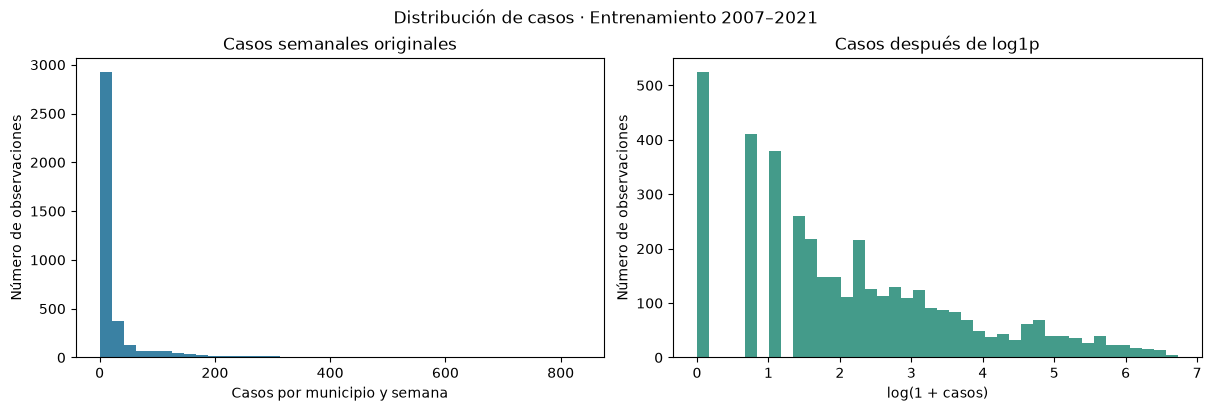

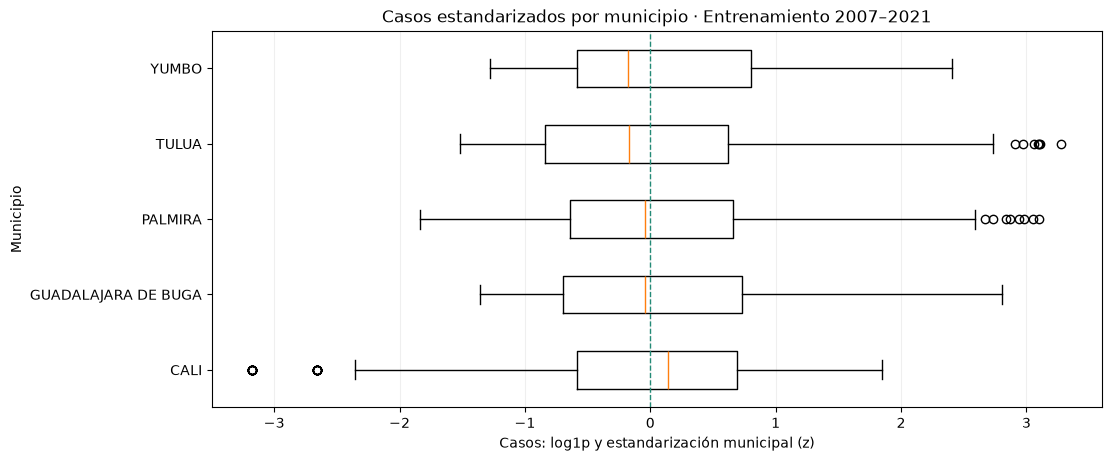

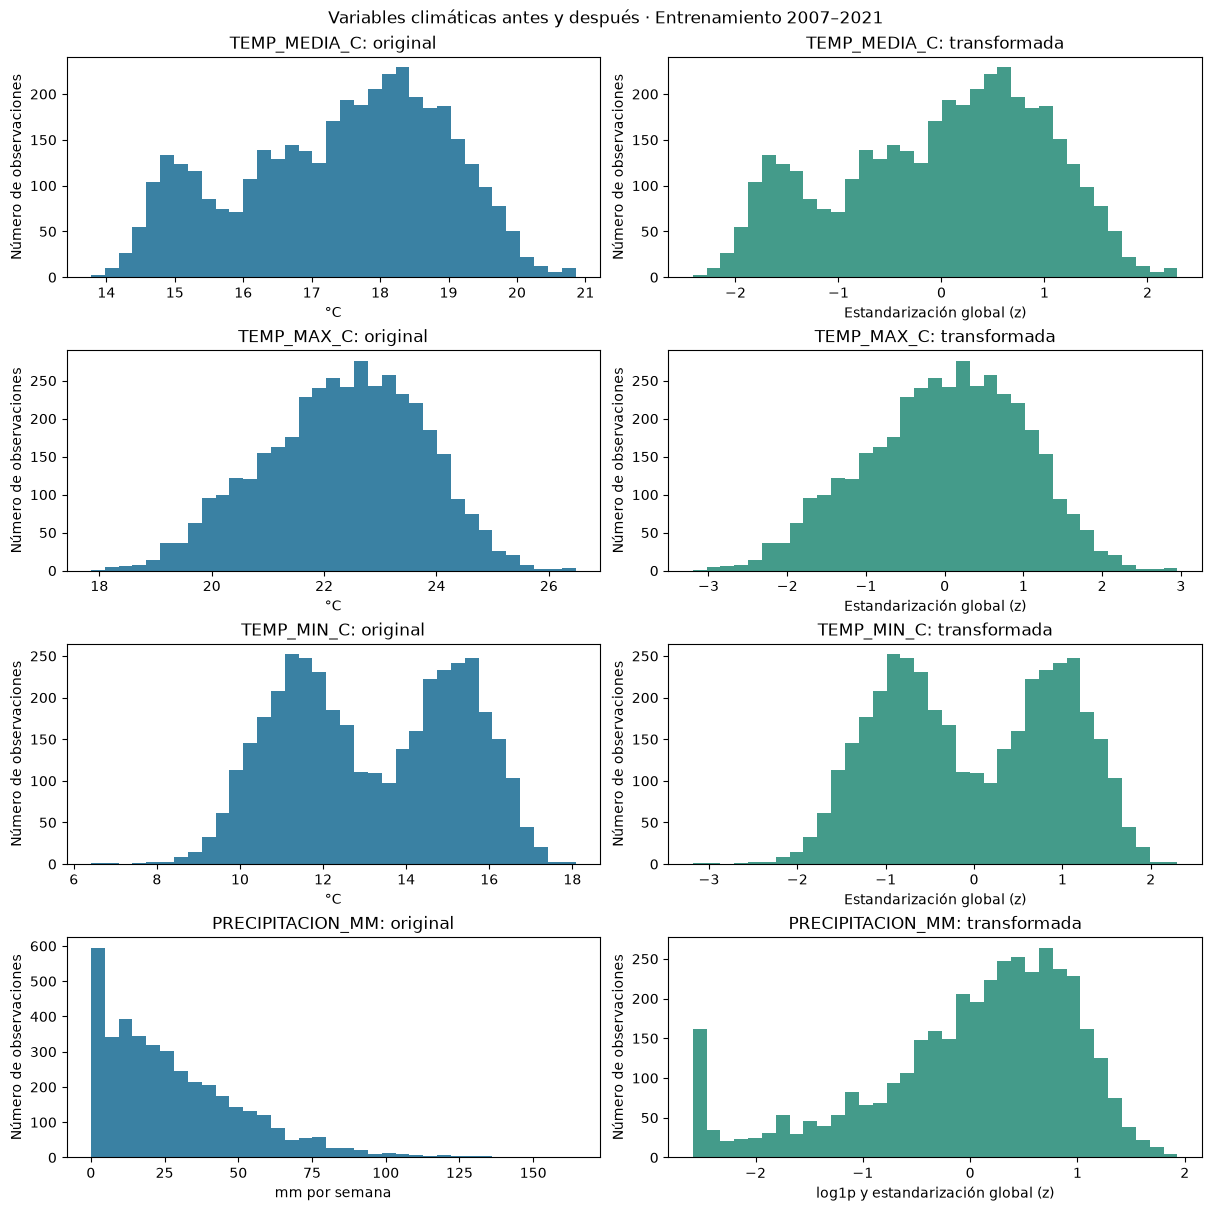

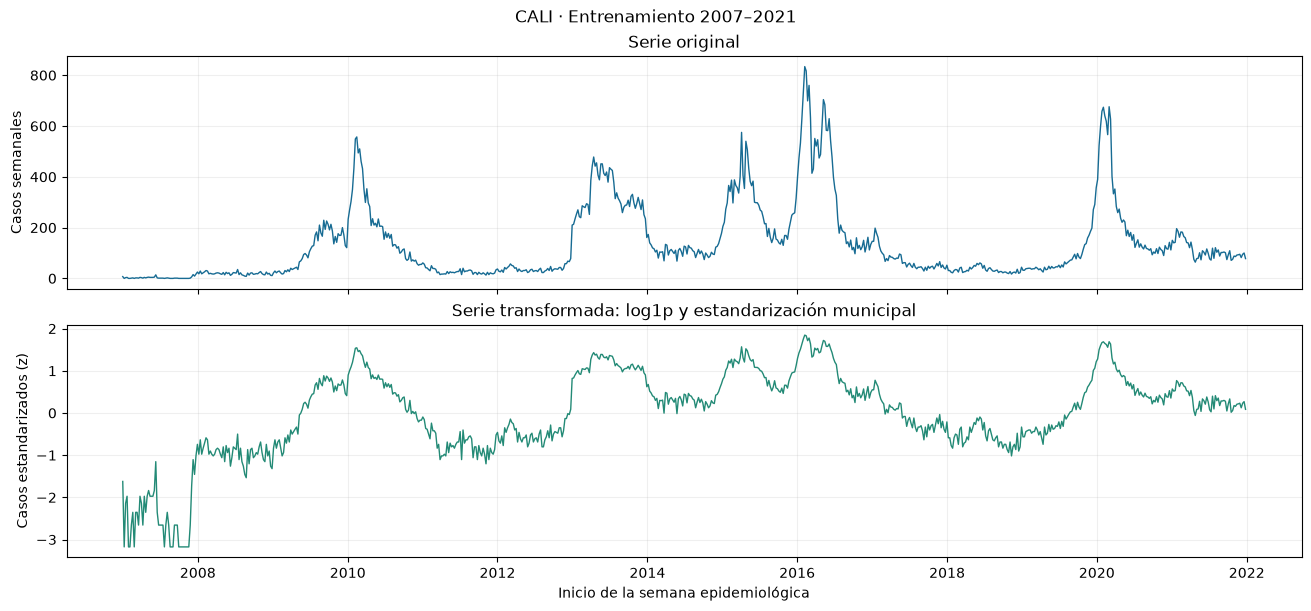

In [30]:
entrenamiento_graficas_lstm = df_lstm_entrenamiento
nombres_municipios_lstm = entrenamiento_graficas_lstm.groupby(ID_LSTM)['MUNICIPIO'].first().to_dict()
azul_lstm, verde_lstm = '#176B93', '#238A76'

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for eje, columna, titulo, etiqueta, color in [
    (ejes[0], 'CASOS', 'Casos semanales originales', 'Casos por municipio y semana', azul_lstm),
    (ejes[1], 'CASOS_log1p', 'Casos después de log1p', 'log(1 + casos)', verde_lstm),
]:
    eje.hist(entrenamiento_graficas_lstm[columna], bins=40, color=color, alpha=0.85)
    eje.set(title=titulo, xlabel=etiqueta, ylabel='Número de observaciones')
fig.suptitle('Distribución de casos · Entrenamiento 2007–2021')
plt.show()

fig, eje = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
eje.boxplot(
    [entrenamiento_graficas_lstm.loc[entrenamiento_graficas_lstm[ID_LSTM].eq(m), 'CASOS_std'] for m in orden_municipios_lstm],
    tick_labels=[nombres_municipios_lstm[m] for m in orden_municipios_lstm],
    orientation='horizontal',
)
eje.axvline(0, color=verde_lstm, linewidth=1, linestyle='--')
eje.set(title='Casos estandarizados por municipio · Entrenamiento 2007–2021', xlabel='Casos: log1p y estandarización municipal (z)', ylabel='Municipio')
eje.grid(axis='x', alpha=0.2)
plt.show()

fig, ejes = plt.subplots(len(CLIMA_LSTM), 2, figsize=(12, 12), constrained_layout=True)
for fila, columna in enumerate(CLIMA_LSTM):
    es_lluvia = columna == PRECIPITACION_LSTM
    unidad = 'mm por semana' if es_lluvia else '°C'
    etiqueta_transformada = 'log1p y estandarización global (z)' if es_lluvia else 'Estandarización global (z)'
    ejes[fila, 0].hist(entrenamiento_graficas_lstm[columna], bins=35, color=azul_lstm, alpha=0.85)
    ejes[fila, 0].set(title=f'{columna}: original', xlabel=unidad, ylabel='Número de observaciones')
    ejes[fila, 1].hist(entrenamiento_graficas_lstm[f'{columna}_std'], bins=35, color=verde_lstm, alpha=0.85)
    ejes[fila, 1].set(title=f'{columna}: transformada', xlabel=etiqueta_transformada, ylabel='Número de observaciones')
fig.suptitle('Variables climáticas antes y después · Entrenamiento 2007–2021')
plt.show()

municipio_grafica_lstm = orden_municipios_lstm[0]  # Cali (76001), presente en los datos.
serie_grafica_lstm = entrenamiento_graficas_lstm.loc[entrenamiento_graficas_lstm[ID_LSTM].eq(municipio_grafica_lstm)]
fig, ejes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
ejes[0].plot(serie_grafica_lstm['FECHA_INICIO'], serie_grafica_lstm['CASOS'], color=azul_lstm, linewidth=1)
ejes[0].set(title='Serie original', ylabel='Casos semanales')
ejes[1].plot(serie_grafica_lstm['FECHA_INICIO'], serie_grafica_lstm['CASOS_std'], color=verde_lstm, linewidth=1)
ejes[1].set(title='Serie transformada: log1p y estandarización municipal', xlabel='Inicio de la semana epidemiológica', ylabel='Casos estandarizados (z)')
for eje in ejes:
    eje.grid(alpha=0.2)
fig.suptitle(f'{nombres_municipios_lstm[municipio_grafica_lstm]} · Entrenamiento 2007–2021')
plt.show()


### 12.4. Datos y funciones disponibles para el modelado

Al terminar esta sección quedan disponibles los siguientes objetos. Sus nombres conservan el sufijo `lstm`, aunque sus transformaciones también se reutilizan en los demás modelos.

| Objeto | Contenido |
| --- | --- |
| `df_lstm_entrenamiento`, `df_lstm_validacion`, `df_lstm_test` | Tablas transformadas, separadas por periodo, con una fila por municipio y semana. |
| `conjuntos_transformados_lstm` | Las mismas tablas, agrupadas con las claves `training`, `validation` y `test`. |
| `columnas_entrada_lstm` | Siete entradas: casos, tres temperaturas, precipitación, seno y coseno de la semana, con las transformaciones descritas. |
| `columna_objetivo_lstm` | `CASOS_std`, la variable que aprenderán a pronosticar los modelos. |
| `escaladores_casos_lstm` | Los cinco escaladores de casos, identificados por `COD_DANE`. |
| `escaladores_clima_lstm` | Los escaladores de temperatura y precipitación. |
| `invertir_casos_lstm` | Función para recuperar el número de casos con el escalador municipal correspondiente. |
| `orden_municipios_lstm`, `semanas_por_ano_lstm` | Orden de los municipios y calendario de 52 o 53 semanas. |
| `auditoria_ajuste_lstm`, `verificacion_integridad_lstm`, `faltantes_lstm` | Comprobaciones del ajuste y de los datos transformados. |

Las columnas originales y los identificadores se conservan, pero las entradas numéricas del modelo son solo las indicadas en `columnas_entrada_lstm`. La representación del municipio para los modelos globales se incorpora en la preparación de secuencias del punto 13.


Las secuencias se forman por municipio: una ventana nunca debe continuar con las semanas de otra ciudad. Para pronosticar t+4 utilizamos información hasta t, sin añadir los casos ni el clima observado de las semanas futuras.

Los objetos de esta sección se crean en memoria. Después de reiniciar el kernel, esta parte puede recuperar los CSV semanales y ajustar de nuevo los escaladores con entrenamiento, sin releer los archivos anuales. El punto 13 utiliza estas transformaciones de la sesión para construir las secuencias; los modelos se entrenan después.


## 13. Construir las secuencias temporales

Cada ventana reúne las semanas anteriores de un solo municipio. La ventana avanza una semana y utiliza información hasta t para pronosticar los casos de **una semana específica, t+4**. No pronosticamos la suma de casos de un mes ni añadimos clima futuro.

Comparamos **8, 12, 16, 20 y 24 semanas**. Para que las historias tengan las mismas oportunidades, usamos los objetivos que permiten construir también la ventana más larga. Así quedan **3.780 ejemplos de entrenamiento y 505 de validación** para cada historia: 756 y 101 por municipio. Las ventanas se solapan, por lo que no son observaciones independientes.

Las siete variables temporales son casos, tres temperaturas, precipitación y seno/coseno de la semana epidemiológica. Los modelos globales reciben además el one-hot municipal; los locales trabajan con una ciudad fija. En este punto solo construimos las entradas y objetivos: todavía no se entrena ningún modelo.


In [31]:
codificador_municipios_actual = OneHotEncoder(sparse_output=False, handle_unknown='error', dtype=np.float32)
codificador_municipios_actual.fit(df_lstm_entrenamiento[['COD_DANE']])
secuencias_desarrollo = construir_secuencias(
    df_lstm_entrenamiento, df_lstm_validacion, columnas_entrada_lstm,
    codificador_municipios_actual, historias=HISTORIAS, horizonte=HORIZONTE,
)
preprocesamiento_actual = {
    'escaladores_casos': escaladores_casos_lstm,
    'escaladores_clima': escaladores_clima_lstm,
    'codificador_municipios': codificador_municipios_actual,
    'columnas_temporales': columnas_entrada_lstm.copy(),
    'orden_municipios': orden_municipios_lstm.copy(),
}
resumen_secuencias = pd.DataFrame([
    {'HISTORIA': v, 'CONJUNTO': conjunto, 'FORMA_X': str(datos['X'].shape),
     'FORMA_Y': str(datos['y'].shape), 'MATRIZ_BASELINE': str(datos['matriz'].shape),
     'PRIMER_OBJETIVO': datos['meta']['FECHA_OBJETIVO'].min(),
     'ULTIMO_OBJETIVO': datos['meta']['FECHA_OBJETIVO'].max()}
    for v, grupos in secuencias_desarrollo.items() for conjunto, datos in grupos.items()
])
display(resumen_secuencias)
print('Secuencias construidas. Todavía no se ha entrenado ningún modelo predictivo.')


,HISTORIA,CONJUNTO,FORMA_X,FORMA_Y,MATRIZ_BASELINE,PRIMER_OBJETIVO,ULTIMO_OBJETIVO
0,8,training,"(3780, 8, 7)","(3780, 1)","(3780, 61)",2007-07-08,2021-12-26
1,8,validation,"(505, 8, 7)","(505, 1)","(505, 61)",2022-01-23,2023-12-24
2,12,training,"(3780, 12, 7)","(3780, 1)","(3780, 89)",2007-07-08,2021-12-26
3,12,validation,"(505, 12, 7)","(505, 1)","(505, 89)",2022-01-23,2023-12-24
4,16,training,"(3780, 16, 7)","(3780, 1)","(3780, 117)",2007-07-08,2021-12-26
5,16,validation,"(505, 16, 7)","(505, 1)","(505, 117)",2022-01-23,2023-12-24
6,20,training,"(3780, 20, 7)","(3780, 1)","(3780, 145)",2007-07-08,2021-12-26
7,20,validation,"(505, 20, 7)","(505, 1)","(505, 145)",2022-01-23,2023-12-24
8,24,training,"(3780, 24, 7)","(3780, 1)","(3780, 173)",2007-07-08,2021-12-26
9,24,validation,"(505, 24, 7)","(505, 1)","(505, 173)",2022-01-23,2023-12-24


Secuencias construidas. Todavía no se ha entrenado ningún modelo predictivo.


## 14. Entrenar los modelos baseline

Antes de comparar las redes LSTM, necesitamos unas referencias para saber qué podemos conseguir con modelos más sencillos. Para eso entrenamos **regresión lineal, Random Forest y XGBoost**. Aquí los llamamos baselines porque serán nuestro punto de comparación; no estamos suponiendo que las redes necesariamente vayan a superarlos.

Cada modelo se entrena de forma global con los datos de los cinco municipios y se prueba con historias de **8, 12, 16, 20 y 24 semanas**. En total hacemos **quince ajustes**. Todos tienen un único objetivo: pronosticar los casos de la semana **t+4**, no los cuatro valores intermedios ni el total del mes.

### 14.1. Preparar las entradas de los baselines

Reutilizamos las secuencias del punto 13. Cada semana aporta siete variables: casos de dengue, temperaturas media, máxima y mínima, precipitación y seno y coseno de la semana epidemiológica. También añadimos los cinco indicadores del one-hot municipal, para que el modelo pueda distinguir de dónde viene cada ejemplo.

Estos modelos reciben una tabla, así que convertimos cada ventana en una fila. Las variables de cada semana conservan su posición: el modelo puede distinguir un dato reciente de otro más antiguo. El tensor original sigue disponible para las redes.

| Historia | Variables de la ventana | Indicadores municipales | Entradas por ejemplo |
| --- | --- | --- | --- |
| 8 semanas | 8 × 7 = 56 | 5 | 61 |
| 12 semanas | 12 × 7 = 84 | 5 | 89 |
| 16 semanas | 16 × 7 = 112 | 5 | 117 |
| 20 semanas | 20 × 7 = 140 | 5 | 145 |
| 24 semanas | 24 × 7 = 168 | 5 | 173 |

Dentro de cada historia, los tres modelos reciben exactamente las mismas entradas y objetivos. Las cinco historias también comparten las fechas que se van a pronosticar: 3.780 ejemplos de entrenamiento y 505 de validación.

### 14.2. Regresión lineal múltiple

La regresión lineal combina las entradas mediante una suma ponderada y un término constante. Durante el ajuste aprende cuánto peso darle a cada variable y a cada semana de la ventana, buscando reducir el error cuadrático en entrenamiento. Es múltiple porque utiliza varios predictores; su salida sigue siendo un solo valor para t+4.

Usamos **`LinearRegression()` con su configuración predeterminada**: incluye el término constante y no añade penalizaciones a los coeficientes. Nos permite revisar cuánto se puede explicar con una combinación lineal de la historia disponible. No incorpora por sí sola relaciones más complejas entre variables, como sí pueden hacerlo los árboles. Sus coeficientes describen el ajuste predictivo y no demuestran efectos causales del clima sobre el dengue.

### 14.3. Random Forest

Random Forest entrena varios árboles de decisión y promedia sus predicciones. Cada árbol aprende reglas a partir de distintas muestras del entrenamiento y de una selección de variables en sus divisiones. Esto permite representar relaciones no lineales e interacciones; por ejemplo, que una variable sea útil bajo ciertas condiciones de otra.

La configuración inicial es:

| Parámetro | Valor | Para qué se usa |
| --- | --- | --- |
| `n_estimators` | 300 | Cantidad de árboles cuyas predicciones se promedian. |
| `max_depth` | 12 | Limita la profundidad de cada árbol. |
| `min_samples_leaf` | 3 | Exige al menos tres ejemplos en cada hoja, para evitar reglas basadas en un solo registro. |
| `random_state` | 42 | Fija la semilla de las decisiones aleatorias del ajuste. |

Los árboles se ajustan únicamente con entrenamiento. La validación se utiliza después para comparar el desempeño de las tres historias; no decide una parada anticipada para este modelo.

### 14.4. XGBoost

XGBoost también combina árboles, pero los construye de manera sucesiva: cada nuevo árbol busca reducir los errores del conjunto que ya se ha formado. Su aporte se incorpora gradualmente, mediante una tasa de aprendizaje. Así podemos comparar el promedio de árboles de Random Forest con un enfoque que va corrigiendo su predicción paso a paso.

Conservamos esta configuración inicial:

| Parámetro | Valor | Para qué se usa |
| --- | --- | --- |
| `n_estimators` | 800 | Máximo de rondas de entrenamiento. |
| `max_depth` | 3 | Mantiene los árboles poco profundos. |
| `learning_rate` | 0,03 | Controla cuánto aporta cada nuevo árbol. |
| `min_child_weight` | 5 | Restringe las divisiones que tienen poco apoyo en los datos. |
| `subsample` | 0,80 | Usa una muestra del 80 % de los ejemplos de entrenamiento en cada ronda. |
| `colsample_bytree` | 0,80 | Usa una selección del 80 % de las columnas para construir cada árbol. |
| `reg_lambda` / `reg_alpha` | 1 / 0 | Aplica la penalización L2 y deja desactivada la L1. |
| `early_stopping_rounds` | 50 | Detiene el ajuste si el error de validación no mejora durante 50 rondas. |
| `random_state` | 42 | Fija la semilla del ajuste. |

Utilizamos el objetivo de error cuadrático, `reg:squarederror`. La parada anticipada se guía por **RMSE de validación en la escala transformada** y las predicciones se generan hasta la mejor ronda encontrada. El conjunto de evaluación no participa en esa decisión.

### 14.5. Entrenar y pasar a la comparación

Los tres modelos aprenden a predecir los casos con la transformación del punto 12: `log1p` y estandarización por municipio. Sus entradas también conservan las transformaciones ya realizadas. En el punto 15 deshacemos la transformación de la salida con el escalador correspondiente a cada municipio y calculamos MAE y RMSE en **casos de dengue**.

La celda siguiente llama a `fit` para cada modelo y después obtiene sus predicciones de entrenamiento y validación. Guarda los modelos y sus resultados en una carpeta nueva de esta ejecución. Estas configuraciones son el punto de partida; todavía no hacemos una búsqueda exhaustiva de hiperparámetros. La elección se apoya en validación y dejamos el conjunto de evaluación para el cierre del trabajo.


In [32]:
catalogo_arquitecturas = catalogo_redes()
RUTA_EJECUCION = nueva_ejecucion(preprocesamiento_actual, columnas_entrada_lstm, catalogo_arquitecturas)
modelos_baseline = {}
catalogo_baselines = []
tablas_predicciones_baseline = []
print('Nueva ejecución:', RUTA_EJECUCION.as_posix(), flush=True)

for historia in HISTORIAS:
    entrenamiento = secuencias_desarrollo[historia]['training']
    validacion = secuencias_desarrollo[historia]['validation']
    candidatos = [
        ('regresion_lineal', 'Regresión lineal', LinearRegression()),
        ('random_forest', 'Random Forest', RandomForestRegressor(
            n_estimators=300, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=4)),
        ('xgboost', 'XGBoost', XGBRegressor(**CONFIG_XGB)),
    ]
    for clave, familia, modelo in candidatos:
        identificador = f'{clave}_v{historia}'
        print(f'Entrenando {familia}, historia de {historia} semanas...', flush=True)
        if familia == 'XGBoost':
            modelo.fit(
                entrenamiento['matriz'], entrenamiento['y'].ravel(),
                eval_set=[(entrenamiento['matriz'], entrenamiento['y'].ravel()),
                          (validacion['matriz'], validacion['y'].ravel())], verbose=False,
            )
        else:
            modelo.fit(entrenamiento['matriz'], entrenamiento['y'].ravel())
        modelos_baseline[identificador] = modelo
        carpeta = RUTA_EJECUCION / 'modelos' / identificador
        carpeta.mkdir(exist_ok=False)
        archivo = carpeta / ('modelo.ubj' if familia == 'XGBoost' else 'modelo.joblib')
        if familia == 'XGBoost':
            modelo.save_model(archivo)
            progreso = modelo.evals_result()
            pd.DataFrame({'RMSE_TRAIN_STD': progreso['validation_0']['rmse'],
                          'RMSE_VAL_STD': progreso['validation_1']['rmse']}).to_csv(
                carpeta / 'historial.csv', index=False, encoding='utf-8-sig')
        else:
            joblib.dump(modelo, archivo)
        spec = {'ID': identificador, 'FAMILIA': familia, 'RECETA': 'baseline', 'HISTORIA': historia,
            'NOMBRE': f'{familia} · {historia}s', 'TIPO': 'xgboost' if familia == 'XGBoost' else 'sklearn',
            'CONFIG': CONFIG_XGB.copy() if familia == 'XGBoost' else modelo.get_params(),
            'ARCHIVO': archivo.as_posix(), 'HISTORIAL': None, 'MATRIZ': False,
            'PARAMETROS_RED': None, 'N_ENTRENAMIENTO': len(entrenamiento['X']),
            'ENTRENADO_EN_ESTA_EJECUCION': True, 'EJECUCION': RUTA_EJECUCION.name}
        catalogo_baselines.append(spec)
        for conjunto, datos in [('training', entrenamiento), ('validation', validacion)]:
            if familia == 'XGBoost':
                pred = modelo.predict(datos['matriz'], iteration_range=(0, modelo.best_iteration+1))
            else:
                pred = modelo.predict(datos['matriz'])
            tablas_predicciones_baseline.append(tabla_predicciones(
                spec, datos, pred.reshape(-1, 1), preprocesamiento_actual, conjunto))
        print(f'  {familia} entrenado; predicciones de train y validation calculadas.', flush=True)
predicciones_baselines = pd.concat(tablas_predicciones_baseline, ignore_index=True)


Nueva ejecución: ResultadosModelos/entrenamiento_en_notebook/ejecucion_5a3d407a


Entrenando Regresión lineal, historia de 8 semanas...


  Regresión lineal entrenado; predicciones de train y validation calculadas.


Entrenando Random Forest, historia de 8 semanas...


  Random Forest entrenado; predicciones de train y validation calculadas.


Entrenando XGBoost, historia de 8 semanas...


... (21 outputs left out)

Entrenando Random Forest, historia de 24 semanas...


  Random Forest entrenado; predicciones de train y validation calculadas.


Entrenando XGBoost, historia de 24 semanas...


  XGBoost entrenado; predicciones de train y validation calculadas.


## 15. Evaluar los baselines en validación

Estas métricas se calculan con las predicciones de los nueve modelos que acabamos de entrenar. Primero deshacemos las transformaciones con el escalador de cada municipio. MAE mide el error absoluto promedio en casos y RMSE da más peso a los errores grandes.

La selección se hace con validación. Los errores de entrenamiento ayudan a revisar el ajuste. En las series mostramos, para cada familia, la historia con menor MAE general de validación y mantenemos ese mismo modelo en los cinco municipios.


MODELO,CONJUNTO,N,MAE,RMSE
Regresión lineal · 8s,training,3780,10.634,31.885
Regresión lineal · 8s,validation,505,14.961,37.249
Random Forest · 8s,training,3780,5.506,16.029
Random Forest · 8s,validation,505,16.086,40.751
XGBoost · 8s,training,3780,8.487,25.194
XGBoost · 8s,validation,505,15.487,38.723
Regresión lineal · 12s,training,3780,10.626,31.421
Regresión lineal · 12s,validation,505,14.841,36.872
Random Forest · 12s,training,3780,5.359,15.820
Random Forest · 12s,validation,505,15.732,39.871


MODELO,MUNICIPIO,N,MAE,RMSE
Regresión lineal · 8s,CALI,101,39.758,61.929
Regresión lineal · 8s,GUADALAJARA DE BUGA,101,1.879,3.629
Regresión lineal · 8s,PALMIRA,101,21.427,51.810
Regresión lineal · 8s,TULUA,101,3.527,7.154
Regresión lineal · 8s,YUMBO,101,8.216,18.809
Random Forest · 8s,CALI,101,40.827,64.956
Random Forest · 8s,GUADALAJARA DE BUGA,101,2.002,3.821
Random Forest · 8s,PALMIRA,101,24.935,60.195
Random Forest · 8s,TULUA,101,3.352,6.521
Random Forest · 8s,YUMBO,101,9.312,20.081


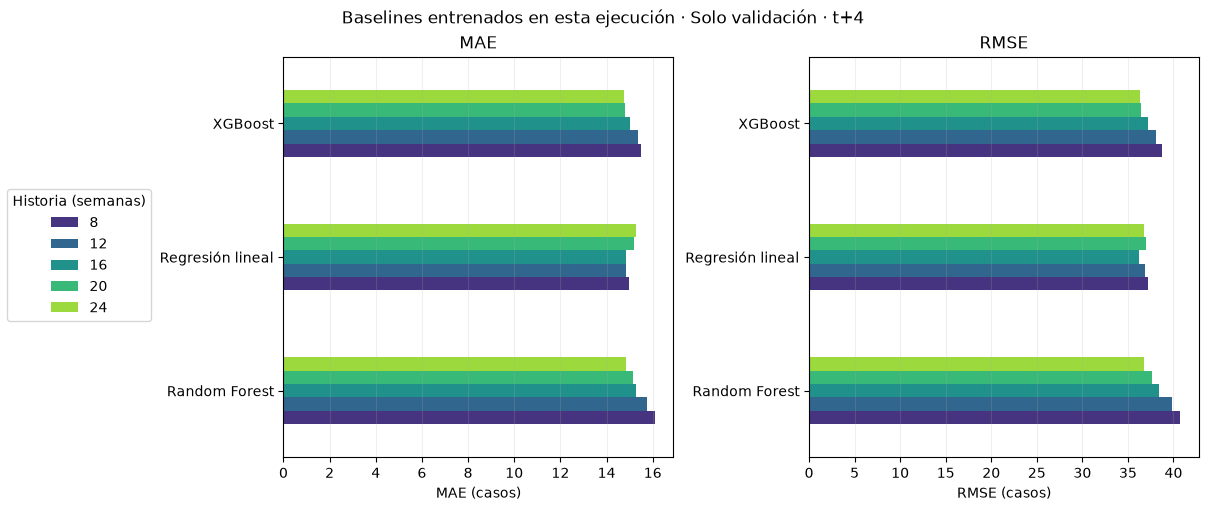

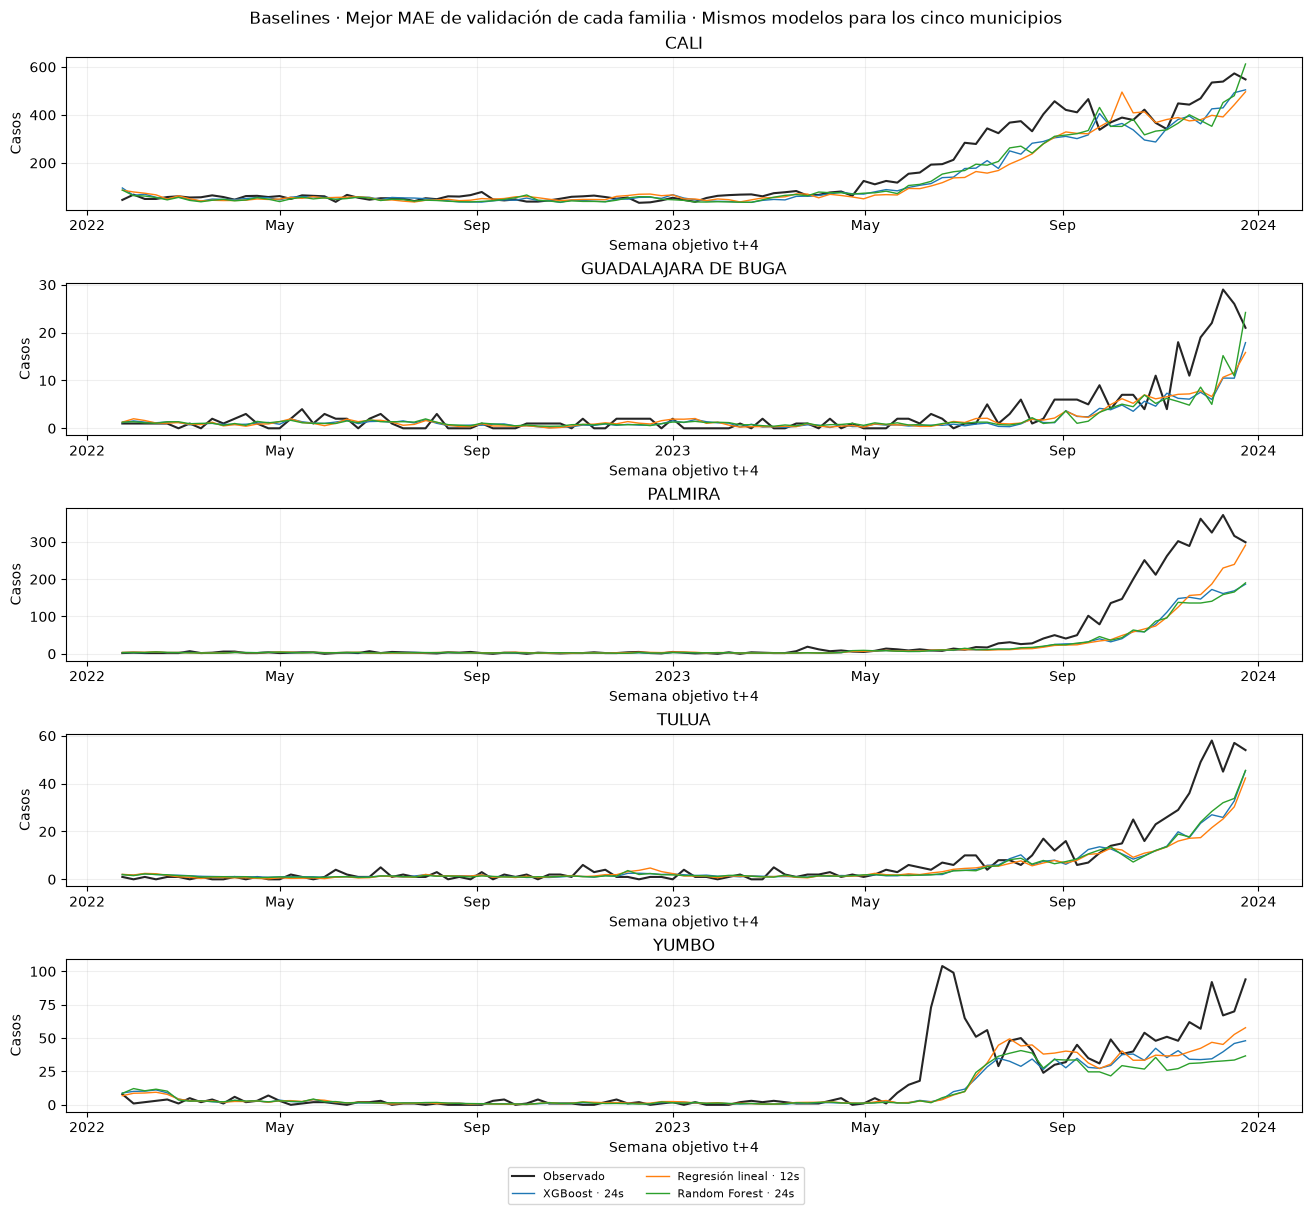

In [33]:
metricas_baselines, metricas_municipales_baselines, ranking_baselines = resumir_predicciones(
    predicciones_baselines, catalogo_baselines)
display(metricas_baselines[['MODELO','CONJUNTO','N','MAE','RMSE']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))
display(metricas_municipales_baselines.loc[
    metricas_municipales_baselines['CONJUNTO'].eq('validation'),
    ['MODELO','MUNICIPIO','N','MAE','RMSE']].style.format({'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))
graficar_baselines(predicciones_baselines, ranking_baselines, RUTA_EJECUCION)
exportar_resultados_actuales(RUTA_EJECUCION, predicciones_baselines, metricas_baselines,
    metricas_municipales_baselines, ranking_baselines, catalogo_baselines)


## 16. Definir las arquitecturas LSTM

Comparamos redes globales, que aprenden con los cinco municipios juntos, y redes locales, que se ajustan por separado para cada municipio. Todas entregan un solo valor para t+4.

### 16.1. Cómo llega la historia a la salida

La LSTM resume la historia semanal. En los modelos globales unimos ese resumen con los cinco indicadores del municipio y después lo pasamos a la salida. Puede haber una Dense intermedia para combinar esa información antes del pronóstico.

Por ejemplo, la referencia global sigue este recorrido: **LSTM32 → unir one-hot municipal → Dense16 con ReLU → Dense1 lineal**. La variante sin Dense intermedia conecta el resumen y el municipio directamente con Dense1. Por tanto, quitar la Dense intermedia no elimina la capa de salida.

### 16.2. Redes globales

| Estructura | Unidades LSTM | Dense intermedia | Dropout después de cada LSTM | Historias | Ajustes |
| --- | --- | --- | --- | --- | --- |
| Referencia | 32 | 16 | 0 | 8, 12, 16, 20 y 24 | 5 |
| Sin Dense intermedia | 32 | No se añade | 0 | Las cinco | 5 |
| Dropout de 0,20 | 32 | 16 | 0,20 | Las cinco | 5 |
| Dropout de 0,50 | 32 | 16 | 0,50 | Las cinco | 5 |
| Dos capas | 32 → 16 | 16 | 0,20 | Las cinco | 5 |
| Tres capas | 32 → 16 → 8 | 16 | 0,20 | Las cinco | 5 |
| Reducida | 16 | 8 | 0 | Las cinco | 5 |
| LSTM64 de referencia | 64 | 16 | 0 | Las cinco | 5 |
| LSTM64 con Dropout | 64 | 16 | 0,20 | Las cinco | 5 |
| LSTM64 con Dense8 | 64 | 8 | 0 | Las cinco | 5 |
| LSTM64 con Dense8 y Dropout | 64 | 8 | 0,20 | Las cinco | 5 |
| LSTM64 sin Dense intermedia | 64 | No se añade | 0 | Las cinco | 5 |
| LSTM64 sin Dense intermedia y con Dropout | 64 | No se añade | 0,20 | Las cinco | 5 |
| Referencia adicional de dos capas | 32 → 32 | 16 | 0 | Las cinco | 5 |

Son **70 redes globales**. Todas las estructuras globales se prueban con las cinco historias, incluidas las referencias de 64 unidades y de dos capas de 32.

Dropout pone en cero parte de las activaciones durante entrenamiento y se desactiva al pronosticar. No damos por hecho que una red con Dropout, más capas o más unidades vaya a tener menor error: eso se revisa en validación. En las variantes profundas cambian a la vez las capas y el Dropout.

Las seis opciones de 64 unidades mantienen una sola capa LSTM. Con Dense16 tienen **19.569 parámetros**; con Dense8, **19.001**; sin Dense intermedia, **18.502**. Dropout no añade ni quita parámetros. La LSTM concentra 18.432, así que reducir la Dense cambia poco el tamaño total. Todas conservan la salida Dense1 y el one-hot municipal.

### 16.3. Redes locales

Cada municipio tiene su propia red y no necesita one-hot. Las tres estructuras conservan Dropout en cero y se prueban con las cinco historias.

| Estructura | Parámetros por red | Redes entrenadas |
| --- | --- | --- |
| LSTM32 → Dense16 → Dense1 | 5.665 | 25 |
| LSTM16 → Dense8 → Dense1 | 1.681 | 25 |
| LSTM8 → Dense4 → Dense1 | 553 | 25 |

Cada estructura e historia reúne cinco redes para calcular un resultado general. Esto da **15 enfoques locales y 75 redes individuales**. Cada red recibe 756 ventanas de entrenamiento y 101 de validación. Reducir parámetros es una alternativa que debemos comprobar; no garantiza que se elimine el sobreajuste.

### 16.4. Alcance de la comparación

En total entrenamos **145 redes**: 70 globales y 75 locales. Sus predicciones forman 85 enfoques recurrentes. Al añadir los 15 baselines quedan **100 enfoques y 160 ajustes predictivos**. La selección final se hace exclusivamente por el menor MAE general de validación.


In [34]:
estructuras_mostradas = [{'MODELO':s['NOMBRE'], 'UNIDADES':' → '.join(map(str,s['CONFIG']['unidades'])),
    'DENSE_INTERMEDIA':s['CONFIG']['dense'], 'DROPOUT':s['CONFIG']['dropout'], 'TIPO':s['TIPO']}
    for s in catalogo_arquitecturas if s['HISTORIA']==HISTORIAS[0]]
display(pd.DataFrame(estructuras_mostradas))
modelos_recurrentes = {s['ID']: {**s, 'ARCHIVO': {} if s['TIPO']=='local' else None,
    'HISTORIAL': None, 'N_ENTRENAMIENTO': len(secuencias_desarrollo[s['HISTORIA']]['training']['X']),
    'ENTRENADO_EN_ESTA_EJECUCION': False, 'EJECUCION': RUTA_EJECUCION.name}
    for s in catalogo_arquitecturas}
predicciones_redes_individuales = {}
historiales_recurrentes = {}
registro_redes_actuales = {}
display(pd.DataFrame(catalogo_arquitecturas)[['NOMBRE','HISTORIA','TIPO']])


,MODELO,UNIDADES,DENSE_INTERMEDIA,DROPOUT,TIPO
0,LSTM 32 · Dense16 · D0 · 8s,32,16,0.0,red
1,LSTM 32 · sin Dense intermedia · 8s,32,0,0.0,red
2,"LSTM 32 · Dense16 · D0,20 · 8s",32,16,0.2,red
3,"LSTM 32 · Dense16 · D0,50 · 8s",32,16,0.5,red
4,"LSTM 32→16 · Dense16 · D0,20 · 8s",32 → 16,16,0.2,red
5,"LSTM 32→16→8 · Dense16 · D0,20 · 8s",32 → 16 → 8,16,0.2,red
6,"LSTM 64 · Dense16 · D0,0 · 8s",64,16,0.0,red
7,"LSTM 64 · Dense16 · D0,2 · 8s",64,16,0.2,red
8,"LSTM 64 · Dense8 · D0,0 · 8s",64,8,0.0,red
9,"LSTM 64 · Dense8 · D0,2 · 8s",64,8,0.2,red


,NOMBRE,HISTORIA,TIPO
0,LSTM 32 · Dense16 · D0 · 8s,8,red
1,LSTM 32 · sin Dense intermedia · 8s,8,red
2,"LSTM 32 · Dense16 · D0,20 · 8s",8,red
3,"LSTM 32 · Dense16 · D0,50 · 8s",8,red
4,"LSTM 32→16 · Dense16 · D0,20 · 8s",8,red
...,...,...,...
80,LSTM local 8 · Dense4 (5 redes) · 8s,8,local
81,LSTM local 8 · Dense4 (5 redes) · 12s,12,local
82,LSTM local 8 · Dense4 (5 redes) · 16s,16,local
83,LSTM local 8 · Dense4 (5 redes) · 20s,20,local


## 17. Entrenar las LSTM

Todas las redes empiezan con pesos nuevos. Usamos semilla 42, Adam con tasa de 0,001, lotes de 32, **hasta 200 épocas** y orden temporal sin barajar. EarlyStopping conserva los pesos con menor MSE de validación y detiene el ajuste tras **20 épocas sin mejora**. La tasa se reduce a la mitad tras cinco épocas sin mejora, hasta un mínimo de 0,00001.

Ampliamos el límite porque 16 redes de la corrida anterior alcanzaron las 100 épocas. La LSTM64 se había detenido antes, entre las épocas 33 y 47; por eso también ampliamos la paciencia. Dar más tiempo permite comprobar si aparece una mejora posterior, sin asumir que entrenar más vaya a mejorar el pronóstico.

Aplicamos esta regla a **todas las LSTM globales y locales** y volvemos a entrenarlas. Así, las nuevas opciones de 64 unidades no reciben un presupuesto distinto al de las otras redes. Los baselines conservan sus configuraciones.

La función siguiente contiene la llamada a entrenamiento. Después calcula las predicciones de entrenamiento y validación y guarda los mejores pesos. La época se escoge con la pérdida transformada; la comparación entre modelos utiliza MAE en casos, después de invertir las transformaciones.


In [35]:
def entrenar_red_en_notebook(spec, codigo=None):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(42)
    tf.config.experimental.enable_op_determinism()
    historia = spec['HISTORIA']
    local = spec['TIPO']=='local'
    entrenamiento = secuencias_desarrollo[historia]['training']
    validacion = secuencias_desarrollo[historia]['validation']
    if local:
        entrenamiento = datos_municipales(entrenamiento, codigo)
        validacion = datos_municipales(validacion, codigo)
    id_red = spec['ID'] + (f'_{codigo}' if local else '')
    carpeta = RUTA_EJECUCION / 'modelos' / id_red
    carpeta.mkdir(exist_ok=True)
    archivo = carpeta / 'mejor_modelo.keras'
    modelo = crear_red({**spec, 'ID': id_red}, len(columnas_entrada_lstm), len(orden_municipios_lstm))
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001), loss='mse', metrics=['mae'])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=PACIENCIA_ES, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', patience=5, factor=.5, min_lr=1e-5),
        tf.keras.callbacks.ModelCheckpoint(str(archivo), monitor='val_loss', mode='min', save_best_only=True),
        tf.keras.callbacks.CSVLogger(str(carpeta / 'progreso.csv')),
        tf.keras.callbacks.TerminateOnNaN(),
    ]
    print(f'Entrenando {id_red} ({len(entrenamiento["X"])} ejemplos)...', flush=True)
    historia_ajuste = modelo.fit(
        dataset_red(entrenamiento, local=local),
        validation_data=dataset_red(validacion, local=local),
        epochs=EPOCAS_MAX, shuffle=False, callbacks=callbacks, verbose=0,
    )
    h = pd.DataFrame(historia_ajuste.history)
    h.insert(0, 'EPOCA', np.arange(1, len(h)+1))
    assert np.isfinite(h[['loss','val_loss']].to_numpy()).all()
    h.to_csv(carpeta / 'historial.csv', index=False, encoding='utf-8-sig')
    tablas = []
    for conjunto, datos in [('training', entrenamiento), ('validation', validacion)]:
        pred = predecir_red_actual(modelo, datos, local=local)
        if conjunto=='validation':
            np.testing.assert_allclose(np.mean((pred-datos['y'])**2), h['val_loss'].min(), rtol=2e-5, atol=2e-6)
        t = tabla_predicciones(spec, datos, pred, preprocesamiento_actual, conjunto)
        t['ID_RED'] = id_red
        tablas.append(t)
    predicciones_redes_individuales[id_red] = pd.concat(tablas, ignore_index=True)
    historiales_recurrentes[id_red] = h
    registro_redes_actuales[id_red] = {
        'ID_RED': id_red, 'ID_ENFOQUE': spec['ID'], 'COD_DANE': codigo,
        'N_TRAIN': len(entrenamiento['X']), 'N_VAL': len(validacion['X']),
        'PARAMETROS': int(modelo.count_params()), 'MEJOR_EPOCA': int(h['val_loss'].idxmin())+1,
        'EPOCAS_EJECUTADAS': len(h), 'ARCHIVO': archivo.as_posix(),
    }
    if local:
        spec['ARCHIVO'][codigo] = archivo.as_posix()
        filas = [r for r in registro_redes_actuales.values() if r['ID_ENFOQUE']==spec['ID']]
        spec['PARAMETROS_RED'] = sum(r['PARAMETROS'] for r in filas)
        spec['ENTRENADO_EN_ESTA_EJECUCION'] = len(spec['ARCHIVO'])==len(orden_municipios_lstm)
    else:
        spec.update(ARCHIVO=archivo.as_posix(), HISTORIAL=(carpeta/'historial.csv').as_posix(),
            PARAMETROS_RED=int(modelo.count_params()), ENTRENADO_EN_ESTA_EJECUCION=True,
            MEJOR_PASO=int(h['val_loss'].idxmin())+1, PASOS_EJECUTADOS=len(h))
    pd.DataFrame(registro_redes_actuales.values()).to_csv(
        RUTA_EJECUCION / 'tablas/registro_entrenamiento_redes.csv', index=False, encoding='utf-8-sig')
    print(f'  Ajuste terminado: mejor época {int(h["val_loss"].idxmin())+1}, de {len(h)} ejecutadas.', flush=True)
    del modelo
    tf.keras.backend.clear_session()
    gc.collect()


### 17.1. Entrenar la matriz de LSTM globales

Entrenamos las seis estructuras principales para cada historia. Cada ajuste usa los cinco municipios y sus indicadores one-hot.

In [36]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==8:
        entrenar_red_en_notebook(spec)

Entrenando lstm_referencia_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 61, de 81 ejecutadas.


Entrenando lstm_sin_dense_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 30, de 50 ejecutadas.


Entrenando lstm_drop20_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 35, de 55 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 33, de 53 ejecutadas.


Entrenando lstm_tres_capas_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 55, de 75 ejecutadas.


In [37]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==12:
        entrenar_red_en_notebook(spec)

Entrenando lstm_referencia_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 35, de 55 ejecutadas.


Entrenando lstm_sin_dense_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 34, de 54 ejecutadas.


Entrenando lstm_drop20_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 35, de 55 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 28, de 48 ejecutadas.


Entrenando lstm_tres_capas_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 41, de 61 ejecutadas.


In [38]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==16:
        entrenar_red_en_notebook(spec)

Entrenando lstm_referencia_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 28, de 48 ejecutadas.


Entrenando lstm_sin_dense_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 29, de 49 ejecutadas.


Entrenando lstm_drop20_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 38, de 58 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 32, de 52 ejecutadas.


Entrenando lstm_tres_capas_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 30, de 50 ejecutadas.


In [39]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==20:
        entrenar_red_en_notebook(spec)

Entrenando lstm_referencia_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 27, de 47 ejecutadas.


Entrenando lstm_sin_dense_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 27, de 47 ejecutadas.


Entrenando lstm_drop20_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 40, de 60 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 22, de 42 ejecutadas.


Entrenando lstm_tres_capas_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 20, de 40 ejecutadas.


In [40]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==24:
        entrenar_red_en_notebook(spec)

Entrenando lstm_referencia_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 26, de 46 ejecutadas.


Entrenando lstm_sin_dense_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 32, de 52 ejecutadas.


Entrenando lstm_drop20_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 41, de 61 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 25, de 45 ejecutadas.


Entrenando lstm_tres_capas_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 43, de 63 ejecutadas.


### 17.2. Entrenar las variantes LSTM64 y las referencias adicionales

Entrenamos las seis opciones de LSTM64 con las cinco historias: Dense16, Dense8 y sin Dense intermedia, cada una con Dropout de 0 y 0,20. También ajustamos LSTM16 + Dense8 y la referencia de dos capas de 32. En total son 40 redes globales en este bloque.


In [41]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and not spec['MATRIZ'] and spec['HISTORIA']==8:
        entrenar_red_en_notebook(spec)

Entrenando lstm_adicional_B64_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 29, de 49 ejecutadas.


Entrenando lstm_64_dense16_drop20_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 39, de 59 ejecutadas.


Entrenando lstm_64_dense8_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 34, de 54 ejecutadas.


... (6 outputs left out)

Entrenando lstm_adicional_D32x2_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 14, de 34 ejecutadas.


Entrenando lstm_compacta16_8_v8 (3780 ejemplos)...


  Ajuste terminado: mejor época 98, de 118 ejecutadas.


In [42]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and not spec['MATRIZ'] and spec['HISTORIA']==12:
        entrenar_red_en_notebook(spec)

Entrenando lstm_adicional_B64_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 23, de 43 ejecutadas.


Entrenando lstm_64_dense16_drop20_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 21, de 41 ejecutadas.


Entrenando lstm_64_dense8_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 22, de 42 ejecutadas.


... (6 outputs left out)

Entrenando lstm_adicional_D32x2_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 13, de 33 ejecutadas.


Entrenando lstm_compacta16_8_v12 (3780 ejemplos)...


  Ajuste terminado: mejor época 84, de 104 ejecutadas.


In [43]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and not spec['MATRIZ'] and spec['HISTORIA']==16:
        entrenar_red_en_notebook(spec)

Entrenando lstm_adicional_B64_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 26, de 46 ejecutadas.


Entrenando lstm_64_dense16_drop20_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 21, de 41 ejecutadas.


Entrenando lstm_64_dense8_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 20, de 40 ejecutadas.


... (6 outputs left out)

Entrenando lstm_adicional_D32x2_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 10, de 30 ejecutadas.


Entrenando lstm_compacta16_8_v16 (3780 ejemplos)...


  Ajuste terminado: mejor época 62, de 82 ejecutadas.


In [44]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and not spec['MATRIZ'] and spec['HISTORIA']==20:
        entrenar_red_en_notebook(spec)

Entrenando lstm_adicional_B64_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 30, de 50 ejecutadas.


Entrenando lstm_64_dense16_drop20_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 35, de 55 ejecutadas.


Entrenando lstm_64_dense8_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 24, de 44 ejecutadas.


... (6 outputs left out)

Entrenando lstm_adicional_D32x2_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 12, de 32 ejecutadas.


Entrenando lstm_compacta16_8_v20 (3780 ejemplos)...


  Ajuste terminado: mejor época 99, de 119 ejecutadas.


In [45]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and not spec['MATRIZ'] and spec['HISTORIA']==24:
        entrenar_red_en_notebook(spec)

Entrenando lstm_adicional_B64_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 37, de 57 ejecutadas.


Entrenando lstm_64_dense16_drop20_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 35, de 55 ejecutadas.


Entrenando lstm_64_dense8_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 29, de 49 ejecutadas.


... (6 outputs left out)

Entrenando lstm_adicional_D32x2_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 18, de 38 ejecutadas.


Entrenando lstm_compacta16_8_v24 (3780 ejemplos)...


  Ajuste terminado: mejor época 42, de 62 ejecutadas.


### 17.3. Entrenar las LSTM locales de referencia

Ajustamos LSTM32 + Dense16 por separado para cada municipio e historia. Cada conjunto de cinco redes se compara sobre las mismas fechas objetivo.

In [46]:
spec_local = modelos_recurrentes['local_v8']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_v8_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 9, de 29 ejecutadas.


Entrenando local_v8_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 86, de 106 ejecutadas.


Entrenando local_v8_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 16, de 36 ejecutadas.


Entrenando local_v8_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 18, de 38 ejecutadas.


Entrenando local_v8_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 151, de 171 ejecutadas.


In [47]:
spec_local = modelos_recurrentes['local_v12']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_v12_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 14, de 34 ejecutadas.


Entrenando local_v12_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 29, de 49 ejecutadas.


Entrenando local_v12_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 40, de 60 ejecutadas.


Entrenando local_v12_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 15, de 35 ejecutadas.


Entrenando local_v12_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 28, de 48 ejecutadas.


In [48]:
spec_local = modelos_recurrentes['local_v16']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_v16_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 87, de 107 ejecutadas.


Entrenando local_v16_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 27, de 47 ejecutadas.


Entrenando local_v16_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 40, de 60 ejecutadas.


Entrenando local_v16_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 14, de 34 ejecutadas.


Entrenando local_v16_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 28, de 48 ejecutadas.


In [49]:
spec_local = modelos_recurrentes['local_v20']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_v20_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 43, de 63 ejecutadas.


Entrenando local_v20_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 22, de 42 ejecutadas.


Entrenando local_v20_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 25, de 45 ejecutadas.


Entrenando local_v20_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 14, de 34 ejecutadas.


Entrenando local_v20_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 23, de 43 ejecutadas.


In [50]:
spec_local = modelos_recurrentes['local_v24']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_v24_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 47, de 67 ejecutadas.


Entrenando local_v24_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 20, de 40 ejecutadas.


Entrenando local_v24_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 23, de 43 ejecutadas.


Entrenando local_v24_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 18, de 38 ejecutadas.


Entrenando local_v24_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 22, de 42 ejecutadas.


#### 17.3.1. Entrenar los locales de menor tamaño

Repetimos el ajuste con LSTM16 + Dense8 y LSTM8 + Dense4 para las cinco historias. Son 50 redes: cada estructura e historia tiene cinco modelos municipales. Conservamos Dropout en cero y las mismas reglas de entrenamiento que en la referencia.

In [51]:
spec_local = modelos_recurrentes['local_compacta16_8_v8']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta16_8_v8_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 18, de 38 ejecutadas.


Entrenando local_compacta16_8_v8_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 12, de 32 ejecutadas.


Entrenando local_compacta16_8_v8_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 52, de 72 ejecutadas.


Entrenando local_compacta16_8_v8_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 54, de 74 ejecutadas.


Entrenando local_compacta16_8_v8_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 40, de 60 ejecutadas.


In [52]:
spec_local = modelos_recurrentes['local_compacta16_8_v12']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta16_8_v12_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 15, de 35 ejecutadas.


Entrenando local_compacta16_8_v12_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 11, de 31 ejecutadas.


Entrenando local_compacta16_8_v12_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 48, de 68 ejecutadas.


Entrenando local_compacta16_8_v12_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 30, de 50 ejecutadas.


Entrenando local_compacta16_8_v12_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 137, de 157 ejecutadas.


In [53]:
spec_local = modelos_recurrentes['local_compacta16_8_v16']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta16_8_v16_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 19, de 39 ejecutadas.


Entrenando local_compacta16_8_v16_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 10, de 30 ejecutadas.


Entrenando local_compacta16_8_v16_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 50, de 70 ejecutadas.


Entrenando local_compacta16_8_v16_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 139, de 159 ejecutadas.


Entrenando local_compacta16_8_v16_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 200, de 200 ejecutadas.


In [54]:
spec_local = modelos_recurrentes['local_compacta16_8_v20']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta16_8_v20_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 93, de 113 ejecutadas.


Entrenando local_compacta16_8_v20_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 49, de 69 ejecutadas.


Entrenando local_compacta16_8_v20_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 56, de 76 ejecutadas.


Entrenando local_compacta16_8_v20_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 51, de 71 ejecutadas.


Entrenando local_compacta16_8_v20_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 77, de 97 ejecutadas.


In [55]:
spec_local = modelos_recurrentes['local_compacta16_8_v24']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta16_8_v24_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 83, de 103 ejecutadas.


Entrenando local_compacta16_8_v24_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 75, de 95 ejecutadas.


Entrenando local_compacta16_8_v24_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 58, de 78 ejecutadas.


Entrenando local_compacta16_8_v24_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 34, de 54 ejecutadas.


Entrenando local_compacta16_8_v24_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 70, de 90 ejecutadas.


In [56]:
spec_local = modelos_recurrentes['local_compacta8_4_v8']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta8_4_v8_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 47, de 67 ejecutadas.


Entrenando local_compacta8_4_v8_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 200, de 200 ejecutadas.


Entrenando local_compacta8_4_v8_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 161, de 181 ejecutadas.


Entrenando local_compacta8_4_v8_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 200, de 200 ejecutadas.


Entrenando local_compacta8_4_v8_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 117, de 137 ejecutadas.


In [57]:
spec_local = modelos_recurrentes['local_compacta8_4_v12']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta8_4_v12_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 65, de 85 ejecutadas.


Entrenando local_compacta8_4_v12_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 44, de 64 ejecutadas.


Entrenando local_compacta8_4_v12_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 158, de 178 ejecutadas.


Entrenando local_compacta8_4_v12_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 49, de 69 ejecutadas.


Entrenando local_compacta8_4_v12_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 36, de 56 ejecutadas.


In [58]:
spec_local = modelos_recurrentes['local_compacta8_4_v16']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta8_4_v16_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 77, de 97 ejecutadas.


Entrenando local_compacta8_4_v16_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 96, de 116 ejecutadas.


Entrenando local_compacta8_4_v16_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 102, de 122 ejecutadas.


Entrenando local_compacta8_4_v16_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 50, de 70 ejecutadas.


Entrenando local_compacta8_4_v16_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 172, de 192 ejecutadas.


In [59]:
spec_local = modelos_recurrentes['local_compacta8_4_v20']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta8_4_v20_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 86, de 106 ejecutadas.


Entrenando local_compacta8_4_v20_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 85, de 105 ejecutadas.


Entrenando local_compacta8_4_v20_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 108, de 128 ejecutadas.


Entrenando local_compacta8_4_v20_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 47, de 67 ejecutadas.


Entrenando local_compacta8_4_v20_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 135, de 155 ejecutadas.


In [60]:
spec_local = modelos_recurrentes['local_compacta8_4_v24']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)

Entrenando local_compacta8_4_v24_76001 (756 ejemplos)...


  Ajuste terminado: mejor época 78, de 98 ejecutadas.


Entrenando local_compacta8_4_v24_76111 (756 ejemplos)...


  Ajuste terminado: mejor época 83, de 103 ejecutadas.


Entrenando local_compacta8_4_v24_76520 (756 ejemplos)...


  Ajuste terminado: mejor época 200, de 200 ejecutadas.


Entrenando local_compacta8_4_v24_76834 (756 ejemplos)...


  Ajuste terminado: mejor época 49, de 69 ejecutadas.


Entrenando local_compacta8_4_v24_76892 (756 ejemplos)...


  Ajuste terminado: mejor época 161, de 181 ejecutadas.


### 17.4. Comprobar los entrenamientos completados

Revisamos que las 145 redes tengan sus ajustes y predicciones. La tabla registra los ejemplos, parámetros y épocas por red. En el ranking general, los parámetros de un enfoque local son la suma de sus cinco redes; en el detalle local también mostramos el tamaño por municipio.

In [61]:
numero_redes_esperadas = sum(len(orden_municipios_lstm) if s['TIPO']=='local' else 1
    for s in modelos_recurrentes.values())
assert len(registro_redes_actuales)==numero_redes_esperadas
assert all(s['ENTRENADO_EN_ESTA_EJECUCION'] for s in modelos_recurrentes.values())
registro_entrenamiento_redes = pd.DataFrame(registro_redes_actuales.values())
display(registro_entrenamiento_redes[['ID_RED','N_TRAIN','N_VAL','PARAMETROS','MEJOR_EPOCA','EPOCAS_EJECUTADAS']])
predicciones_recurrentes = pd.concat(predicciones_redes_individuales.values(), ignore_index=True)
catalogo_actual = [*catalogo_baselines, *modelos_recurrentes.values()]
assert len(catalogo_actual)==len(catalogo_baselines)+len(catalogo_arquitecturas) and len(modelos_baseline)==3*len(HISTORIAS)


,ID_RED,N_TRAIN,N_VAL,PARAMETROS,MEJOR_EPOCA,EPOCAS_EJECUTADAS
0,lstm_referencia_v8,3780,505,5745,61,81
1,lstm_sin_dense_v8,3780,505,5158,30,50
2,lstm_drop20_v8,3780,505,5745,35,55
3,lstm_drop50_v8,3780,505,5745,48,68
4,lstm_dos_capas_v8,3780,505,8625,33,53
...,...,...,...,...,...,...
140,local_compacta8_4_v24_76001,756,101,553,78,98
141,local_compacta8_4_v24_76111,756,101,553,83,103
142,local_compacta8_4_v24_76520,756,101,553,200,200
143,local_compacta8_4_v24_76834,756,101,553,49,69


## 18. Comparar los modelos en validación

Reunimos las predicciones de los 100 enfoques. El ranking se ordena por **MAE de validación sin redondear**. Si hay empate exacto, se usa RMSE y después el identificador para mantener un orden reproducible. El primer enfoque es el seleccionado, sin preferencia previa por familia, tamaño o Dropout.

Las cinco historias comparten las fechas objetivo. Las métricas están en casos de dengue y conservan las predicciones continuas, incluidos los valores negativos. El test todavía no participa en la selección de esta corrida.


In [62]:
predicciones_desarrollo = pd.concat([predicciones_baselines, predicciones_recurrentes], ignore_index=True)
metricas_desarrollo, metricas_municipales_desarrollo, ranking_validacion = resumir_predicciones(
    predicciones_desarrollo, catalogo_actual)
assert len(ranking_validacion)==len(catalogo_actual)
seleccion_validacion = {m: ranking_validacion.loc[ranking_validacion[m].idxmin()].to_dict() for m in ['MAE','RMSE']}
seleccion_validacion.update(ID_ELEGIDO=ranking_validacion.iloc[0]['ID'],
    criterio_principal='MAE agrupado de validación, sin redondear', candidato_provisional=True,
    entrenado_en_esta_ejecucion=True, ejecucion=RUTA_EJECUCION.name,
    test_consultado_en_esta_exploracion=False, test_historicamente_conocido=True,
    seleccion_manual=False, motivo_eleccion='Menor MAE de validación, sin redondear',
    ID_MINIMO_MAE=ranking_validacion.iloc[0]['ID'],
    ID_MINIMO_RMSE=ranking_validacion.loc[ranking_validacion['RMSE'].idxmin(),'ID'])
display(ranking_validacion[['MODELO','HISTORIA','N','MAE','RMSE','PARAMETROS_RED','PRONOSTICOS_NEGATIVOS']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','PARAMETROS_RED':'{:.0f}'},na_rep='No aplica').hide(axis='index'))
display(resumir_validacion(ranking_validacion).style.format({'MIN_MAE':'{:.3f}','MIN_RMSE':'{:.3f}'}).hide(axis='index'))
ids_comparacion_tamano = [f'lstm_{receta}_v{v}' for v in HISTORIAS
    for receta in ['referencia', 'compacta16_8']]
comparacion_tamano_lstm = ranking_validacion.loc[
    ranking_validacion['ID'].isin(ids_comparacion_tamano)].sort_values(['HISTORIA', 'RECETA'])
display(comparacion_tamano_lstm[['MODELO','HISTORIA','N','PARAMETROS_RED','MAE','RMSE']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','PARAMETROS_RED':'{:.0f}'}).hide(axis='index'))

figuras_desarrollo = graficar_desarrollo(predicciones_desarrollo, metricas_desarrollo,
    metricas_municipales_desarrollo, ranking_validacion, catalogo_actual, RUTA_EJECUCION, mostrar=False)
exportar_resultados_actuales(RUTA_EJECUCION, predicciones_desarrollo, metricas_desarrollo,
    metricas_municipales_desarrollo, ranking_validacion, catalogo_actual, seleccion_validacion)


MODELO,HISTORIA,N,MAE,RMSE,PARAMETROS_RED,PRONOSTICOS_NEGATIVOS
"LSTM 64 · Dense16 · D0,0 · 20s",20,505,11.377,26.837,19569,0
"LSTM 64 · Dense8 · D0,0 · 24s",24,505,11.404,26.879,19001,0
"LSTM 64 · Dense8 · D0,2 · 16s",16,505,11.459,26.755,19001,0
"LSTM 64 · Dense16 · D0,2 · 24s",24,505,11.536,27.867,19569,0
"LSTM 64 · Dense16 · D0,2 · 20s",20,505,11.550,28.114,19569,0
"LSTM 64 · Dense8 · D0,0 · 20s",20,505,11.673,27.003,19001,0
"LSTM 32 · Dense16 · D0,20 · 24s",24,505,11.677,27.418,5745,0
"LSTM 32 · Dense16 · D0,20 · 20s",20,505,11.784,27.234,5745,0
LSTM 32 · Dense16 · D0 · 20s,20,505,11.896,28.001,5745,0
"LSTM 32 · Dense16 · D0,20 · 16s",16,505,11.905,28.562,5745,0


FAMILIA,HISTORIA,CONFIGURACIONES,MEJOR_MAE,MIN_MAE,MEJOR_RMSE,MIN_RMSE
LSTM,20,14,"LSTM 64 · Dense16 · D0,0 · 20s",11.377,"LSTM 64 · Dense16 · D0,0 · 20s",26.837
LSTM,24,14,"LSTM 64 · Dense8 · D0,0 · 24s",11.404,"LSTM 64 · Dense8 · D0,0 · 24s",26.879
LSTM,16,14,"LSTM 64 · Dense8 · D0,2 · 16s",11.459,"LSTM 64 · Dense8 · D0,2 · 16s",26.755
LSTM,12,14,LSTM 32 · Dense16 · D0 · 12s,11.908,LSTM 32 · Dense16 · D0 · 12s,27.722
LSTM local,24,3,LSTM local 16 · Dense8 (5 redes) · 24s,12.872,LSTM local 16 · Dense8 (5 redes) · 24s,30.108
LSTM local,20,3,LSTM local 16 · Dense8 (5 redes) · 20s,13.163,LSTM local 16 · Dense8 (5 redes) · 20s,30.540
LSTM,8,14,"LSTM 64 · Dense8 · D0,2 · 8s",13.640,"LSTM 64 · Dense8 · D0,2 · 8s",32.995
XGBoost,24,1,XGBoost · 24s,14.759,XGBoost · 24s,36.342
XGBoost,20,1,XGBoost · 20s,14.813,XGBoost · 20s,36.454
Regresión lineal,12,1,Regresión lineal · 12s,14.841,Regresión lineal · 12s,36.872


MODELO,HISTORIA,N,PARAMETROS_RED,MAE,RMSE
LSTM 16 · Dense8 · D0 · 8s,8,505,1721,14.243,35.128
LSTM 32 · Dense16 · D0 · 8s,8,505,5745,14.334,35.684
LSTM 16 · Dense8 · D0 · 12s,12,505,1721,14.498,33.971
LSTM 32 · Dense16 · D0 · 12s,12,505,5745,11.908,27.722
LSTM 16 · Dense8 · D0 · 16s,16,505,1721,13.763,31.964
LSTM 32 · Dense16 · D0 · 16s,16,505,5745,12.312,29.377
LSTM 16 · Dense8 · D0 · 20s,20,505,1721,17.564,45.345
LSTM 32 · Dense16 · D0 · 20s,20,505,5745,11.896,28.001
LSTM 16 · Dense8 · D0 · 24s,24,505,1721,17.649,45.342
LSTM 32 · Dense16 · D0 · 24s,24,505,5745,13.305,34.822


### 18.1. Revisar las curvas y los pronósticos

Las curvas muestran la pérdida en la escala transformada y la época con menor error de validación. Las métricas en casos utilizan los pesos de esa época. Una pérdida transformada menor no garantiza un MAE menor en casos.

HISTORIA_PARA_CURVAS permite mostrar 8, 12, 16, 20 o 24 semanas sin volver a entrenar. Las figuras siguientes comparan tamaños, historias y los resultados generales de validación.


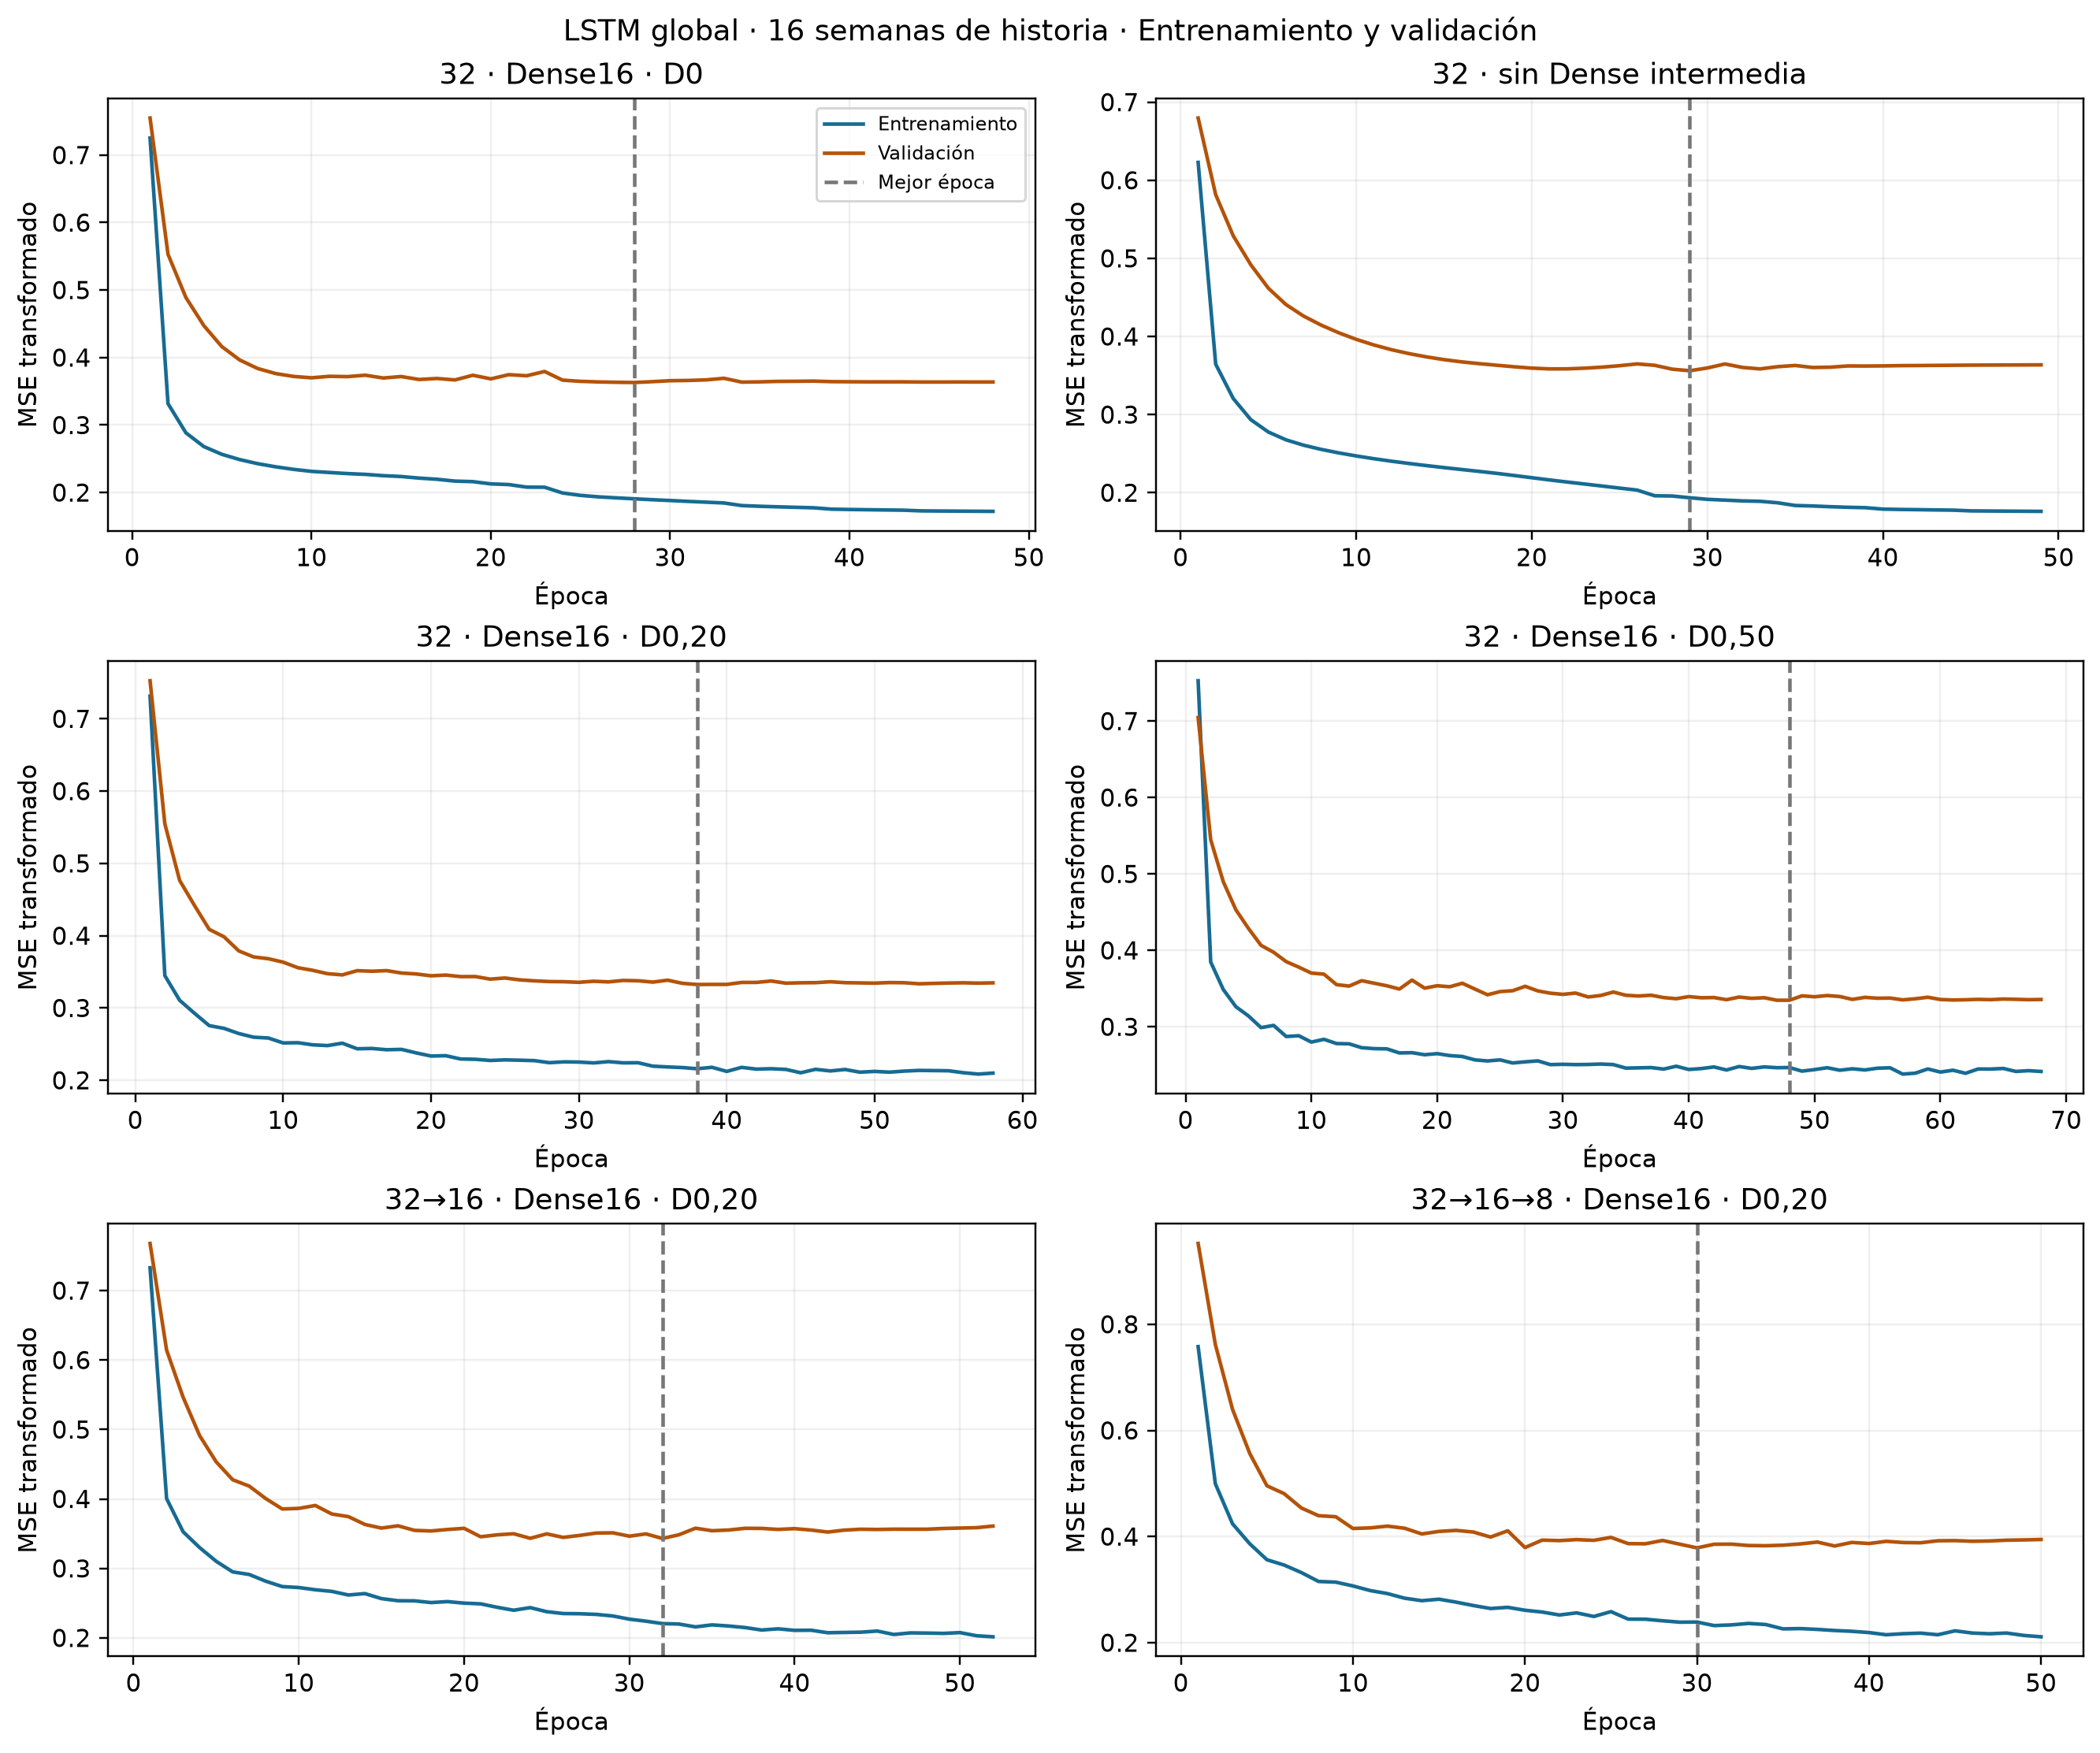

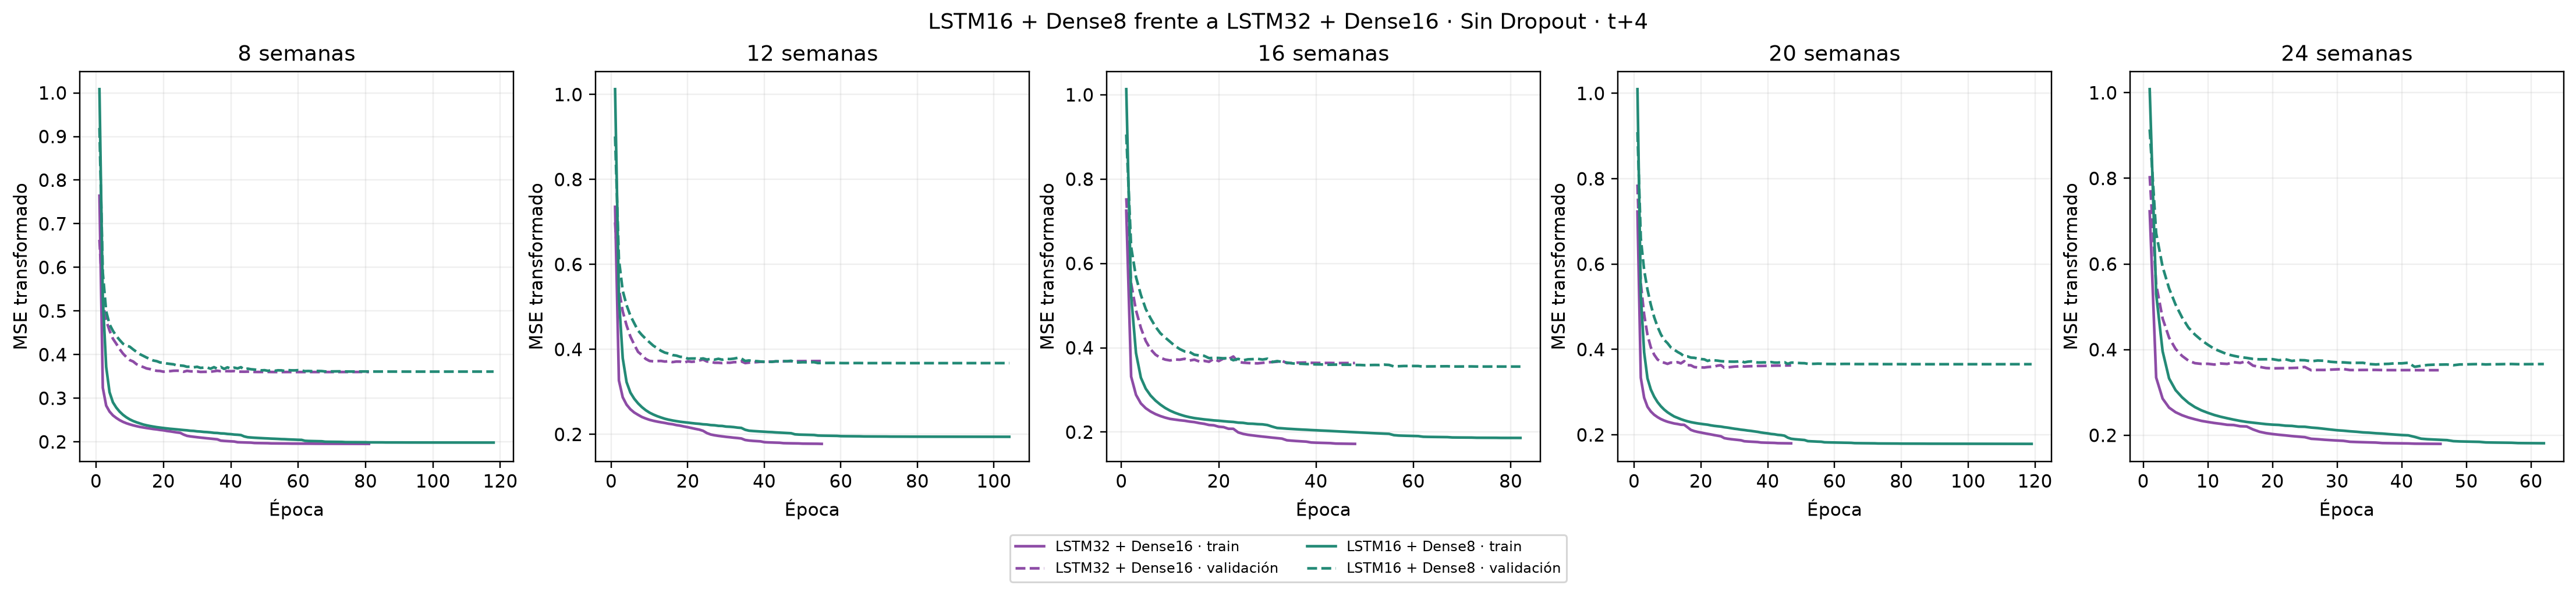

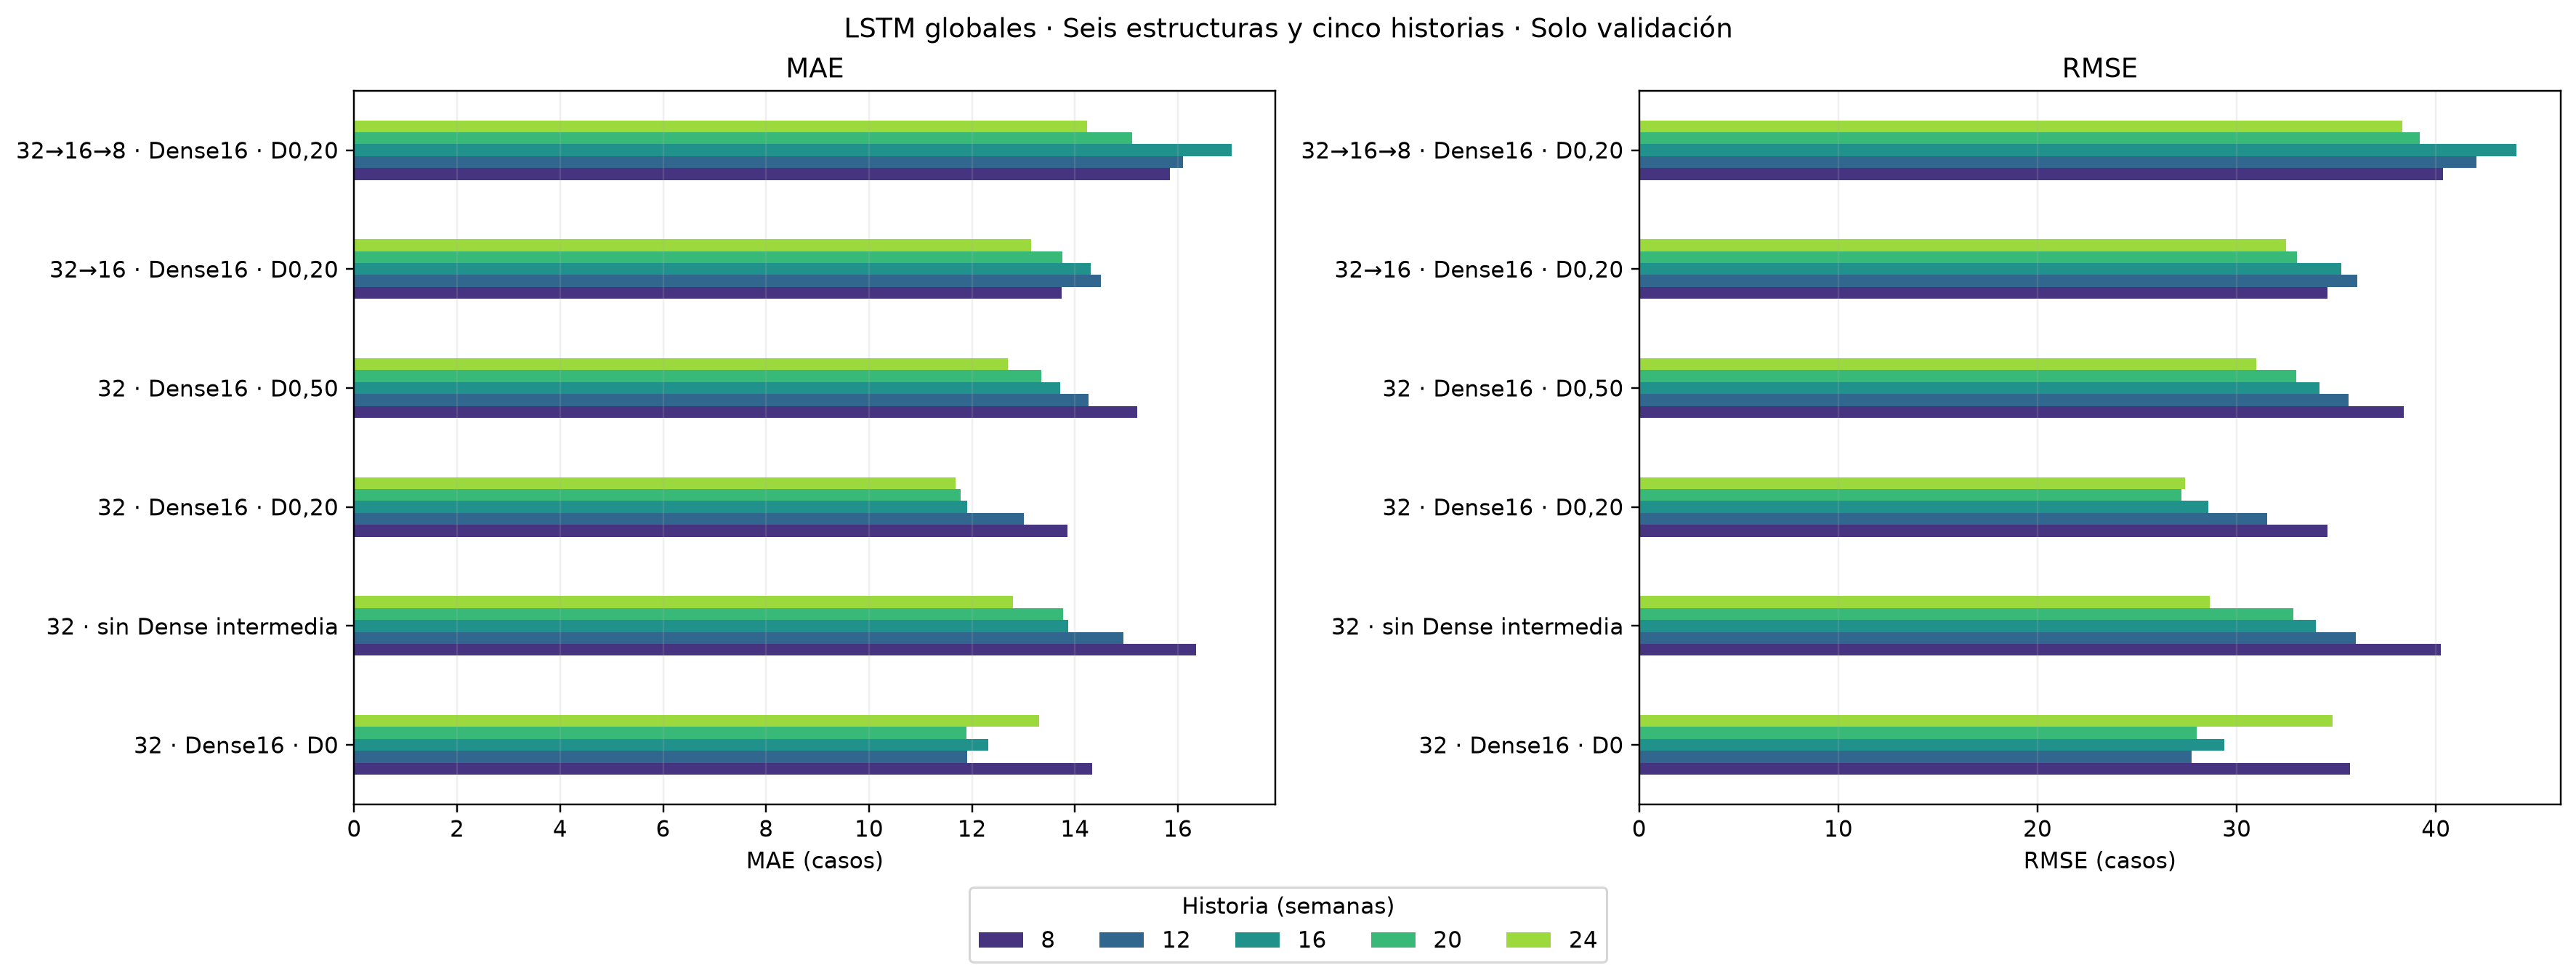

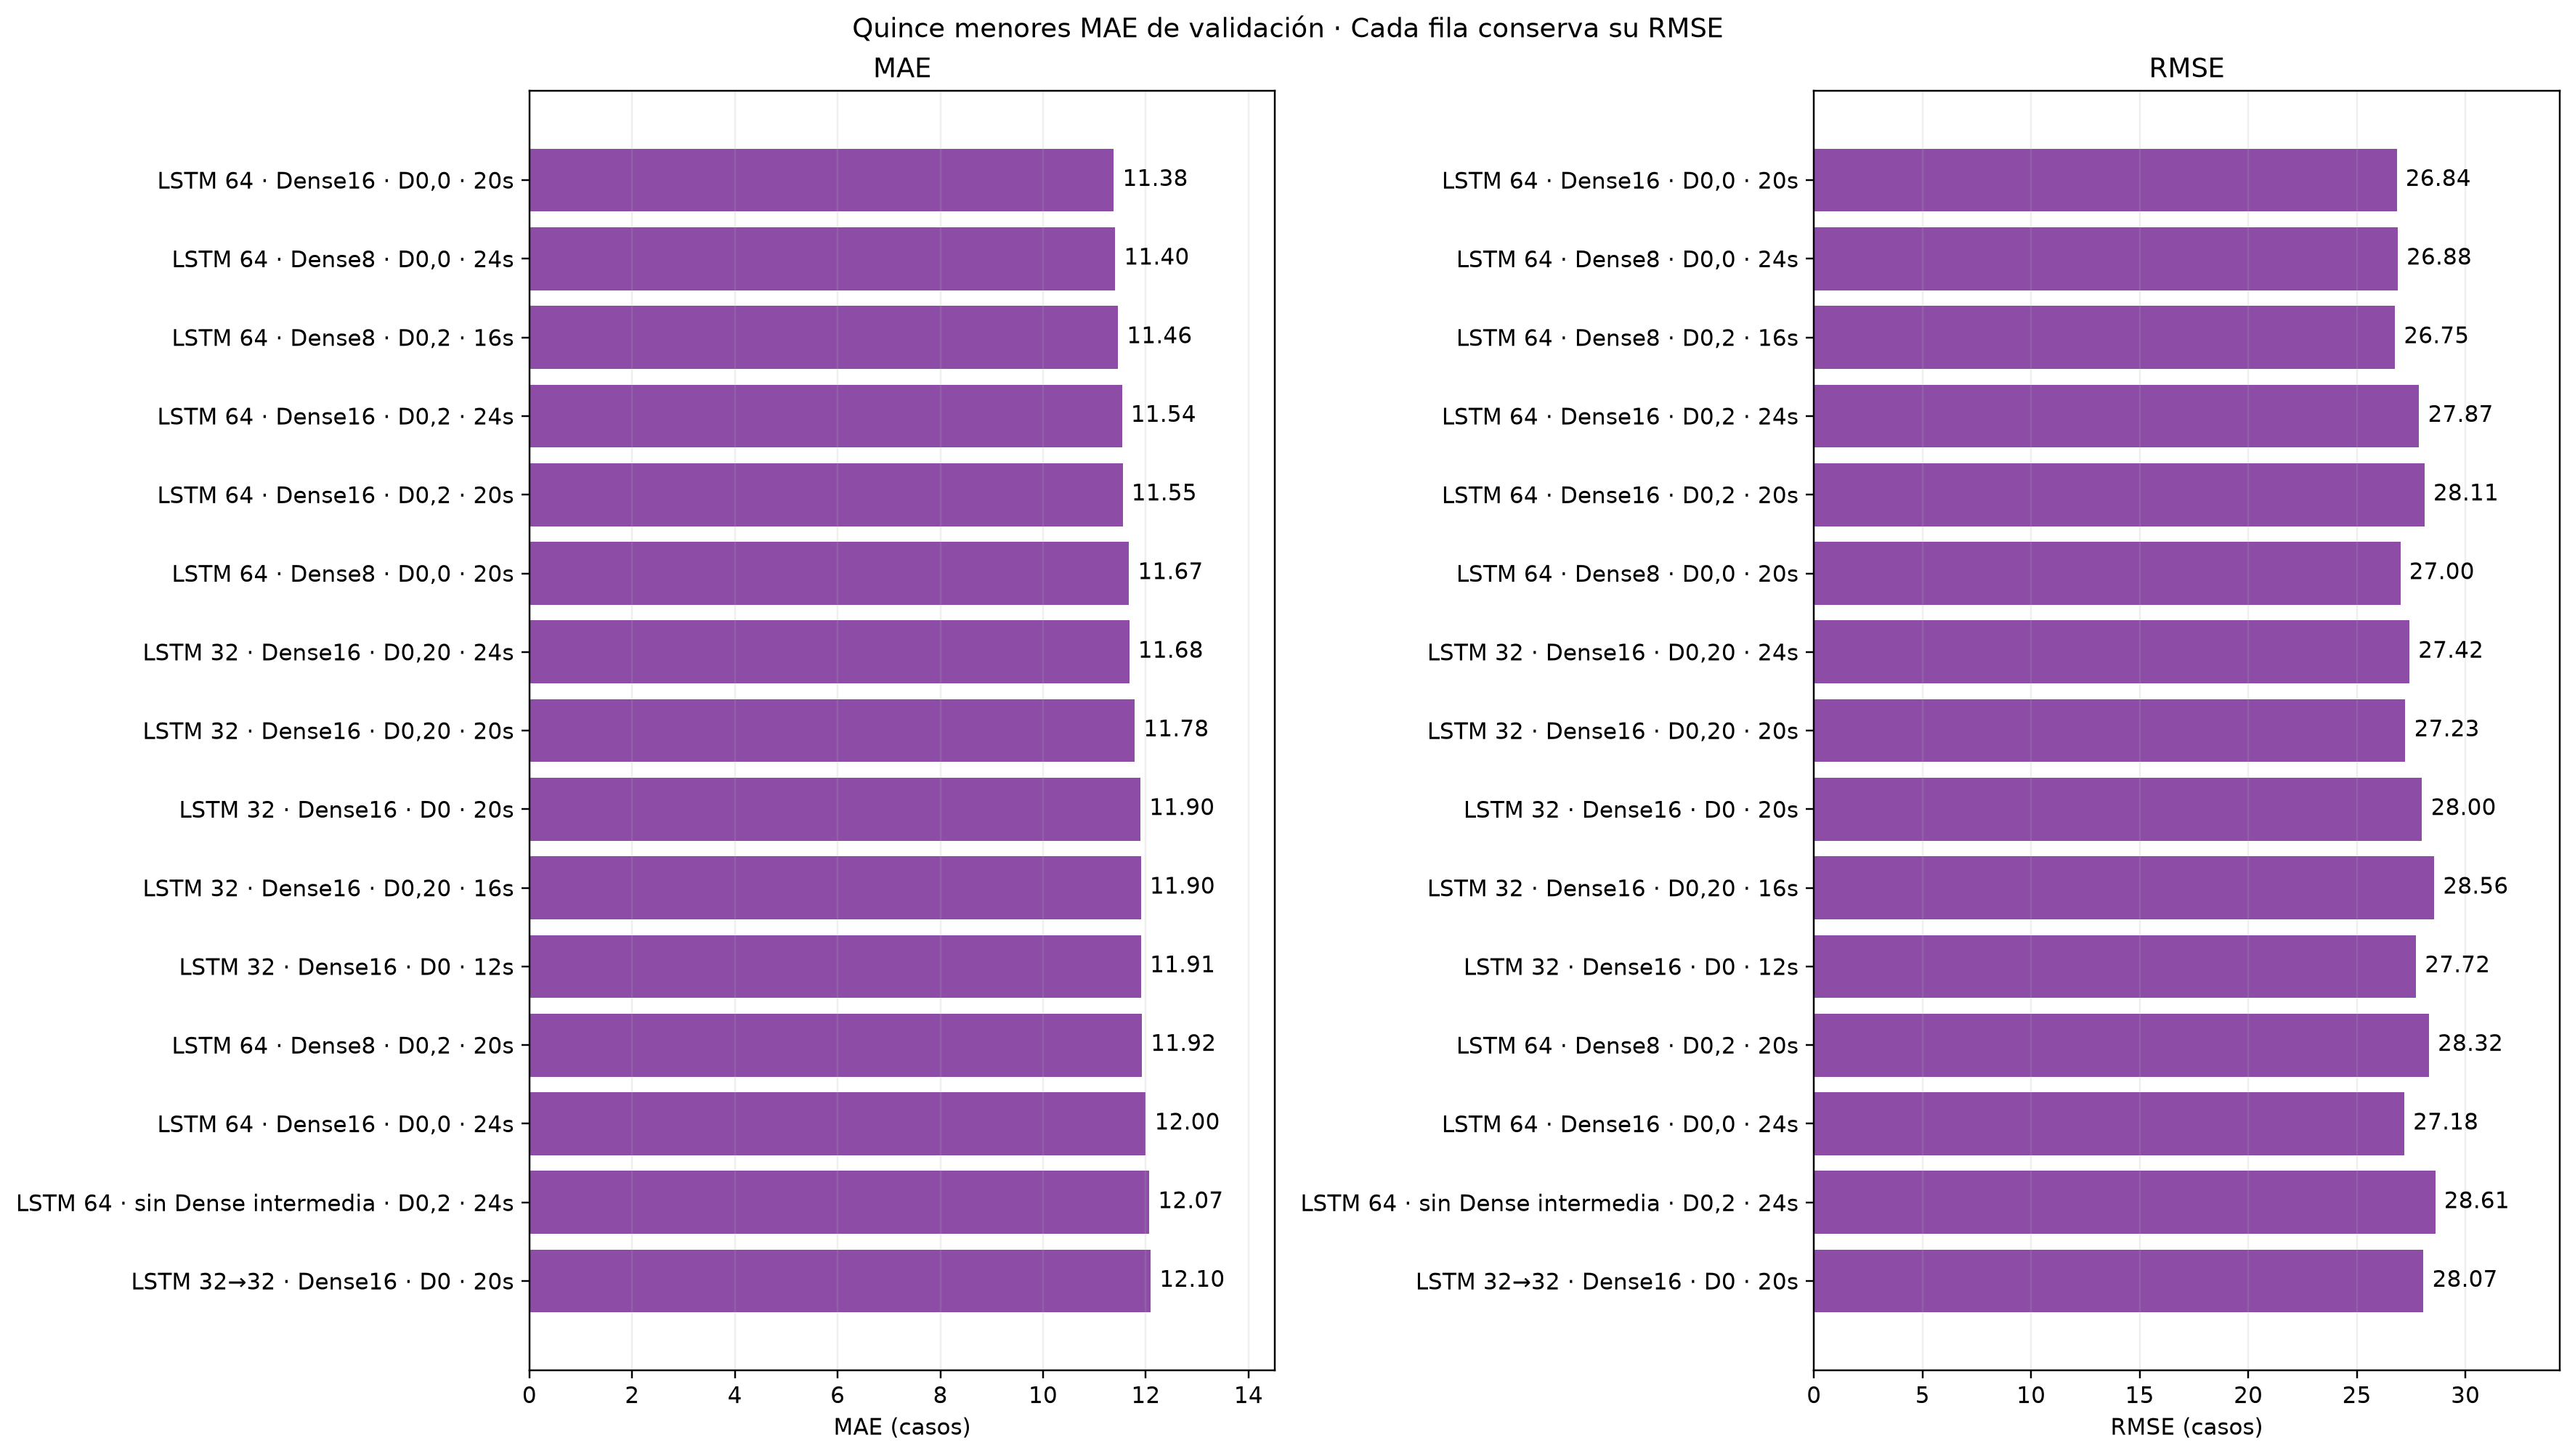

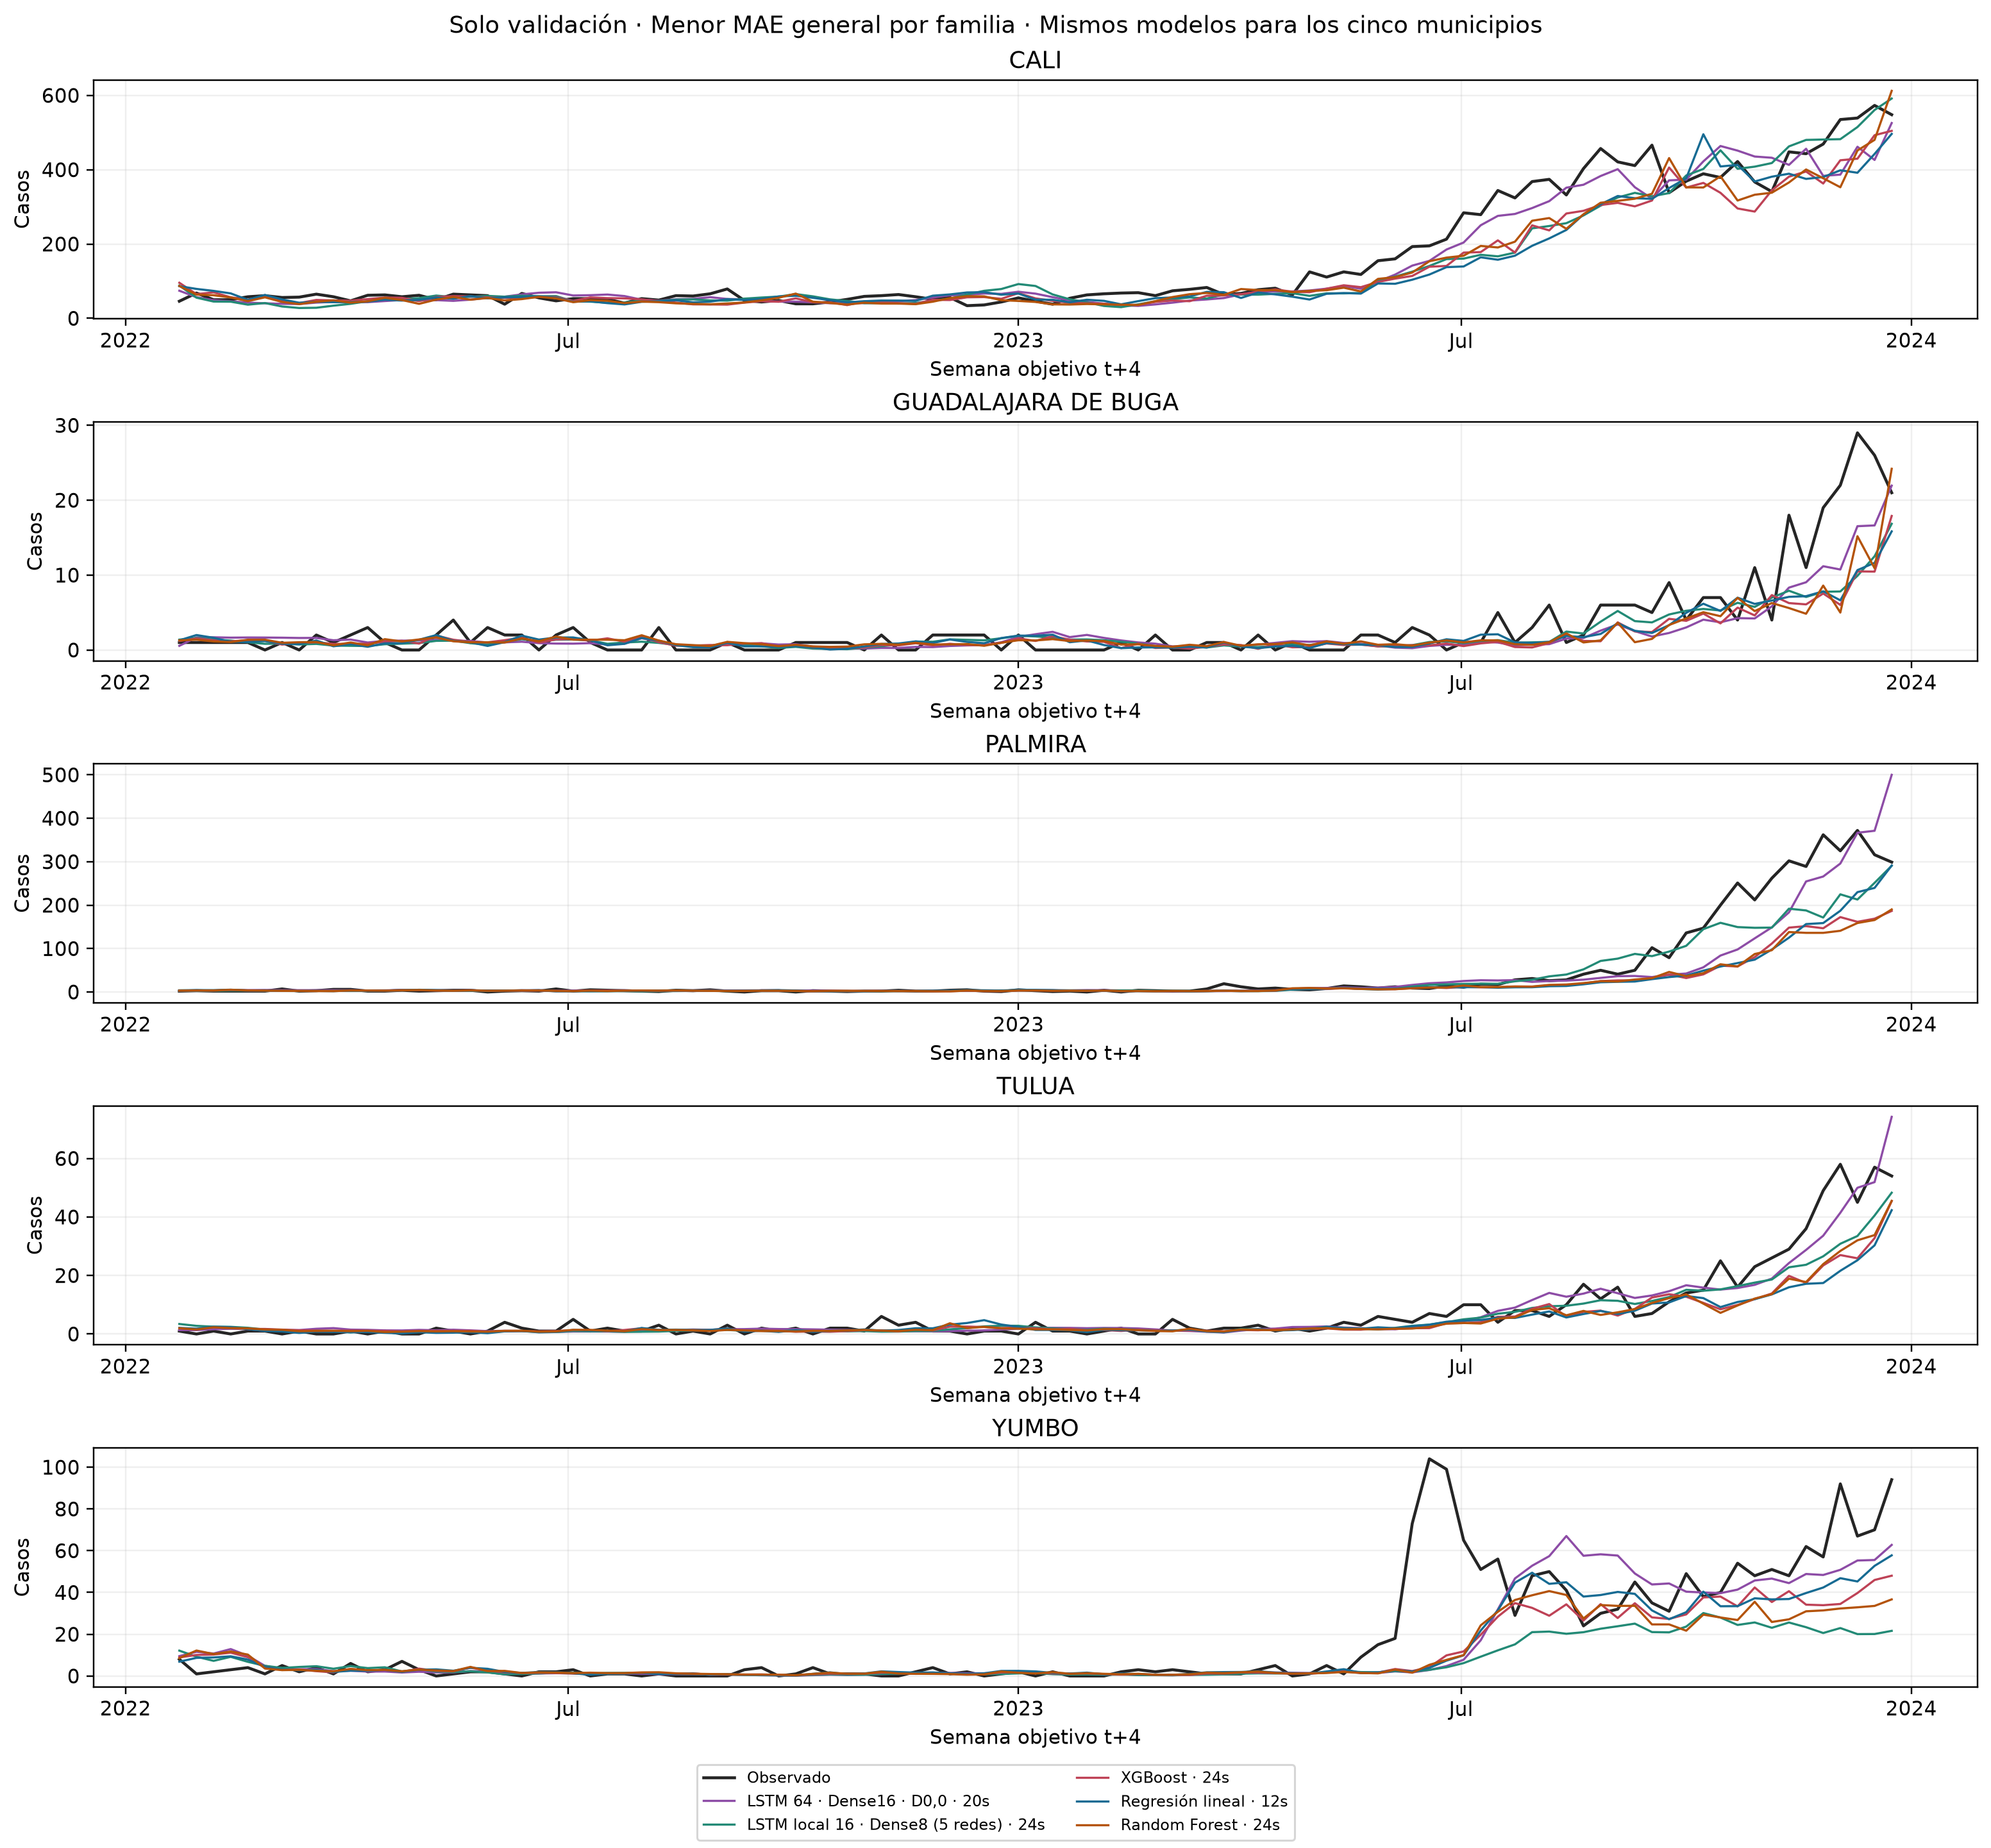

In [63]:
HISTORIA_PARA_CURVAS = 16
assert HISTORIA_PARA_CURVAS in HISTORIAS
display(Image(filename=str(RUTA_EJECUCION/f'figuras/curvas_lstm_{HISTORIA_PARA_CURVAS}.png')))
for nombre in ['11_lstm_16_dense8','07_matriz_arquitecturas_historias','08_ranking_validacion_top15','09_series_solo_validacion']:
    display(Image(filename=str(RUTA_EJECUCION/'figuras'/f'{nombre}.png')))


### 18.2. Revisar el modelo seleccionado

Desde aquí seguimos al enfoque que obtuvo el menor MAE de validación. Lo mantenemos fijo para los cinco municipios y revisamos sus diferencias frente a las referencias, el sesgo, los dos años de validación y las semanas con mayores errores. Los resultados se expresan en casos de la semana t+4.


In [64]:
# La elección se obtiene del ranking; no se fija una arquitectura a mano.
ID_MODELO_ANALISIS = ranking_validacion.iloc[0]['ID']
assert seleccion_validacion['ID_ELEGIDO']==ID_MODELO_ANALISIS
fila_modelo_elegido = ranking_validacion.iloc[0]
especificacion_elegida = next(s for s in catalogo_actual if s['ID']==ID_MODELO_ANALISIS)
assert especificacion_elegida['ENTRENADO_EN_ESTA_EJECUCION']
seleccion_validacion['MODELO_ELEGIDO'] = fila_modelo_elegido.to_dict()
(RUTA_EJECUCION/'seleccion_validacion.json').write_text(json.dumps(seleccion_validacion,ensure_ascii=False,
    indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')

analisis_validacion_18_2 = preparar_analisis_validacion(
    predicciones_desarrollo, metricas_desarrollo, metricas_municipales_desarrollo,
    ranking_validacion, seleccion_validacion)

comparacion_eleccion_validacion = analisis_validacion_18_2['tablas']['eleccion']
comparacion_familias_validacion = analisis_validacion_18_2['tablas']['familias']
detalle_municipal_validacion = analisis_validacion_18_2['tablas']['municipios']
comparacion_baseline_municipal = analisis_validacion_18_2['tablas']['frente_baseline']
resultados_validacion_por_ano = analisis_validacion_18_2['tablas']['por_ano']
ids_resumidos = ranking_validacion.head(6)['ID']
detalle_municipal = analisis_validacion_18_2['tablas']['mejores_configuraciones']
mayores_errores_validacion = analisis_validacion_18_2['tablas']['mayores_errores']

RUTA_ANALISIS_VALIDACION = RUTA_EJECUCION/'analisis_validacion'

def mostrar_tabla_validacion(tabla):
    formatos = {col: '{:.3f}' for col in tabla.select_dtypes(include='number').columns
        if col not in ['N','HISTORIA','ANO_OBJETIVO','CASOS_ORIGINALES']}
    formatos.update({col: '{:%Y-%m-%d}' for col in ['FECHA_EMISION','FECHA_OBJETIVO'] if col in tabla.columns})
    display(tabla.style.format(formatos, na_rep='No aplica').hide(axis='index'))

**Curva del modelo seleccionado.**

La figura muestra el historial del elegido y marca el paso con menor pérdida de validación. La pérdida está en la escala transformada; las métricas de casos se revisan en las tablas siguientes.

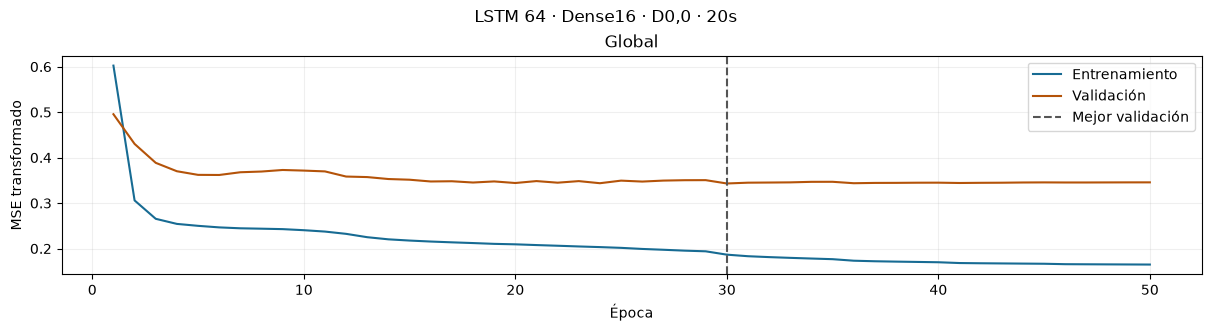

In [65]:
# La regresión lineal y Random Forest no tienen una curva por época.
if especificacion_elegida['TIPO']=='sklearn':
    print('El modelo seleccionado no registra un historial por época; su desempeño se muestra en las tablas de casos.')
else:
    # Mostrar el historial del enfoque seleccionado, sin ajustar ni cargar pesos.
    if especificacion_elegida['TIPO']=='local':
        historiales_elegido = [(codigo,Path(archivo).parent/'historial.csv')
            for codigo,archivo in especificacion_elegida['ARCHIVO'].items()]
    elif especificacion_elegida['TIPO']=='xgboost':
        historiales_elegido = [('Global',Path(especificacion_elegida['ARCHIVO']).parent/'historial.csv')]
    else:
        historiales_elegido = [('Global',Path(especificacion_elegida['HISTORIAL']))]
    figura_curvas_elegido,ejes_curvas_elegido = plt.subplots(len(historiales_elegido),1,
        figsize=(12,3.2*len(historiales_elegido)),constrained_layout=True,squeeze=False)
    for eje,(etiqueta,ruta_historial) in zip(ejes_curvas_elegido.ravel(),historiales_elegido):
        historial = pd.read_csv(ruta_historial,encoding='utf-8-sig')
        if especificacion_elegida['TIPO']=='xgboost':
            pasos = np.arange(1,len(historial)+1)
            perdida_train,perdida_val = historial['RMSE_TRAIN_STD'],historial['RMSE_VAL_STD']
            eje.set(xlabel='Ronda',ylabel='RMSE transformado')
        else:
            pasos = historial['EPOCA'].to_numpy()
            perdida_train,perdida_val = historial['loss'],historial['val_loss']
            eje.set(xlabel='Época',ylabel='MSE transformado')
        eje.plot(pasos,perdida_train,label='Entrenamiento',color='#176B93')
        eje.plot(pasos,perdida_val,label='Validación',color='#B45309')
        eje.axvline(pasos[int(np.argmin(perdida_val))],color='#555555',linestyle='--',label='Mejor validación')
        eje.set_title(etiqueta)
        eje.grid(alpha=.2)
        eje.legend()
    figura_curvas_elegido.suptitle(especificacion_elegida['NOMBRE'])
    RUTA_ANALISIS_VALIDACION.mkdir(parents=True,exist_ok=True)
    for extension in ['png','svg']:
        figura_curvas_elegido.savefig(RUTA_ANALISIS_VALIDACION/f'curva_modelo_elegido.{extension}',dpi=220,bbox_inches='tight')
    plt.show()


#### 18.2.1. Comparar las familias y revisar el candidato

El enfoque seleccionado es **LSTM 64 · Dense16 · D0,0 · 20s**. Obtuvo **MAE de 11.377 y RMSE de 26.837 casos** en los 505 objetivos de validación. Su MAE fue el menor de los 100 enfoques, calculado sin redondear; no se conservó una preferencia previa por arquitectura o Dropout.

El baseline con menor MAE fue **XGBoost · 24s**, con MAE 14.759 y RMSE 36.342. La tabla por familias mantiene una misma configuración para los cinco municipios. El menor RMSE general corresponde a **LSTM 64 · Dense8 · D0,2 · 16s**, con 26.755; lo mostramos como referencia, aunque el criterio de selección sigue siendo MAE.


In [66]:
display(comparacion_eleccion_validacion[['ROL','MODELO','HISTORIA','PARAMETROS_RED','MAE','RMSE']].style.format(
    {'PARAMETROS_RED':'{:.0f}','MAE':'{:.3f}','RMSE':'{:.3f}'},na_rep='No aplica').hide(axis='index'))

ROL,MODELO,HISTORIA,PARAMETROS_RED,MAE,RMSE
Modelo elegido; Menor MAE general,"LSTM 64 · Dense16 · D0,0 · 20s",20,19569,11.377,26.837


**Referencias por familia y modelo elegido.**

In [67]:
mostrar_tabla_validacion(comparacion_familias_validacion[
    ['ROL','FAMILIA','MODELO','HISTORIA','N','MAE_TRAIN','RMSE_TRAIN','MAE_VAL','RMSE_VAL']])

ROL,FAMILIA,MODELO,HISTORIA,N,MAE_TRAIN,RMSE_TRAIN,MAE_VAL,RMSE_VAL
Elegido; menor MAE de su familia,LSTM,"LSTM 64 · Dense16 · D0,0 · 20s",20,505,7.743,21.898,11.377,26.837
Menor MAE de su familia,LSTM local,LSTM local 16 · Dense8 (5 redes) · 24s,24,505,7.273,21.382,12.872,30.108
Menor MAE de su familia,XGBoost,XGBoost · 24s,24,505,7.860,22.953,14.759,36.342
Menor MAE de su familia,Regresión lineal,Regresión lineal · 12s,12,505,10.626,31.421,14.841,36.872
Menor MAE de su familia,Random Forest,Random Forest · 24s,24,505,5.048,14.711,14.857,36.810


#### 18.2.2. Revisar el error y el sesgo por municipio

El MAE del elegido va de **1.748 casos en GUADALAJARA DE BUGA** a **28.669 en CALI**. Cada municipio aporta 101 pronósticos. Son errores en cantidades de casos: una cifra menor no implica por sí sola una mayor precisión proporcional, porque los municipios tienen volúmenes distintos.

El sesgo general es **-5.602 casos**, calculado como pronosticado menos real. El **53.66 %** de los pronósticos quedó por debajo del valor observado por más de 0,001 casos. Se conservaron **0 valores negativos** en las métricas.


In [68]:
mostrar_tabla_validacion(detalle_municipal_validacion[
    ['MUNICIPIO','N','CASOS_MEDIOS','MAE','RMSE','SESGO_MEDIO','SUBESTIMACION_PCT','APORTE_ERROR_PCT']])

MUNICIPIO,N,CASOS_MEDIOS,MAE,RMSE,SESGO_MEDIO,SUBESTIMACION_PCT,APORTE_ERROR_PCT
CALI,101,156.178,28.669,41.275,-15.084,70.297,50.397
GUADALAJARA DE BUGA,101,3.050,1.748,2.881,-0.932,53.465,3.073
PALMIRA,101,42.683,15.482,38.723,-7.839,47.525,27.217
TULUA,101,6.931,2.481,4.129,-0.357,46.535,4.362
YUMBO,101,17.347,8.505,19.307,-3.798,50.495,14.951


**Detalle de las seis configuraciones con menor MAE general.**

Se conserva el detalle municipal de las seis configuraciones con menor MAE general. Estas filas permiten contrastar alternativas; el modelo elegido para el análisis se mantiene fijo.

In [69]:
display(detalle_municipal[['MODELO','MUNICIPIO','N','MAE','RMSE','SESGO_MEDIO']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:.3f}'}).hide(axis='index'))

MODELO,MUNICIPIO,N,MAE,RMSE,SESGO_MEDIO
"LSTM 64 · Dense16 · D0,0 · 20s",CALI,101,28.669,41.275,-15.084
"LSTM 64 · Dense16 · D0,0 · 20s",GUADALAJARA DE BUGA,101,1.748,2.881,-0.932
"LSTM 64 · Dense16 · D0,0 · 20s",PALMIRA,101,15.482,38.723,-7.839
"LSTM 64 · Dense16 · D0,0 · 20s",TULUA,101,2.481,4.129,-0.357
"LSTM 64 · Dense16 · D0,0 · 20s",YUMBO,101,8.505,19.307,-3.798
"LSTM 64 · Dense8 · D0,0 · 24s",CALI,101,28.543,41.049,-13.844
"LSTM 64 · Dense8 · D0,0 · 24s",GUADALAJARA DE BUGA,101,1.519,2.512,-0.714
"LSTM 64 · Dense8 · D0,0 · 24s",PALMIRA,101,15.851,39.278,-7.293
"LSTM 64 · Dense8 · D0,0 · 24s",TULUA,101,2.605,4.493,-0.655
"LSTM 64 · Dense8 · D0,0 · 24s",YUMBO,101,8.501,18.924,-4.955


#### 18.2.3. Comparar con el mismo baseline en las cinco ciudades

Comparamos el elegido con **XGBoost · 24s**, fijado por su menor MAE general entre los baselines. El seleccionado obtuvo menor MAE en **5 de cinco municipios** y menor RMSE en **5 de cinco**.

La diferencia se calcula como baseline menos seleccionado; los valores positivos favorecen al elegido. Usamos los mismos modelos en todas las ciudades para que la comparación no dependa de escoger una referencia distinta en cada municipio.


MUNICIPIO,MAE_CANDIDATO,MAE_BASELINE,DIFERENCIA_MAE,REDUCCION_MAE_PCT,RMSE_CANDIDATO,RMSE_BASELINE,DIFERENCIA_RMSE
CALI,28.669,36.272,7.603,20.962,41.275,54.836,13.561
GUADALAJARA DE BUGA,1.748,1.972,0.224,11.363,2.881,3.751,0.870
PALMIRA,15.482,23.427,7.945,33.913,38.723,56.210,17.487
TULUA,2.481,3.409,0.928,27.228,4.129,6.485,2.357
YUMBO,8.505,8.716,0.211,2.419,19.307,19.524,0.217


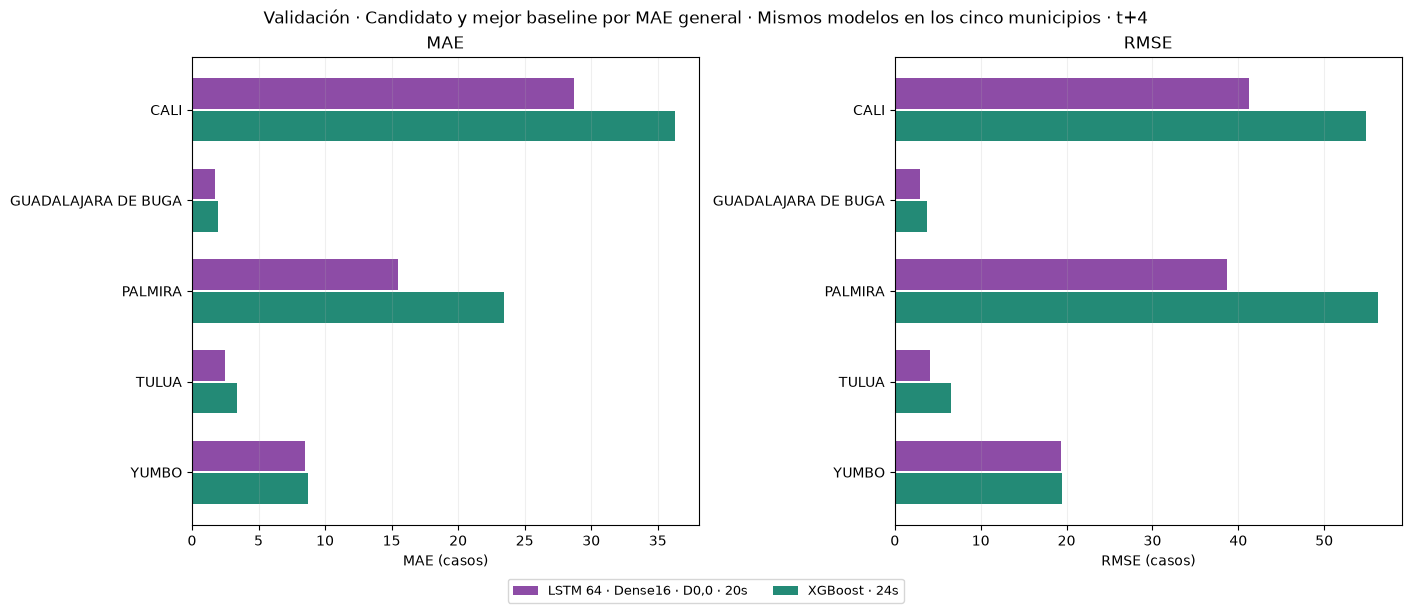

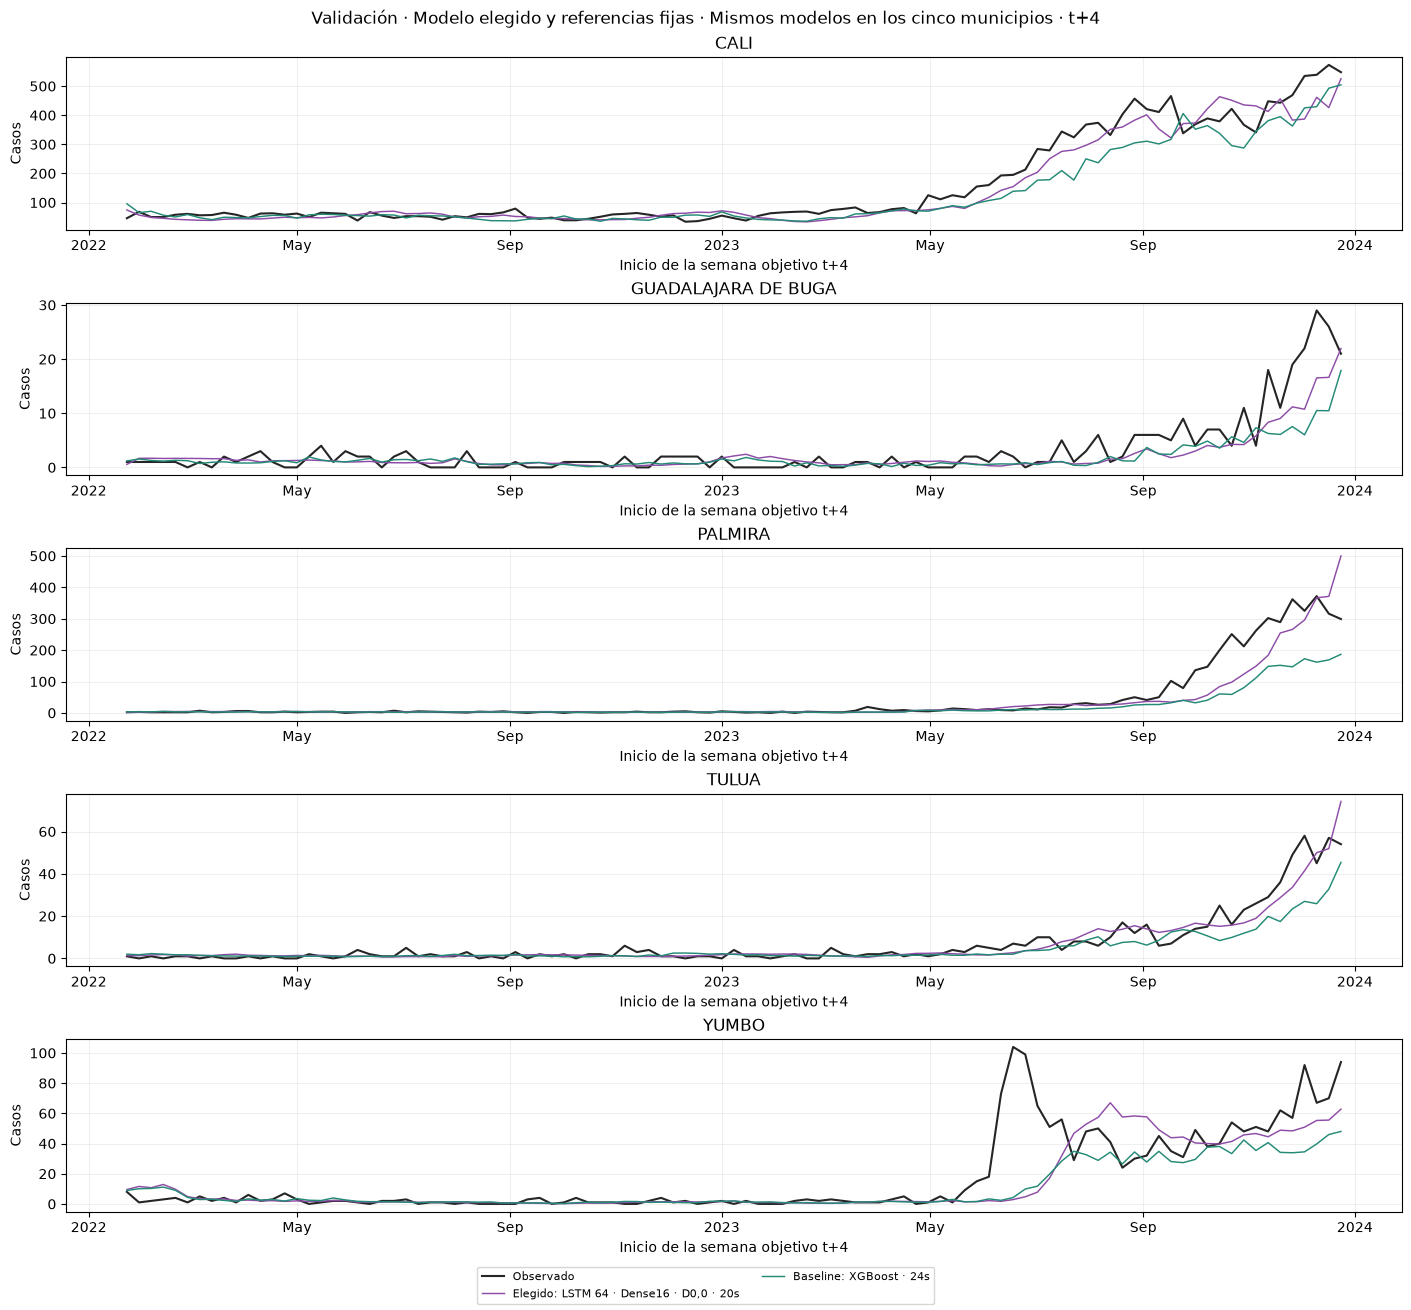

In [70]:
mostrar_tabla_validacion(comparacion_baseline_municipal[
    ['MUNICIPIO','MAE_CANDIDATO','MAE_BASELINE','DIFERENCIA_MAE','REDUCCION_MAE_PCT',
     'RMSE_CANDIDATO','RMSE_BASELINE','DIFERENCIA_RMSE']])
figura_comparacion_municipal = graficar_comparacion_municipal(
    analisis_validacion_18_2, RUTA_ANALISIS_VALIDACION)
plt.show()
figura_series_modelo_elegido = graficar_series_candidato(
    predicciones_desarrollo, analisis_validacion_18_2, ranking_validacion, RUTA_ANALISIS_VALIDACION)
plt.show()

#### 18.2.4. Separar los años de validación

En **2022**, el elegido obtuvo **MAE 3.536 y RMSE 6.871**, con 245 pronósticos y un promedio observado de 12.23 casos por municipio y semana.

En **2023**, el elegido obtuvo **MAE 18.766 y RMSE 36.803**, con 260 pronósticos y un promedio observado de 76.34 casos por municipio y semana.

El desglose ayuda a ver diferencias que se pierden al reunir los dos años. Se conservan los pesos y las ventanas originales; no hay un nuevo ajuste por año.


In [71]:
mostrar_tabla_validacion(resultados_validacion_por_ano[
    ['MODELO','ANO_OBJETIVO','N','CASOS_MEDIOS','MAE','RMSE','SESGO_MEDIO']])

MODELO,ANO_OBJETIVO,N,CASOS_MEDIOS,MAE,RMSE,SESGO_MEDIO
"LSTM 64 · Dense16 · D0,0 · 20s",2022,245,12.233,3.536,6.871,-0.313
"LSTM 64 · Dense16 · D0,0 · 20s",2023,260,76.338,18.766,36.803,-10.586
XGBoost · 24s,2022,245,12.233,3.309,7.029,-0.494
XGBoost · 24s,2023,260,76.338,25.549,50.188,-24.066


#### 18.2.5. Examinar las semanas con mayores errores

Los diez mayores errores absolutos reúnen el **51.68 % de la suma de errores cuadrados** del elegido. En **9 de esos diez pronósticos** se subestimaron los casos. Esto muestra cuánto pesan algunas semanas en RMSE.

Las identificamos después de observar validación. La tabla permite revisar la emisión, la semana objetivo y el error, pero no constituye una regla para anticipar esos episodios.


In [72]:
mostrar_tabla_validacion(mayores_errores_validacion[
    ['MUNICIPIO','FECHA_EMISION','FECHA_OBJETIVO','CASOS_ORIGINALES','CASOS_PREDICHOS','ERROR','ERROR_ABSOLUTO']])
guardar_analisis_validacion(analisis_validacion_18_2, RUTA_ANALISIS_VALIDACION)

MUNICIPIO,FECHA_EMISION,FECHA_OBJETIVO,CASOS_ORIGINALES,CASOS_PREDICHOS,ERROR,ERROR_ABSOLUTO
PALMIRA,2023-12-02,2023-12-24,299,500.030,201.030,201.030
PALMIRA,2023-09-30,2023-10-22,251,97.909,-153.091,153.091
CALI,2023-11-11,2023-12-03,535,386.750,-148.250,148.250
CALI,2023-11-25,2023-12-17,573,426.216,-146.784,146.784
CALI,2023-08-26,2023-09-17,466,321.923,-144.077,144.077
PALMIRA,2023-10-21,2023-11-12,302,183.309,-118.691,118.691
PALMIRA,2023-09-23,2023-10-15,200,83.879,-116.121,116.121
PALMIRA,2023-10-14,2023-11-05,262,148.782,-113.218,113.218
YUMBO,2023-05-27,2023-06-18,104,2.876,-101.124,101.124
PALMIRA,2023-11-04,2023-11-26,362,265.904,-96.096,96.096


#### 18.2.6. Alcance de esta lectura

La comparación utiliza una semilla y el bloque 2022–2023. Las ventanas se solapan y probar muchas configuraciones sobre el mismo bloque puede favorecer un mínimo optimista. Estos resultados permiten elegir una referencia de trabajo, pero no demuestran superioridad estadística ni estabilidad en otros periodos. El test se revisa después de fijar la selección.


### 18.3. Comparar el tamaño de las LSTM locales

Comparamos tres estructuras con cinco historias: son 15 enfoques, cada uno formado por cinco redes municipales. La tabla muestra los parámetros por red y las métricas en casos. La mejora porcentual usa como referencia LSTM32 + Dense16 de la misma historia; un valor positivo indica menor MAE.

Identificamos el mejor local general con validación y mantenemos su estructura e historia para las cinco ciudades. La selección definitiva sigue considerando también los globales y los baselines.


In [73]:
# Cada fila reúne las cinco redes municipales de una estructura e historia.
comparacion_locales_validacion = ranking_validacion.loc[
    ranking_validacion['FAMILIA'].eq('LSTM local')].copy()
comparacion_locales_validacion['ESTRUCTURA'] = comparacion_locales_validacion['RECETA'].map(
    {'referencia local':'LSTM32 + Dense16','compacta16_8':'LSTM16 + Dense8','compacta8_4':'LSTM8 + Dense4'})
comparacion_locales_validacion['PARAMETROS_POR_RED'] = (
    comparacion_locales_validacion['PARAMETROS_RED']/len(orden_municipios_lstm)).astype(int)
metricas_train_locales = metricas_desarrollo.loc[
    metricas_desarrollo['FAMILIA'].eq('LSTM local') & metricas_desarrollo['CONJUNTO'].eq('training'),
    ['ID','MAE','RMSE']].rename(columns={'MAE':'MAE_TRAIN','RMSE':'RMSE_TRAIN'})
comparacion_locales_validacion = comparacion_locales_validacion.merge(metricas_train_locales,on='ID',validate='one_to_one')
mae_referencia_local = comparacion_locales_validacion.loc[
    comparacion_locales_validacion['RECETA'].eq('referencia local')].set_index('HISTORIA')['MAE']
comparacion_locales_validacion['MAE_REFERENCIA_MISMA_HISTORIA'] = comparacion_locales_validacion['HISTORIA'].map(mae_referencia_local)
comparacion_locales_validacion['MEJORA_MAE_PCT'] = 100*(1-comparacion_locales_validacion['MAE']/
    comparacion_locales_validacion['MAE_REFERENCIA_MISMA_HISTORIA'])
comparacion_locales_validacion = comparacion_locales_validacion.sort_values(['HISTORIA','PARAMETROS_POR_RED'],ascending=[True,False])
display(comparacion_locales_validacion[['ESTRUCTURA','HISTORIA','PARAMETROS_POR_RED','MAE_TRAIN','RMSE_TRAIN',
    'MAE','RMSE','MEJORA_MAE_PCT']].style.format({'MAE_TRAIN':'{:.3f}','RMSE_TRAIN':'{:.3f}',
        'MAE':'{:.3f}','RMSE':'{:.3f}','MEJORA_MAE_PCT':'{:+.2f}'}).hide(axis='index'))
mejores_locales_por_estructura = comparacion_locales_validacion.sort_values(
    ['MAE','RMSE','ID']).groupby('ESTRUCTURA',sort=False).head(1)
ID_MEJOR_LOCAL_VALIDACION = comparacion_locales_validacion.sort_values(['MAE','RMSE','ID']).iloc[0]['ID']
RUTA_ANALISIS_LOCALES = RUTA_EJECUCION/'analisis_locales'
RUTA_ANALISIS_LOCALES.mkdir(parents=True,exist_ok=True)
comparacion_locales_validacion.to_csv(RUTA_ANALISIS_LOCALES/'comparacion_locales_validacion.csv',index=False,encoding='utf-8-sig')
mejores_locales_por_estructura.to_csv(RUTA_ANALISIS_LOCALES/'mejores_por_estructura_validacion.csv',index=False,encoding='utf-8-sig')
(RUTA_ANALISIS_LOCALES/'seleccion_local_por_validacion.json').write_text(json.dumps({
    'ID':ID_MEJOR_LOCAL_VALIDACION,'criterio':'Menor MAE de validación; RMSE e ID para desempates',
    'seleccion_global_conservada':seleccion_validacion['ID_ELEGIDO'],
    'exploracion_planteada_despues_de_observar_test':True},ensure_ascii=False,indent=2),encoding='utf-8')


ESTRUCTURA,HISTORIA,PARAMETROS_POR_RED,MAE_TRAIN,RMSE_TRAIN,MAE,RMSE,MEJORA_MAE_PCT
LSTM32 + Dense16,8,5665,11.247,34.346,19.735,50.970,+0.00
LSTM16 + Dense8,8,1681,10.913,32.394,18.621,46.219,+5.65
LSTM8 + Dense4,8,553,10.174,30.632,16.133,40.939,+18.25
LSTM32 + Dense16,12,5665,10.268,30.996,18.647,46.710,+0.00
LSTM16 + Dense8,12,1681,11.199,33.396,19.051,47.322,-2.17
LSTM8 + Dense4,12,553,10.429,31.033,17.394,43.321,+6.72
LSTM32 + Dense16,16,5665,7.239,21.147,14.936,35.790,+0.00
LSTM16 + Dense8,16,1681,10.874,32.529,18.637,46.315,-24.78
LSTM8 + Dense4,16,553,10.121,29.933,18.414,45.538,-23.29
LSTM32 + Dense16,20,5665,7.229,20.387,15.025,36.762,+0.00


221

#### 18.3.1. Revisar los errores y las curvas de aprendizaje

Las barras comparan MAE y RMSE de validación en casos. Las curvas muestran la pérdida de entrenamiento y validación en la escala transformada, para cada municipio e historia. Usamos el mismo eje vertical dentro de cada fila de municipios.

Una separación persistente entre entrenamiento y validación puede señalar dificultades para trasladar el ajuste a fechas nuevas. Debemos considerar también que son periodos distintos y que las ventanas se solapan. La pérdida transformada guía la parada anticipada; las métricas en casos se calculan con los pesos de la mejor época, no necesariamente con los de la última época dibujada.

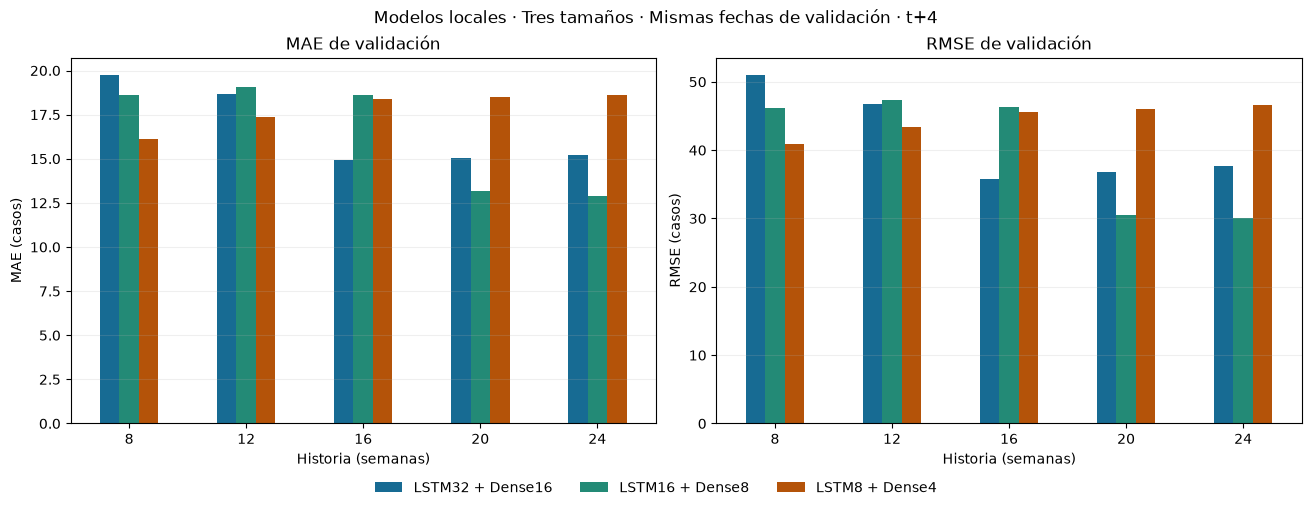

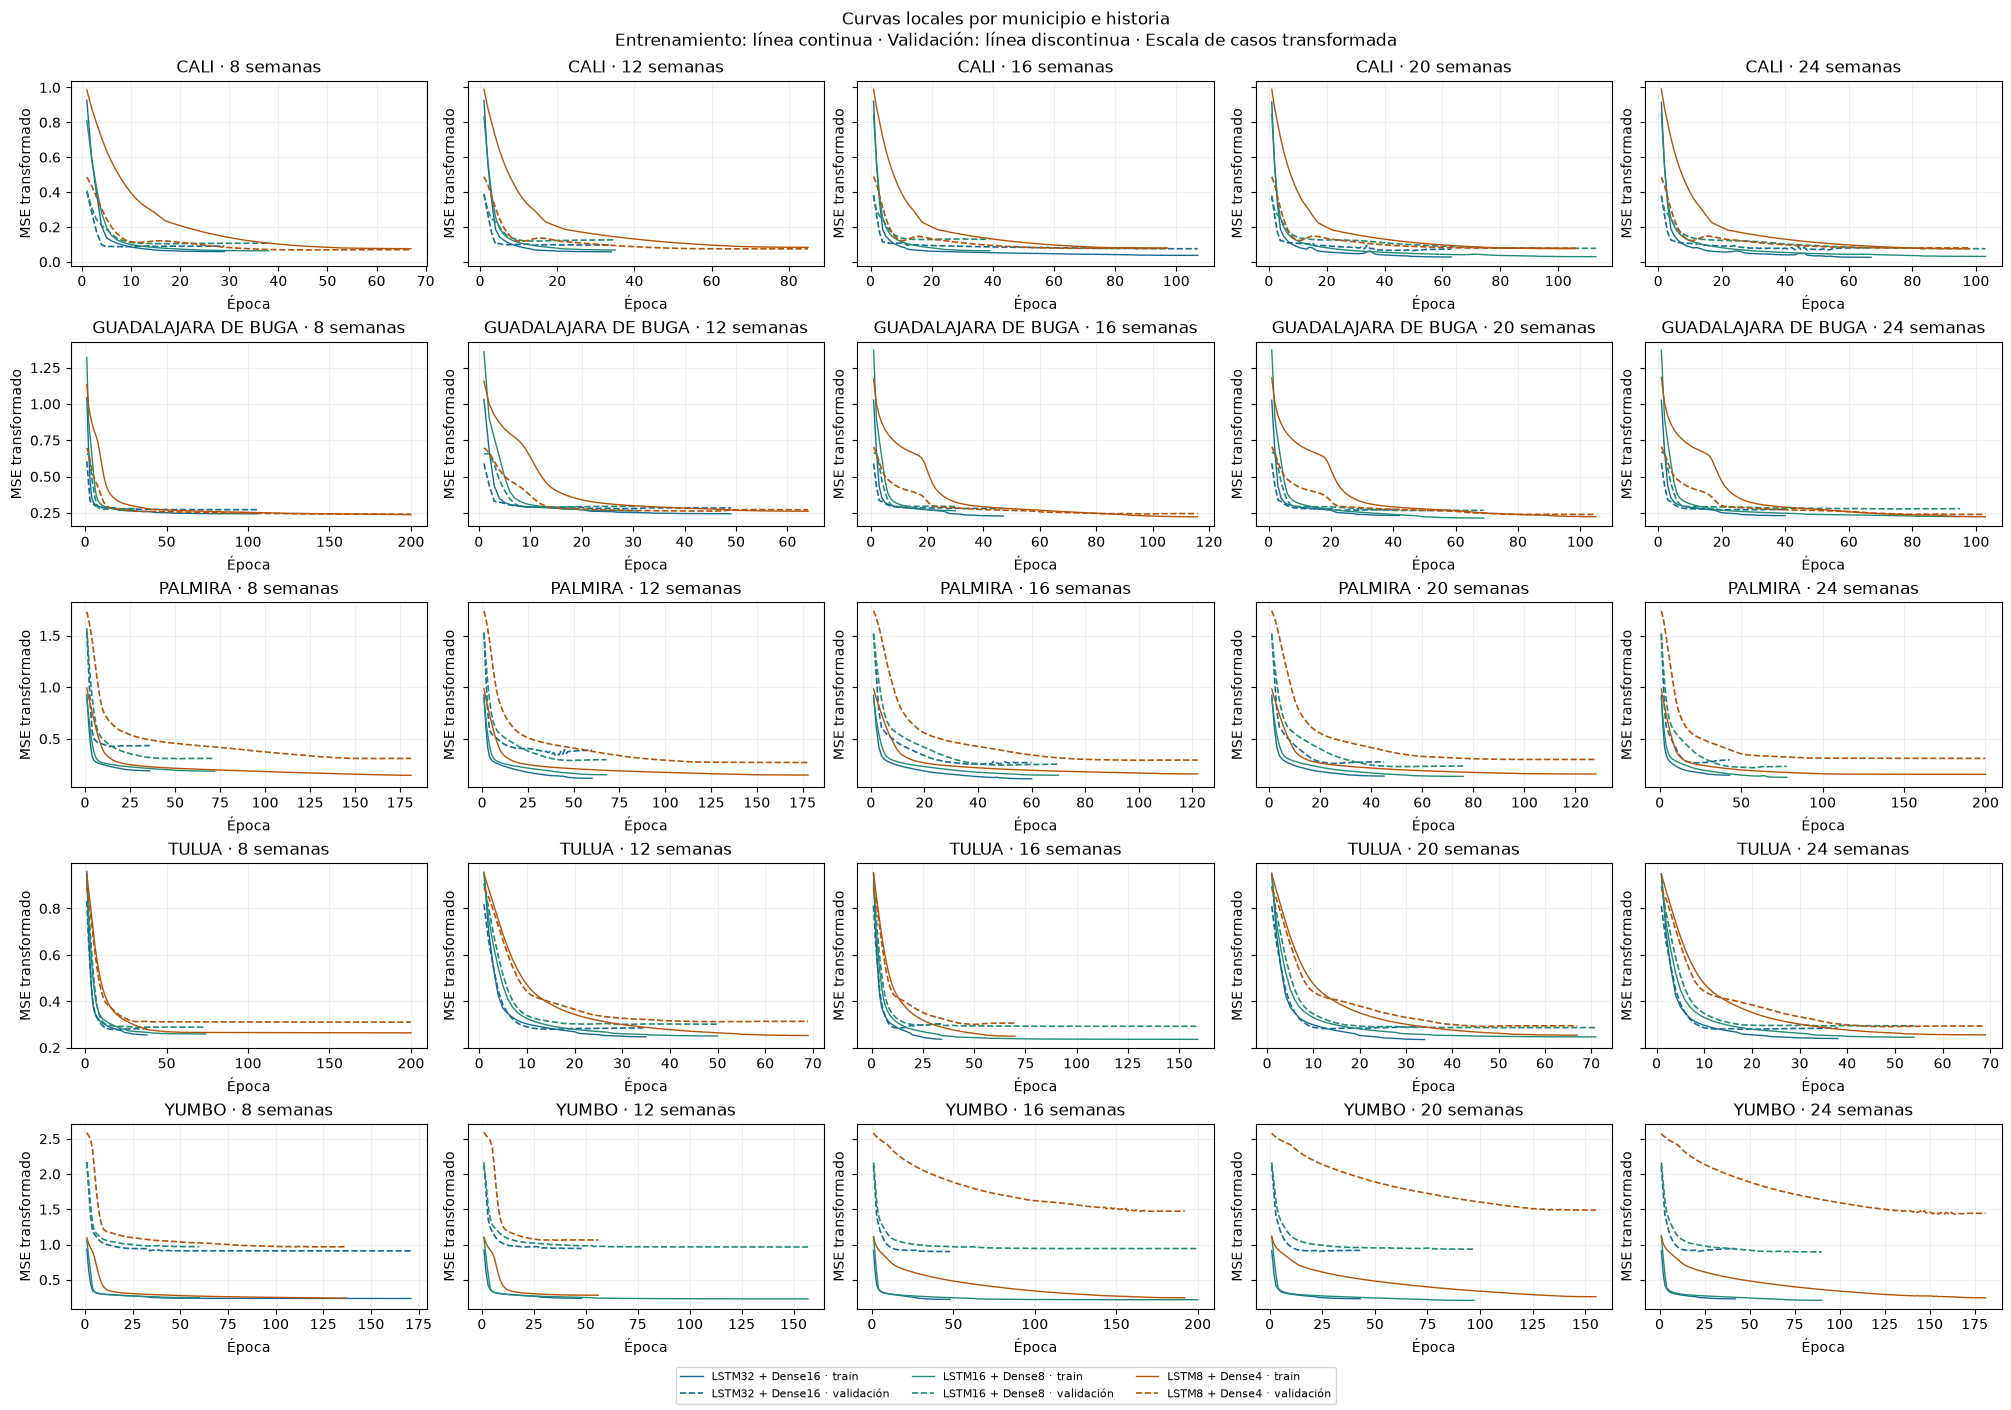

In [74]:
colores_locales = {'LSTM32 + Dense16':'#176B93','LSTM16 + Dense8':'#238A76','LSTM8 + Dense4':'#B45309'}
figura_comparacion_locales,ejes_comparacion_locales = plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for eje,metrica in zip(ejes_comparacion_locales,['MAE','RMSE']):
    tabla = comparacion_locales_validacion.pivot(index='HISTORIA',columns='ESTRUCTURA',values=metrica)
    tabla = tabla.reindex(columns=list(colores_locales))
    tabla.plot.bar(ax=eje,color=list(colores_locales.values()),rot=0)
    eje.set(xlabel='Historia (semanas)',ylabel=f'{metrica} (casos)',title=f'{metrica} de validación')
    eje.grid(axis='y',alpha=.2)
    eje.get_legend().remove()
handles_locales,labels_locales = ejes_comparacion_locales[0].get_legend_handles_labels()
figura_comparacion_locales.legend(handles_locales,labels_locales,loc='outside lower center',ncol=3,frameon=False)
figura_comparacion_locales.suptitle('Modelos locales · Tres tamaños · Mismas fechas de validación · t+4')
for extension in ['png','svg']:
    figura_comparacion_locales.savefig(RUTA_ANALISIS_LOCALES/f'comparacion_estructuras.{extension}',dpi=220,bbox_inches='tight')
plt.show()

figura_curvas_locales,ejes_curvas_locales = plt.subplots(len(orden_municipios_lstm),len(HISTORIAS),
    figsize=(max(14,4*len(HISTORIAS)),14),sharey='row',constrained_layout=True,squeeze=False)
for fila,codigo in enumerate(orden_municipios_lstm):
    municipio = metricas_municipales_desarrollo.loc[metricas_municipales_desarrollo['COD_DANE'].eq(codigo),'MUNICIPIO'].iloc[0]
    for columna,historia in enumerate(HISTORIAS):
        eje = ejes_curvas_locales[fila,columna]
        for prefijo,etiqueta in [('local','LSTM32 + Dense16'),('local_compacta16_8','LSTM16 + Dense8'),
                                ('local_compacta8_4','LSTM8 + Dense4')]:
            spec = next(s for s in catalogo_actual if s['ID']==f'{prefijo}_v{historia}')
            ruta_historial = Path(spec['ARCHIVO'][codigo]).parent/'historial.csv'
            historial = pd.read_csv(ruta_historial,encoding='utf-8-sig')
            eje.plot(historial['EPOCA'],historial['loss'],color=colores_locales[etiqueta],linewidth=1,
                label=f'{etiqueta} · train')
            eje.plot(historial['EPOCA'],historial['val_loss'],color=colores_locales[etiqueta],linestyle='--',linewidth=1.2,
                label=f'{etiqueta} · validación')
        eje.set(title=f'{municipio} · {historia} semanas',xlabel='Época',ylabel='MSE transformado')
        eje.grid(alpha=.2)
handles_curvas_locales,labels_curvas_locales = ejes_curvas_locales[0,0].get_legend_handles_labels()
figura_curvas_locales.legend(handles_curvas_locales,labels_curvas_locales,loc='outside lower center',ncol=3,fontsize=8)
figura_curvas_locales.suptitle('Curvas locales por municipio e historia\nEntrenamiento: línea continua · Validación: línea discontinua · Escala de casos transformada')
for extension in ['png','svg']:
    figura_curvas_locales.savefig(RUTA_ANALISIS_LOCALES/f'curvas_locales.{extension}',dpi=200,bbox_inches='tight')
plt.show()


#### 18.3.2. Revisar las diferencias entre municipios

La tabla identifica el local con menor MAE de validación en cada municipio y lo compara con el enfoque seleccionado en el ranking general. Esa selección local puede variar entre ciudades y es un diagnóstico; no constituye un nuevo modelo combinado ya elegido.

Las series mantienen una historia por estructura, escogida por MAE general de validación. Así podemos ver los cambios al reducir la red, usando las mismas configuraciones para todos los municipios.


MUNICIPIO,ESTRUCTURA,HISTORIA,PARAMETROS_POR_RED,MAE,RMSE,MAE_SELECCIONADO,RMSE_SELECCIONADO
CALI,LSTM16 + Dense8,24,1681,34.298,51.192,28.669,41.275
GUADALAJARA DE BUGA,LSTM8 + Dense4,24,553,1.476,2.332,1.748,2.881
PALMIRA,LSTM16 + Dense8,24,1681,14.100,36.320,15.482,38.723
TULUA,LSTM16 + Dense8,20,1681,2.562,4.897,2.481,4.129
YUMBO,LSTM32 + Dense16,16,5665,10.899,22.783,8.505,19.307


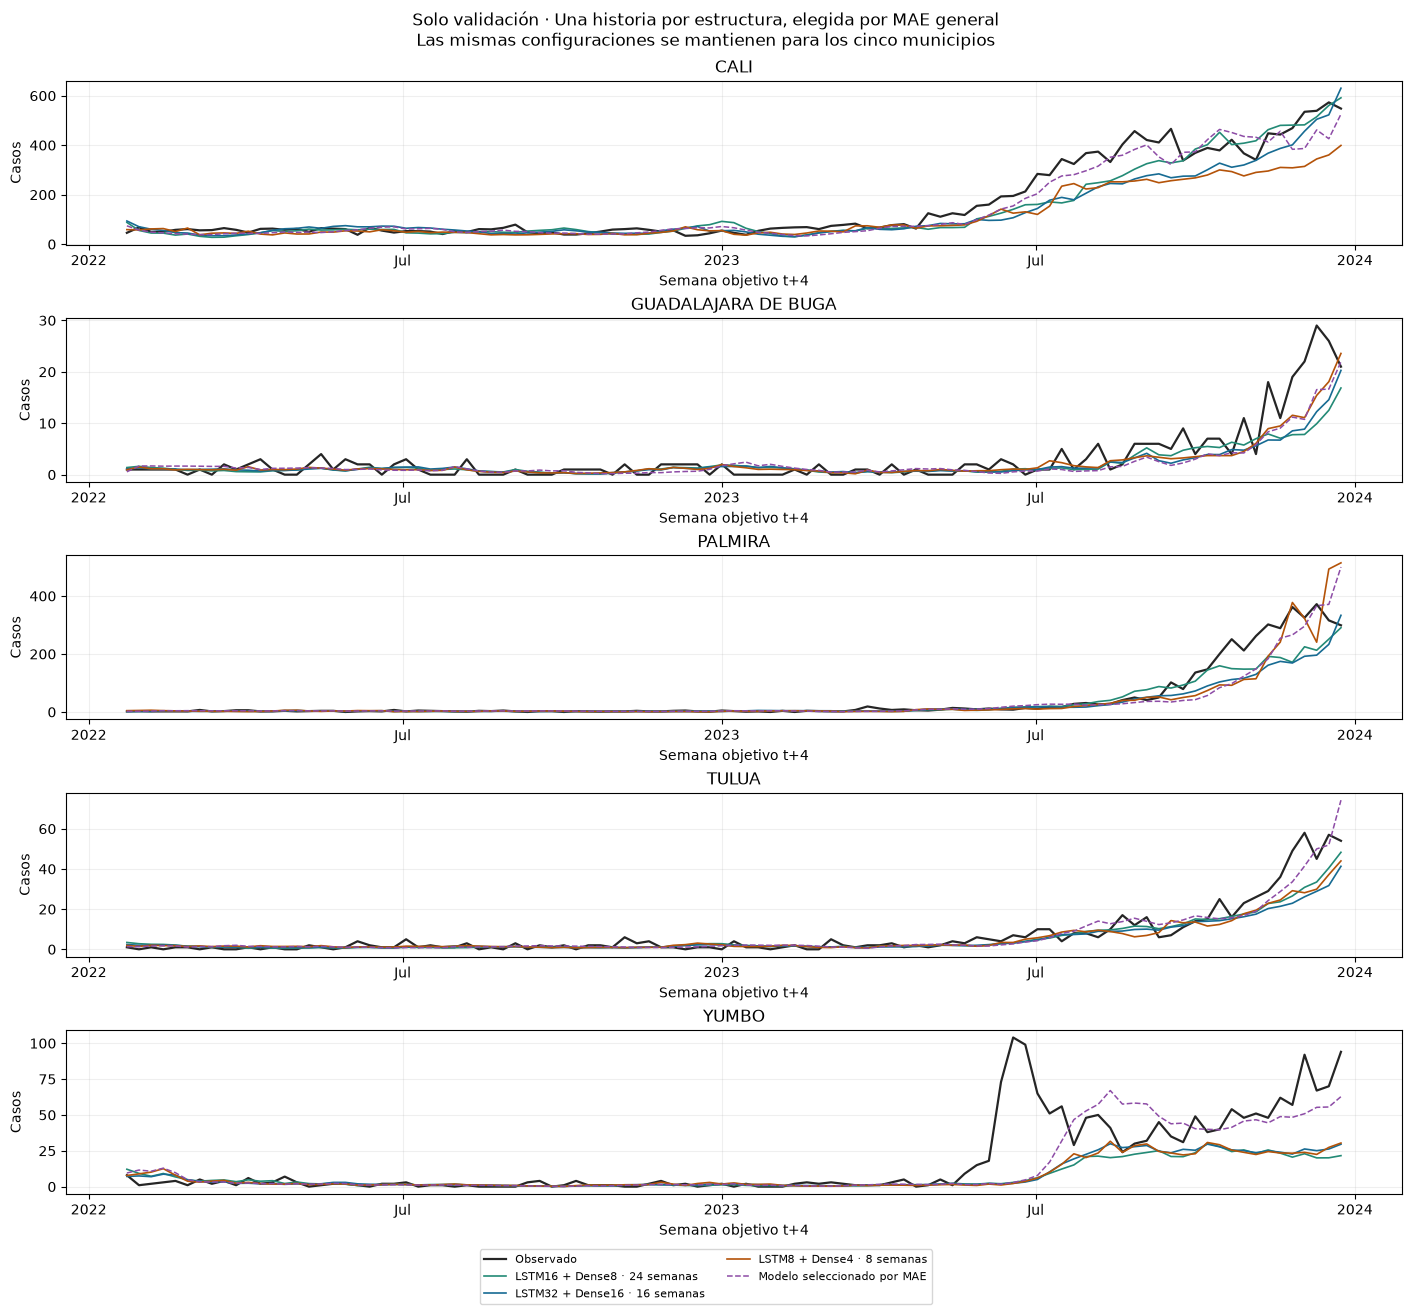

In [75]:
detalle_locales_validacion = metricas_municipales_desarrollo.loc[
    metricas_municipales_desarrollo['FAMILIA'].eq('LSTM local')
    & metricas_municipales_desarrollo['CONJUNTO'].eq('validation')].copy()
detalle_locales_validacion = detalle_locales_validacion.merge(
    comparacion_locales_validacion[['ID','ESTRUCTURA','PARAMETROS_POR_RED']],on='ID',validate='many_to_one')
mejor_local_por_municipio_validacion = detalle_locales_validacion.sort_values(
    ['MAE','RMSE','ID']).groupby('COD_DANE',sort=False,observed=True).head(1)
referencia_global_municipal = metricas_municipales_desarrollo.loc[
    metricas_municipales_desarrollo['ID'].eq(seleccion_validacion['ID_ELEGIDO'])
    & metricas_municipales_desarrollo['CONJUNTO'].eq('validation'),
    ['COD_DANE','MAE','RMSE']].rename(columns={'MAE':'MAE_SELECCIONADO','RMSE':'RMSE_SELECCIONADO'})
comparacion_local_global_municipal = mejor_local_por_municipio_validacion.merge(
    referencia_global_municipal,on='COD_DANE',validate='one_to_one').sort_values('COD_DANE')
display(comparacion_local_global_municipal[['MUNICIPIO','ESTRUCTURA','HISTORIA','PARAMETROS_POR_RED',
    'MAE','RMSE','MAE_SELECCIONADO','RMSE_SELECCIONADO']].style.format(
        {col:'{:.3f}' for col in ['MAE','RMSE','MAE_SELECCIONADO','RMSE_SELECCIONADO']}).hide(axis='index'))
detalle_locales_validacion.to_csv(RUTA_ANALISIS_LOCALES/'detalle_municipal_validacion.csv',index=False,encoding='utf-8-sig')
comparacion_local_global_municipal.to_csv(RUTA_ANALISIS_LOCALES/'mejor_local_por_municipio.csv',index=False,encoding='utf-8-sig')

figura_series_locales,ejes_series_locales = plt.subplots(len(orden_municipios_lstm),1,
    figsize=(14,13),constrained_layout=True,squeeze=False)
val_locales = predicciones_desarrollo.loc[predicciones_desarrollo['CONJUNTO'].eq('validation')].copy()
for eje,codigo in zip(ejes_series_locales.ravel(),orden_municipios_lstm):
    datos = val_locales.loc[val_locales['COD_DANE'].eq(codigo)]
    reales = datos.loc[datos['ID'].eq(seleccion_validacion['ID_ELEGIDO'])].sort_values('FECHA_OBJETIVO')
    eje.plot(reales['FECHA_OBJETIVO'],reales['CASOS_ORIGINALES'],color='#252525',linewidth=1.6,label='Observado')
    for spec in mejores_locales_por_estructura.itertuples():
        p = datos.loc[datos['ID'].eq(spec.ID)].sort_values('FECHA_OBJETIVO')
        eje.plot(p['FECHA_OBJETIVO'],p['CASOS_PREDICHOS'],color=colores_locales[spec.ESTRUCTURA],
            label=f'{spec.ESTRUCTURA} · {spec.HISTORIA} semanas',linewidth=1.2)
    eje.plot(reales['FECHA_OBJETIVO'],reales['CASOS_PREDICHOS'],color='#8D4CA6',linestyle='--',
        linewidth=1.1,label='Modelo seleccionado por MAE')
    localizador = mdates.AutoDateLocator(minticks=4,maxticks=7)
    eje.xaxis.set_major_locator(localizador)
    eje.xaxis.set_major_formatter(mdates.ConciseDateFormatter(localizador))
    eje.set(title=reales['MUNICIPIO'].iloc[0],ylabel='Casos',xlabel='Semana objetivo t+4')
    eje.grid(alpha=.2)
handles_series_locales,labels_series_locales = ejes_series_locales[0,0].get_legend_handles_labels()
figura_series_locales.legend(handles_series_locales,labels_series_locales,loc='outside lower center',ncol=2,fontsize=8)
figura_series_locales.suptitle('Solo validación · Una historia por estructura, elegida por MAE general\nLas mismas configuraciones se mantienen para los cinco municipios')
for extension in ['png','svg']:
    figura_series_locales.savefig(RUTA_ANALISIS_LOCALES/f'series_locales_validacion.{extension}',dpi=220,bbox_inches='tight')
plt.show()


#### 18.3.3. Interpretar la comparación local

**LSTM32 + Dense16** obtuvo su menor MAE con **16 semanas**: MAE **14.936** y RMSE **35.790**.

**LSTM16 + Dense8** obtuvo su menor MAE con **24 semanas**: MAE **12.872** y RMSE **30.108**.

**LSTM8 + Dense4** obtuvo su menor MAE con **8 semanas**: MAE **16.133** y RMSE **40.939**.

La mejor referencia local general fue **LSTM local 16 · Dense8 (5 redes) · 24s**. Las versiones pequeñas redujeron el MAE de su referencia de igual historia en **5 de diez comparaciones**. Las curvas muestran cómo cambia el ajuste por municipio; estos resultados no permiten atribuir todas las diferencias al sobreajuste. Cambiamos dos capas a la vez y solo utilizamos una semilla y un bloque temporal.

De las **50 redes locales compactas**, **4 alcanzaron el límite de 200 épocas**. Ese máximo fue el mismo para todos los tamaños. Por tanto, también debemos tener en cuenta el límite de entrenamiento al interpretar las curvas.

### 18.4. Comparar las seis opciones de LSTM64

Revisamos 30 ajustes: tres tamaños de Dense intermedia, dos niveles de Dropout y cinco historias. La tabla reúne MAE, RMSE, parámetros y épocas. Para revisar Dropout comparamos parejas con la misma Dense y la misma historia; una diferencia positiva indica menor error con Dropout de 0,20.

Las curvas muestran la historia que tuvo el menor MAE entre las LSTM64. La época de cada red se eligió con MSE de validación en la escala transformada. Su MAE en casos se calcula después de recuperar esos pesos.


MODELO,HISTORIA,PARAMETROS_RED,MAE_TRAIN,MAE,RMSE,MEJOR_EPOCA,EPOCAS_EJECUTADAS
"LSTM 64 · Dense16 · D0,0 · 20s",20,19569,7.743,11.377,26.837,30,50
"LSTM 64 · Dense8 · D0,0 · 24s",24,19001,8.822,11.404,26.879,29,49
"LSTM 64 · Dense8 · D0,2 · 16s",16,19001,8.739,11.459,26.755,41,61
"LSTM 64 · Dense16 · D0,2 · 24s",24,19569,8.031,11.536,27.867,35,55
"LSTM 64 · Dense16 · D0,2 · 20s",20,19569,8.166,11.550,28.114,35,55
"LSTM 64 · Dense8 · D0,0 · 20s",20,19001,8.326,11.673,27.003,24,44
"LSTM 64 · Dense8 · D0,2 · 20s",20,19001,8.897,11.924,28.319,28,48
"LSTM 64 · Dense16 · D0,0 · 24s",24,19569,7.608,12.000,27.184,37,57
"LSTM 64 · sin Dense intermedia · D0,2 · 24s",24,18502,9.989,12.066,28.611,16,36
"LSTM 64 · Dense8 · D0,0 · 16s",16,19001,8.920,12.448,29.434,20,40


HISTORIA,DENSE,MAE_D0,RMSE_D0,MAE_D20,RMSE_D20,DIFERENCIA_MAE_D0_MENOS_D20,DIFERENCIA_RMSE_D0_MENOS_D20
8,0,15.386,38.309,14.181,34.121,1.206,4.188
12,0,14.282,35.273,12.949,31.496,1.333,3.777
16,0,13.909,33.508,12.546,29.563,1.362,3.945
20,0,13.094,32.607,12.777,29.689,0.317,2.918
24,0,13.203,31.922,12.066,28.611,1.137,3.311
8,8,14.388,35.344,13.640,32.995,0.748,2.348
12,8,12.956,31.450,12.784,30.078,0.172,1.372
16,8,12.448,29.434,11.459,26.755,0.989,2.680
20,8,11.673,27.003,11.924,28.319,-0.251,-1.316
24,8,11.404,26.879,12.719,31.306,-1.315,-4.427


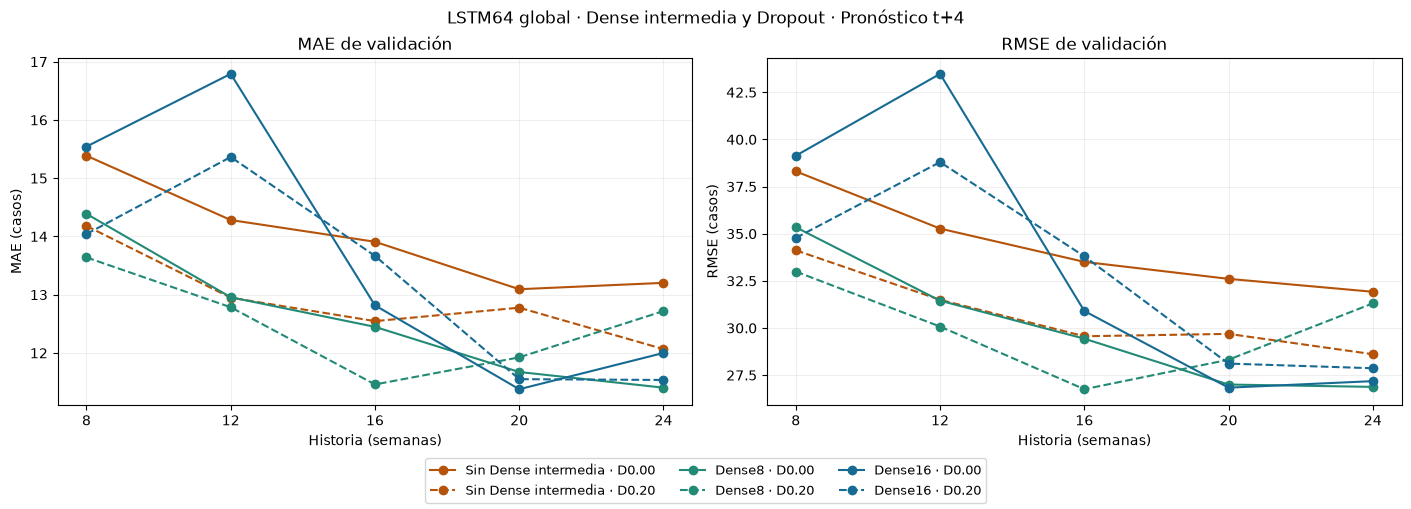

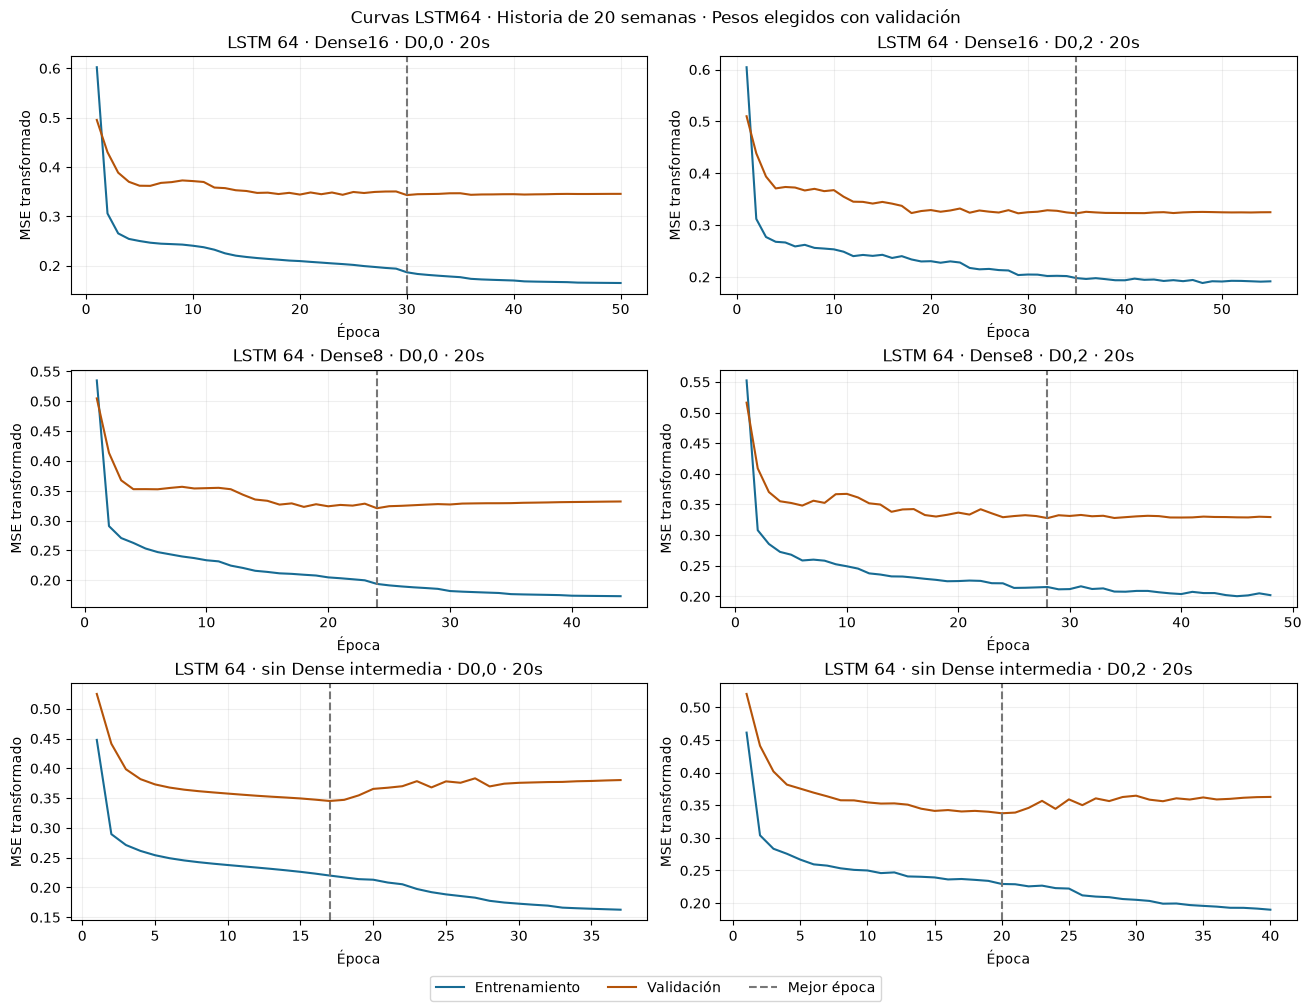

In [76]:
# Comparar seis estructuras de 64 unidades sobre las mismas fechas de validación.
specs_64 = [s for s in catalogo_actual
    if s['TIPO']=='red' and s['CONFIG']['unidades']==[64]]
assert len(specs_64)==6*len(HISTORIAS)
config_64 = pd.DataFrame([{'ID':s['ID'], 'DENSE':s['CONFIG']['dense'],
    'DROPOUT':s['CONFIG']['dropout']} for s in specs_64])
comparacion_lstm64 = ranking_validacion.merge(config_64,on='ID',validate='one_to_one')
train_64 = metricas_desarrollo.loc[metricas_desarrollo.CONJUNTO.eq('training'),
    ['ID','MAE','RMSE']].rename(columns={'MAE':'MAE_TRAIN','RMSE':'RMSE_TRAIN'})
comparacion_lstm64 = comparacion_lstm64.merge(train_64,on='ID',validate='one_to_one').merge(
    registro_entrenamiento_redes[['ID_RED','MEJOR_EPOCA','EPOCAS_EJECUTADAS']],
    left_on='ID',right_on='ID_RED',validate='one_to_one')
comparacion_lstm64 = comparacion_lstm64.sort_values(['MAE','RMSE','ID']).reset_index(drop=True)
display(comparacion_lstm64[['MODELO','HISTORIA','PARAMETROS_RED','MAE_TRAIN','MAE','RMSE',
    'MEJOR_EPOCA','EPOCAS_EJECUTADAS']].style.format(
    {'PARAMETROS_RED':'{:.0f}','MAE_TRAIN':'{:.3f}','MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))

pares_dropout64 = comparacion_lstm64.loc[comparacion_lstm64.DROPOUT.eq(0),
    ['HISTORIA','DENSE','MAE','RMSE']].merge(
    comparacion_lstm64.loc[comparacion_lstm64.DROPOUT.eq(.2),['HISTORIA','DENSE','MAE','RMSE']],
    on=['HISTORIA','DENSE'],suffixes=('_D0','_D20'),validate='one_to_one')
pares_dropout64['DIFERENCIA_MAE_D0_MENOS_D20'] = pares_dropout64.MAE_D0-pares_dropout64.MAE_D20
pares_dropout64['DIFERENCIA_RMSE_D0_MENOS_D20'] = pares_dropout64.RMSE_D0-pares_dropout64.RMSE_D20
display(pares_dropout64.sort_values(['DENSE','HISTORIA']).style.format(
    {c:'{:.3f}' for c in pares_dropout64.columns if c not in ['HISTORIA','DENSE']}).hide(axis='index'))
RUTA_ANALISIS_64 = RUTA_EJECUCION/'analisis_lstm64'
RUTA_ANALISIS_64.mkdir(exist_ok=True)
comparacion_lstm64.to_csv(RUTA_ANALISIS_64/'comparacion_validacion.csv',index=False,encoding='utf-8-sig')
pares_dropout64.to_csv(RUTA_ANALISIS_64/'efecto_dropout_misma_estructura.csv',index=False,encoding='utf-8-sig')

figura_64,ejes_64 = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
colores_64 = {16:'#176B93',8:'#238A76',0:'#B45309'}
for eje,metrica in zip(ejes_64,['MAE','RMSE']):
    for (dense,dropout),grupo in comparacion_lstm64.groupby(['DENSE','DROPOUT']):
        grupo = grupo.sort_values('HISTORIA')
        nombre = f'Dense{int(dense)}' if dense else 'Sin Dense intermedia'
        eje.plot(grupo.HISTORIA,grupo[metrica],marker='o',color=colores_64[dense],
            linestyle='--' if dropout else '-',label=f'{nombre} · D{dropout:.2f}')
    eje.set(title=f'{metrica} de validación',xlabel='Historia (semanas)',ylabel=f'{metrica} (casos)',xticks=HISTORIAS)
    eje.grid(alpha=.2)
handles_64,labels_64 = ejes_64[0].get_legend_handles_labels()
figura_64.legend(handles_64,labels_64,loc='outside lower center',ncol=3,fontsize=9)
figura_64.suptitle('LSTM64 global · Dense intermedia y Dropout · Pronóstico t+4')
for extension in ['png','svg']:
    figura_64.savefig(RUTA_ANALISIS_64/f'comparacion_historias.{extension}',dpi=220,bbox_inches='tight')
plt.show()

# Curvas de las seis alternativas para la historia con menor MAE entre las LSTM64.
HISTORIA_CURVAS_64 = int(comparacion_lstm64.iloc[0].HISTORIA)
figura_curvas_64,ejes_curvas_64 = plt.subplots(3,2,figsize=(13,10),constrained_layout=True)
for eje,spec in zip(ejes_curvas_64.ravel(),[s for s in specs_64 if s['HISTORIA']==HISTORIA_CURVAS_64]):
    historial_64 = pd.read_csv(spec['HISTORIAL'],encoding='utf-8-sig')
    eje.plot(historial_64.EPOCA,historial_64.loss,label='Entrenamiento',color='#176B93')
    eje.plot(historial_64.EPOCA,historial_64.val_loss,label='Validación',color='#B45309')
    eje.axvline(historial_64.loc[historial_64.val_loss.idxmin(),'EPOCA'],color='#777777',linestyle='--',label='Mejor época')
    eje.set(title=spec['NOMBRE'],xlabel='Época',ylabel='MSE transformado')
    eje.grid(alpha=.2)
handles_curvas_64,labels_curvas_64 = ejes_curvas_64[0,0].get_legend_handles_labels()
figura_curvas_64.legend(handles_curvas_64,labels_curvas_64,loc='outside lower center',ncol=3)
figura_curvas_64.suptitle(f'Curvas LSTM64 · Historia de {HISTORIA_CURVAS_64} semanas · Pesos elegidos con validación')
for extension in ['png','svg']:
    figura_curvas_64.savefig(RUTA_ANALISIS_64/f'curvas_historia_{HISTORIA_CURVAS_64}.{extension}',dpi=200,bbox_inches='tight')
plt.show()


#### 18.4.1. Qué cambió al variar Dense y Dropout

La mejor opción de 64 unidades fue **LSTM 64 · Dense16 · D0,0 · 20s**, con **MAE 11.377 y RMSE 26.837 casos**. Sus mejores pesos quedaron en la época **30**, de **50** ejecutadas. Tiene **19.569 parámetros**.

El menor MAE de cada estructura se resume abajo. La historia puede cambiar entre filas; para revisar Dropout sin ese cambio utilizamos las parejas de la tabla anterior.

| Dense intermedia | Dropout | Historia | MAE | RMSE |
| --- | ---: | ---: | ---: | ---: |
| Dense16 | 0.00 | 20 | 11.377 | 26.837 |
| Dense16 | 0.20 | 24 | 11.536 | 27.867 |
| Dense8 | 0.00 | 24 | 11.404 | 26.879 |
| Dense8 | 0.20 | 16 | 11.459 | 26.755 |
| Sin intermedia | 0.00 | 20 | 13.094 | 32.607 |
| Sin intermedia | 0.20 | 24 | 12.066 | 28.611 |

Con la misma Dense y la misma historia, Dropout de 0,20 redujo el MAE en **11 de 15 parejas** y el RMSE en **10 de 15**. Por eso el efecto de Dropout se interpreta a partir de esas diferencias, sin dar por hecho que mejore todas las configuraciones.

El mejor LSTM64 también fue el elegido general por MAE de validación.

Los resultados corresponden a una semilla y al bloque 2022–2023. La comparación permite escoger una configuración, pero no demuestra que una diferencia pequeña vaya a repetirse en otro periodo.

En las curvas con Dropout, el entrenamiento lo aplica y la validación lo desactiva. Esa diferencia también influye en la separación entre las curvas. Las métricas de casos de ambos conjuntos se calculan al pronosticar, con Dropout desactivado.


### 18.5. Revisar si faltaron épocas

La tabla distingue cuántas épocas se ejecutaron, en cuál quedó el mejor resultado y si se llegó al límite de 200. Detenerse antes del máximo no significa que se haya entrenado poco: puede indicar que la pérdida de validación dejó de mejorar durante la paciencia establecida. Las métricas utilizan los mejores pesos y no los de la última época.


In [77]:
resumen_epocas = registro_entrenamiento_redes.copy()
resumen_epocas['GRUPO'] = np.where(resumen_epocas.ID_RED.str.startswith('local_'),'Local','Global')
resumen_epocas['LLEGO_AL_LIMITE'] = resumen_epocas.EPOCAS_EJECUTADAS.eq(EPOCAS_MAX)
resumen_epocas['MEJOR_DESPUES_DE_100'] = resumen_epocas.MEJOR_EPOCA.gt(100)
resumen_epocas_grupos = resumen_epocas.groupby('GRUPO').agg(REDES=('ID_RED','size'),
    EPOCAS_MIN=('EPOCAS_EJECUTADAS','min'),EPOCAS_MEDIANA=('EPOCAS_EJECUTADAS','median'),
    EPOCAS_MAX=('EPOCAS_EJECUTADAS','max'),AL_LIMITE=('LLEGO_AL_LIMITE','sum'),
    MEJOR_DESPUES_DE_100=('MEJOR_DESPUES_DE_100','sum')).reset_index()
display(resumen_epocas_grupos)
display(resumen_epocas.loc[resumen_epocas.LLEGO_AL_LIMITE | resumen_epocas.MEJOR_DESPUES_DE_100,
    ['ID_RED','N_TRAIN','PARAMETROS','MEJOR_EPOCA','EPOCAS_EJECUTADAS','LLEGO_AL_LIMITE']])
resumen_epocas.to_csv(RUTA_EJECUCION/'tablas/revision_epocas.csv',index=False,encoding='utf-8-sig')


,GRUPO,REDES,EPOCAS_MIN,EPOCAS_MEDIANA,EPOCAS_MAX,AL_LIMITE,MEJOR_DESPUES_DE_100
0,Global,70,30,49.5,119,0,0
1,Local,75,29,69.0,200,4,15


,ID_RED,N_TRAIN,PARAMETROS,MEJOR_EPOCA,EPOCAS_EJECUTADAS,LLEGO_AL_LIMITE
74,local_v8_76892,756,5665,151,171,False
104,local_compacta16_8_v12_76892,756,1681,137,157,False
108,local_compacta16_8_v16_76834,756,1681,139,159,False
109,local_compacta16_8_v16_76892,756,1681,200,200,True
121,local_compacta8_4_v8_76111,756,553,200,200,True
122,local_compacta8_4_v8_76520,756,553,161,181,False
123,local_compacta8_4_v8_76834,756,553,200,200,True
124,local_compacta8_4_v8_76892,756,553,117,137,False
127,local_compacta8_4_v12_76520,756,553,158,178,False
132,local_compacta8_4_v16_76520,756,553,102,122,False


De las **145 redes**, **15** encontraron su menor pérdida de validación después de la época 100 y **4** alcanzaron el nuevo límite de 200. Entre las 30 LSTM64, **0** tuvieron su mejor época después de 100 y **0** llegaron al límite.

Las cinco referencias LSTM64 + Dense16 sin Dropout permiten revisar el cambio de presupuesto conservando la arquitectura y la historia:

| Historia | MAE anterior | MAE actual | Mejor época anterior | Mejor época actual | Épocas ejecutadas actuales |
| --- | ---: | ---: | ---: | ---: | ---: |
| 8 | 15.543 | 15.543 | 29 | 29 | 49 |
| 12 | 16.791 | 16.791 | 23 | 23 | 43 |
| 16 | 12.817 | 12.817 | 26 | 26 | 46 |
| 20 | 11.377 | 11.377 | 30 | 30 | 50 |
| 24 | 12.000 | 12.000 | 37 | 37 | 57 |

Entre los **60 enfoques LSTM que ya existían**, el MAE bajó en **12**, subió en **5** y se mantuvo dentro de una diferencia de 0,000001 casos en **43**. La siguiente tabla muestra los cinco mayores cambios absolutos. El cambio es MAE actual menos anterior: un número negativo indica mejora.

| Modelo | MAE anterior | MAE actual | Cambio |
| --- | ---: | ---: | ---: |
| LSTM 32→16→8 · Dense16 · D0,20 · 12s | 18.789 | 16.105 | -2.684 |
| LSTM local 8 · Dense4 (5 redes) · 12s | 19.627 | 17.394 | -2.234 |
| LSTM 32 · Dense16 · D0,20 · 24s | 13.778 | 11.677 | -2.101 |
| LSTM local 8 · Dense4 (5 redes) · 24s | 20.639 | 18.620 | -2.019 |
| LSTM local 8 · Dense4 (5 redes) · 20s | 20.488 | 18.500 | -1.988 |

En esta revisión ampliamos dos reglas a la vez: máximo de épocas y paciencia. No separamos cuánto aporta cada una. Las nuevas arquitecturas y las anteriores se comparan con el presupuesto actual; no mezclamos sus métricas de entrenamiento para elegir el ganador.

Las redes que llegaron al límite podrían necesitar otra revisión de sus curvas. Llegar al máximo no prueba que más épocas vayan a mejorar el MAE: el mejor MSE transformado y el menor error en casos pueden quedar en momentos distintos.

## 19. Discusión de los resultados de validación

En esta sección reunimos lo que muestran las métricas y las curvas. La elección se hace por el menor MAE de validación entre todos los enfoques entrenados. RMSE, sesgo y resultados municipales ayudan a interpretar esa decisión, sin cambiar el criterio después de ver test.


El modelo que elegimos para continuar es **LSTM 64 · Dense16 · D0,0 · 20s**, porque tuvo el menor MAE de validación: **11.377 casos**, con RMSE de **26.837**. La decisión se tomó entre todos los enfoques entrenados y no depende de que el modelo tenga Dropout, más capas o una arquitectura determinada.

En entrenamiento obtuvo MAE de **7.743** y RMSE de **21.898**. La diferencia con validación describe cómo se trasladó el ajuste a 2022–2023, pero no permite separar por sí sola sobreajuste y cambios en el volumen de casos entre periodos.

Las cinco historias se compararon con los mismos **3.780 objetivos de entrenamiento y 505 de validación**. Por eso, las ventanas largas no recibieron más fechas de entrenamiento. La comparación modifica cuántas semanas puede observar cada modelo antes de pronosticar. Los resultados por historia y estructura están en las tablas y figuras del punto 18.

El mejor baseline fue **XGBoost · 24s**, con MAE 14.759 y RMSE 36.342. La mejor referencia local fue **LSTM local 16 · Dense8 (5 redes) · 24s**, con 12.872 y 30.108. Estas referencias se fijan con validación y acompañan al elegido al cierre.

La diferencia de errores entre municipios debe leerse junto con sus cantidades de casos. Una buena métrica agregada puede ocultar semanas o ciudades difíciles; por eso revisamos el sesgo, los años por separado y los mayores errores. La evaluación posterior utiliza los pesos ya elegidos y no cambia retrospectivamente la selección.

La siguiente tabla reúne el menor MAE observado para cada historia. La arquitectura puede cambiar entre filas: esta comparación no aísla el efecto de añadir semanas.

| Historia | Modelo | MAE | RMSE |
| --- | --- | ---: | ---: |
| 8 semanas | LSTM 64 · Dense8 · D0,2 · 8s | 13.640 | 32.995 |
| 12 semanas | LSTM 32 · Dense16 · D0 · 12s | 11.908 | 27.722 |
| 16 semanas | LSTM 64 · Dense8 · D0,2 · 16s | 11.459 | 26.755 |
| 20 semanas | LSTM 64 · Dense16 · D0,0 · 20s | 11.377 | 26.837 |
| 24 semanas | LSTM 64 · Dense8 · D0,0 · 24s | 11.404 | 26.879 |


En las opciones de 64 unidades, la mejor opción de 64 unidades fue **LSTM 64 · Dense16 · D0,0 · 20s**, con **MAE 11.377 y RMSE 26.837 casos**. Sus mejores pesos quedaron en la época **30**, de **50** ejecutadas. Tiene **19.569 parámetros**.

La revisión del presupuesto de entrenamiento y las parejas con/sin Dropout se detallan en 18.4 y 18.5.


**Comparación de cada variante con su arquitectura de referencia.**

La siguiente tabla calcula las diferencias usando los resultados de validación de la misma familia e historia. Una mejora porcentual de MAE positiva indica que la variante redujo el error; un cambio de RMSE negativo también indica una reducción. La tabla permite revisar las comparaciones que sustentan las conclusiones anteriores.


In [78]:
# Comparar los errores de validación de cada variante con su referencia.
filas_cambios_arquitecturas = []
for familia in ['LSTM']:
    for historia in HISTORIAS:
        referencia = ranking_validacion.loc[
            ranking_validacion['ID'].eq(f'{familia.lower()}_referencia_v{historia}')].iloc[0]
        variantes = ['sin_dense', 'drop20', 'drop50', 'dos_capas', 'tres_capas']
        if familia == 'LSTM':
            variantes.append('compacta16_8')
        for receta in variantes:
            variante = ranking_validacion.loc[
                ranking_validacion['ID'].eq(f'{familia.lower()}_{receta}_v{historia}')].iloc[0]
            filas_cambios_arquitecturas.append({
                'FAMILIA': familia,
                'HISTORIA': historia,
                'RECETA': receta,
                'MAE_REFERENCIA': referencia['MAE'],
                'MAE_VARIANTE': variante['MAE'],
                'MEJORA_MAE_PCT': 100 * (referencia['MAE'] - variante['MAE']) / referencia['MAE'],
                'CAMBIO_RMSE': variante['RMSE'] - referencia['RMSE'],
            })
cambios_arquitecturas = pd.DataFrame(filas_cambios_arquitecturas)

display(cambios_arquitecturas.style.format({'MAE_REFERENCIA':'{:.3f}','MAE_VARIANTE':'{:.3f}',
    'MEJORA_MAE_PCT':'{:.2f}','CAMBIO_RMSE':'{:+.3f}'}).hide(axis='index'))
cambios_arquitecturas.to_csv(RUTA_EJECUCION/'tablas/cambios_frente_referencia.csv',index=False,encoding='utf-8-sig')


FAMILIA,HISTORIA,RECETA,MAE_REFERENCIA,MAE_VARIANTE,MEJORA_MAE_PCT,CAMBIO_RMSE
LSTM,8,sin_dense,14.334,16.357,-14.11,+4.546
LSTM,8,drop20,14.334,13.847,3.39,-1.146
LSTM,8,drop50,14.334,15.216,-6.15,+2.695
LSTM,8,dos_capas,14.334,13.745,4.11,-1.136
LSTM,8,tres_capas,14.334,15.848,-10.57,+4.671
LSTM,8,compacta16_8,14.334,14.243,0.64,-0.556
LSTM,12,sin_dense,11.908,14.947,-25.52,+8.239
LSTM,12,drop20,11.908,13.014,-9.29,+3.795
LSTM,12,drop50,11.908,14.260,-19.76,+7.886
LSTM,12,dos_capas,11.908,14.503,-21.79,+8.330


### 19.1. Relacionar los resultados con los antecedentes

**Zhao et al. (2020)** compararon Random Forest con datos agrupados y modelos locales a escala departamental en Colombia. Utilizaron 12 semanas de historia y distintas anticipaciones. Su trabajo sirve como referencia para estudiar la cantidad de historia y el uso de información de varios lugares. Nuestro análisis es municipal y tiene un único objetivo, t+4, por lo que sus errores no son directamente comparables con los nuestros.

**Benedum et al. (2020)** estudiaron tanto el pronóstico de casos como la clasificación de semanas de brote, con 26 semanas de historia y anticipaciones de 4 y 12 semanas. Evaluaron los modelos avanzando en el tiempo y reentrenándolos por año. Ese procedimiento ofrece una referencia para ampliar nuestro análisis con otros cortes cronológicos, además del bloque fijo de validación que usamos aquí.

**Schlesinger et al. (2024)** evaluaron EWARS-csd en 11 municipios colombianos, con clima y hospitalizaciones, y midieron su capacidad para anticipar brotes. Su objetivo y su modelo DLNM–INLA son distintos de nuestra regresión de casos. Esta diferencia importa al interpretar el alcance del trabajo: un error de pronóstico bajo no demuestra por sí solo que podamos detectar brotes.


### 19.2. Reconocer las limitaciones

La comparación tiene varias limitaciones que debemos considerar al interpretar los resultados:

- Los cinco municipios se eligieron por su volumen de casos en 2007–2023. Los errores representan esos municipios y esas cantidades, no tasas ajustadas por población ni resultados para todo el departamento.
- Contamos registros según `ANO` y `SEMANA`, después de excluir filas sin `INI_SIN`. Las filas coincidentes se conservan, por lo que no se ha comprobado que cada una corresponda a un episodio único. También falta confirmar con el diccionario de vigilancia que las semanas de casos y clima tengan el mismo significado.
- Completar las semanas sin registros con cero supone que hubo cobertura de notificación. Los archivos no permiten distinguir siempre una ausencia real de casos de una falla de reporte.
- Suponemos que los casos y el clima hasta t estaban disponibles al emitir el pronóstico. No reconstruimos retrasos de notificación ni revisiones posteriores de los datos.
- No contamos con población, información entomológica, movilidad, serotipos o intervenciones. El análisis permite comparar predicciones, pero no identificar efectos causales del clima.
- La salida lineal puede producir valores negativos. Se conservan y contabilizan en las métricas; cualquier tratamiento distinto tendría que definirse y validarse antes de usar el modelo.
- Las ventanas se solapan y probamos varias configuraciones con una sola semilla sobre la misma validación. Faltan otros cortes temporales, semillas y referencias de persistencia o estacionales para estudiar la estabilidad. Tampoco se ha evaluado el beneficio de usar estos pronósticos en una intervención sanitaria.


### 19.3. Qué aportó reducir las redes locales

**LSTM32 + Dense16** obtuvo su menor MAE con **16 semanas**: MAE **14.936** y RMSE **35.790**.

**LSTM16 + Dense8** obtuvo su menor MAE con **24 semanas**: MAE **12.872** y RMSE **30.108**.

**LSTM8 + Dense4** obtuvo su menor MAE con **8 semanas**: MAE **16.133** y RMSE **40.939**.

La mejor referencia local general fue **LSTM local 16 · Dense8 (5 redes) · 24s**. Las versiones pequeñas redujeron el MAE de su referencia de igual historia en **5 de diez comparaciones**. Las curvas muestran cómo cambia el ajuste por municipio; estos resultados no permiten atribuir todas las diferencias al sobreajuste. Cambiamos dos capas a la vez y solo utilizamos una semilla y un bloque temporal.

De las **50 redes locales compactas**, **4 alcanzaron el límite de 200 épocas**. Ese máximo fue el mismo para todos los tamaños. Por tanto, también debemos tener en cuenta el límite de entrenamiento al interpretar las curvas.

La selección general también considera los globales y los baselines. El mejor local se conserva como referencia con una sola estructura e historia para los cinco municipios.


## 20. Evaluación final con el conjunto de prueba

Evaluamos en 2024–2025 el modelo elegido por **menor MAE de validación**. Antes de abrir test se guardan su identificador y las referencias de menor MAE de cada familia. Se utilizan los pesos ya entrenados y los escaladores de entrenamiento, sin reajustarlos con test.

En cada emisión usamos casos y clima observados hasta t para pronosticar la semana t+4. El test avanza semana a semana, incorporando la historia observada disponible. No es una predicción de dos años emitida de una sola vez.

Este periodo ya se había observado antes de esta comparación. La evaluación describe el desempeño sobre esas fechas y no se presenta como una prueba ciega. La selección no cambia por sus resultados.

### 20.1. Calcular el desempeño en test


In [79]:
EJECUTAR_EVALUACION_FINAL = True
assert EJECUTAR_EVALUACION_FINAL
assert all(s['ENTRENADO_EN_ESTA_EJECUCION'] and s['EJECUCION']==RUTA_EJECUCION.name for s in catalogo_actual)
ID_ELEGIDO_AL_CIERRE = seleccion_validacion['ID_ELEGIDO']

nivel_log_tensorflow_evaluacion = tf.get_logger().level
try:
    tf.get_logger().setLevel('ERROR')
    (predicciones_evaluacion_cierre, metricas_evaluacion_cierre, metricas_municipales_cierre,
     _, RUTA_EVALUACION_CIERRE) = evaluar_al_cierre(
        RUTA_EJECUCION, secuencias_desarrollo, preprocesamiento_actual,
        catalogo_actual, ranking_validacion, seleccion_validacion)
finally:
    tf.get_logger().setLevel(nivel_log_tensorflow_evaluacion)

assert seleccion_validacion['ID_ELEGIDO']==ID_ELEGIDO_AL_CIERRE
metricas_evaluacion_cierre['ROL'] = np.where(
    metricas_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE), 'Modelo elegido', 'Referencia de validación')
metricas_evaluacion_cierre.to_csv(RUTA_EVALUACION_CIERRE/'metricas.csv',index=False,encoding='utf-8-sig')
display(metricas_evaluacion_cierre[['ROL','MODELO','HISTORIA','N','MAE','RMSE','SESGO_MEDIO','PRONOSTICOS_NEGATIVOS']]
    .style.format({'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:+.3f}'}).hide(axis='index'))

ROL,MODELO,HISTORIA,N,MAE,RMSE,SESGO_MEDIO,PRONOSTICOS_NEGATIVOS
Modelo elegido,"LSTM 64 · Dense16 · D0,0 · 20s",20,510,38.139,95.413,-10.451,0
Referencia de validación,LSTM local 16 · Dense8 (5 redes) · 24s,24,510,48.849,112.727,-30.484,0
Referencia de validación,Regresión lineal · 12s,12,510,31.285,78.708,-8.685,0
Referencia de validación,Random Forest · 24s,24,510,43.465,104.825,-34.227,0
Referencia de validación,XGBoost · 24s,24,510,40.596,95.975,-32.174,0


### 20.2. Revisar los resultados por municipio

La tabla muestra el error de el modelo elegido en cada municipio. Las métricas están en casos de dengue, después de deshacer la transformación con el escalador correspondiente. El sesgo es pronosticado menos real: un valor negativo indica que, en promedio, el modelo se quedó por debajo de los casos observados. Conservamos los pronósticos continuos, incluidos los negativos, sin redondearlos ni recortarlos.

In [80]:
metricas_municipales_modelo_elegido = metricas_municipales_cierre.loc[
    metricas_municipales_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].copy()
display(metricas_municipales_modelo_elegido[
    ['MUNICIPIO','N','MAE','RMSE','SESGO_MEDIO','PRONOSTICOS_NEGATIVOS']].style.format(
        {'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:+.3f}'}).hide(axis='index'))
metricas_municipales_modelo_elegido.to_csv(
    RUTA_EVALUACION_CIERRE/'metricas_municipales_modelo_elegido.csv',index=False,encoding='utf-8-sig')

MUNICIPIO,N,MAE,RMSE,SESGO_MEDIO,PRONOSTICOS_NEGATIVOS
CALI,102,106.906,191.654,-33.853,0
GUADALAJARA DE BUGA,102,25.625,49.948,-19.903,0
PALMIRA,102,26.161,67.450,+19.470,0
TULUA,102,18.918,36.453,-13.025,0
YUMBO,102,13.087,20.342,-4.945,0


#### 20.2.1. Separar los dos años de evaluación

El promedio de los dos años puede ocultar periodos muy distintos. Esta tabla separa los objetivos de 2024 y 2025 para el modelo elegido y muestra también el promedio de casos observados por municipio y semana. Son cantidades de casos, sin ajuste por población.


In [81]:
predicciones_test_modelo_elegido = predicciones_evaluacion_cierre.loc[
    predicciones_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].copy()
filas_evaluacion_por_ano = []
for ano, grupo in predicciones_test_modelo_elegido.groupby(
        predicciones_test_modelo_elegido['FECHA_OBJETIVO'].dt.year,sort=True):
    errores = grupo['CASOS_PREDICHOS']-grupo['CASOS_REALES']
    filas_evaluacion_por_ano.append({'ANO_OBJETIVO':ano,'N':len(grupo),
        'CASOS_MEDIOS':grupo['CASOS_ORIGINALES'].mean(),
        'MAE':errores.abs().mean(),'RMSE':np.sqrt((errores**2).mean()),'SESGO_MEDIO':errores.mean()})
metricas_evaluacion_por_ano = pd.DataFrame(filas_evaluacion_por_ano)
display(metricas_evaluacion_por_ano.style.format({'CASOS_MEDIOS':'{:.3f}',
    'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:+.3f}'}).hide(axis='index'))
metricas_evaluacion_por_ano.to_csv(RUTA_EVALUACION_CIERRE/'metricas_anuales_modelo_elegido.csv',
    index=False,encoding='utf-8-sig')


ANO_OBJETIVO,N,CASOS_MEDIOS,MAE,RMSE,SESGO_MEDIO
2024,250,204.584,72.714,136.023,-23.249
2025,260,15.688,4.894,8.155,+1.854


### 20.3. Comparar entrenamiento, validación y test

Para cada municipio mostramos los casos observados y los pronósticos t+4 de los mismos modelos en los tres periodos. La leyenda conserva sus nombres y cada panel identifica el conjunto utilizado. Las escalas verticales se ajustan por panel para facilitar la lectura; debemos revisar los valores del eje al comparar periodos.

Las gráficas de entrenamiento describen el ajuste y las de validación corresponden al periodo que usamos para comparar configuraciones. El panel de test muestra cómo se comportaron esos pesos al avanzar sobre fechas posteriores. La tabla siguiente reúne MAE y RMSE de los tres conjuntos.

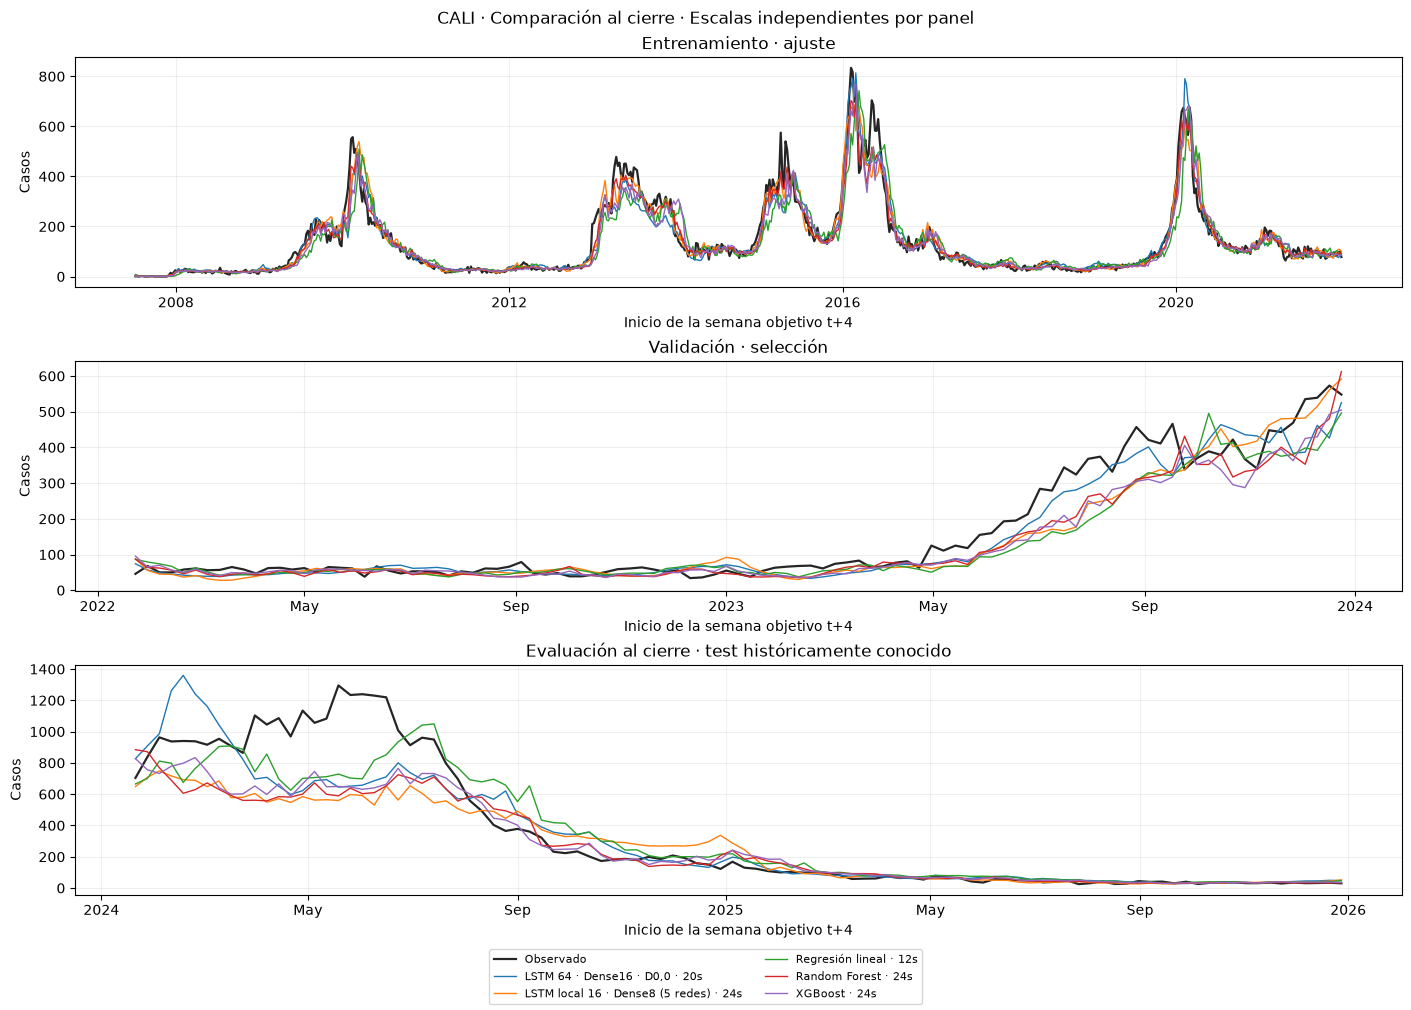

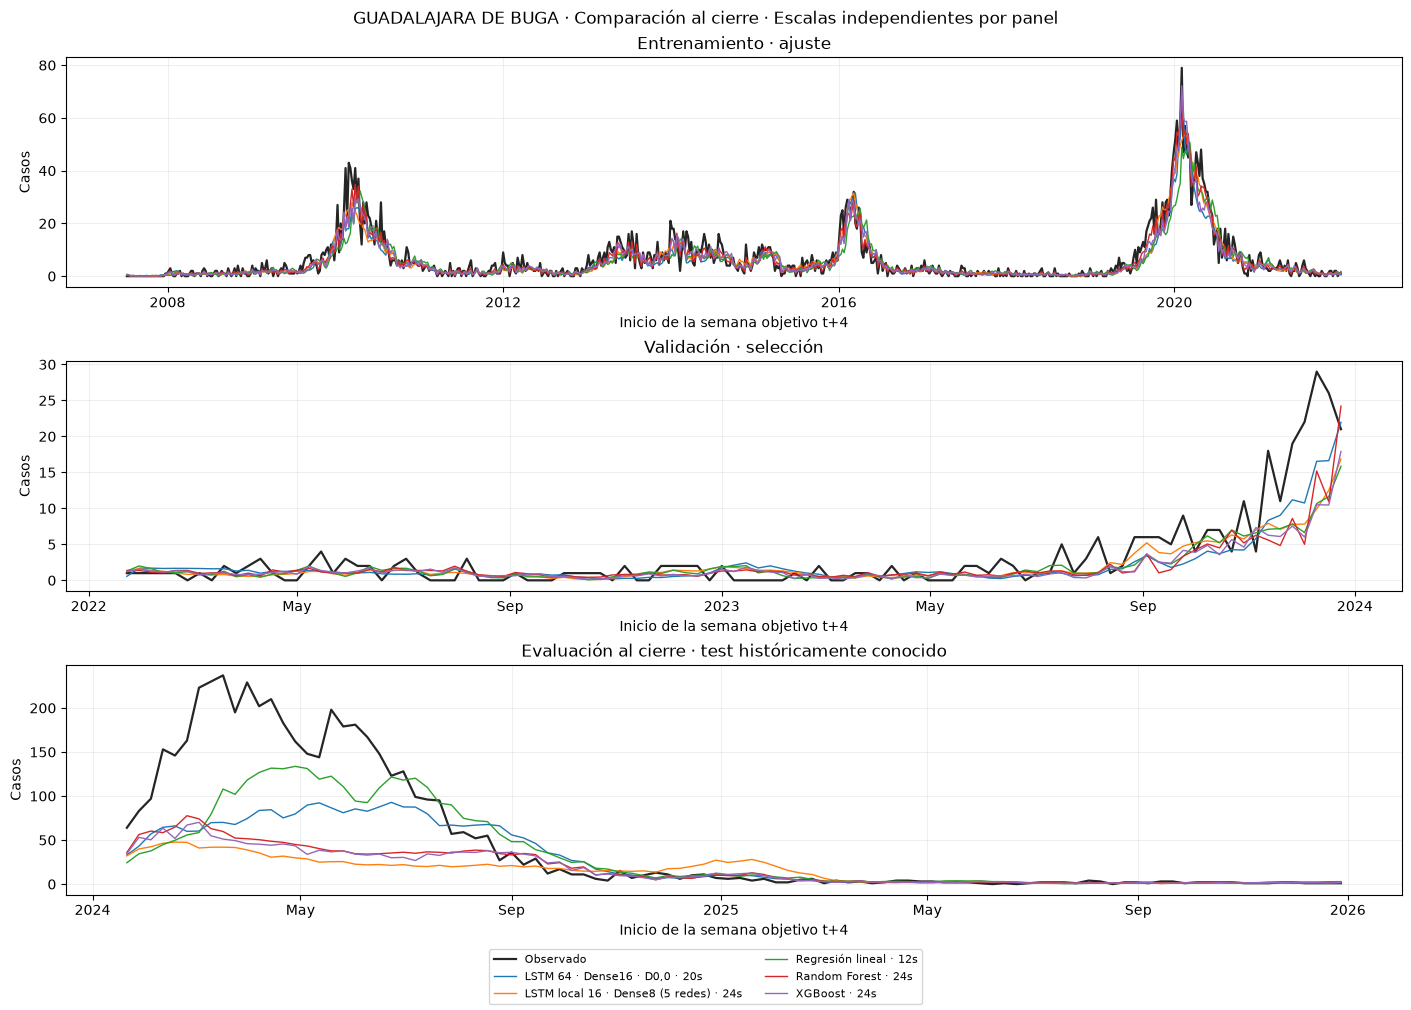

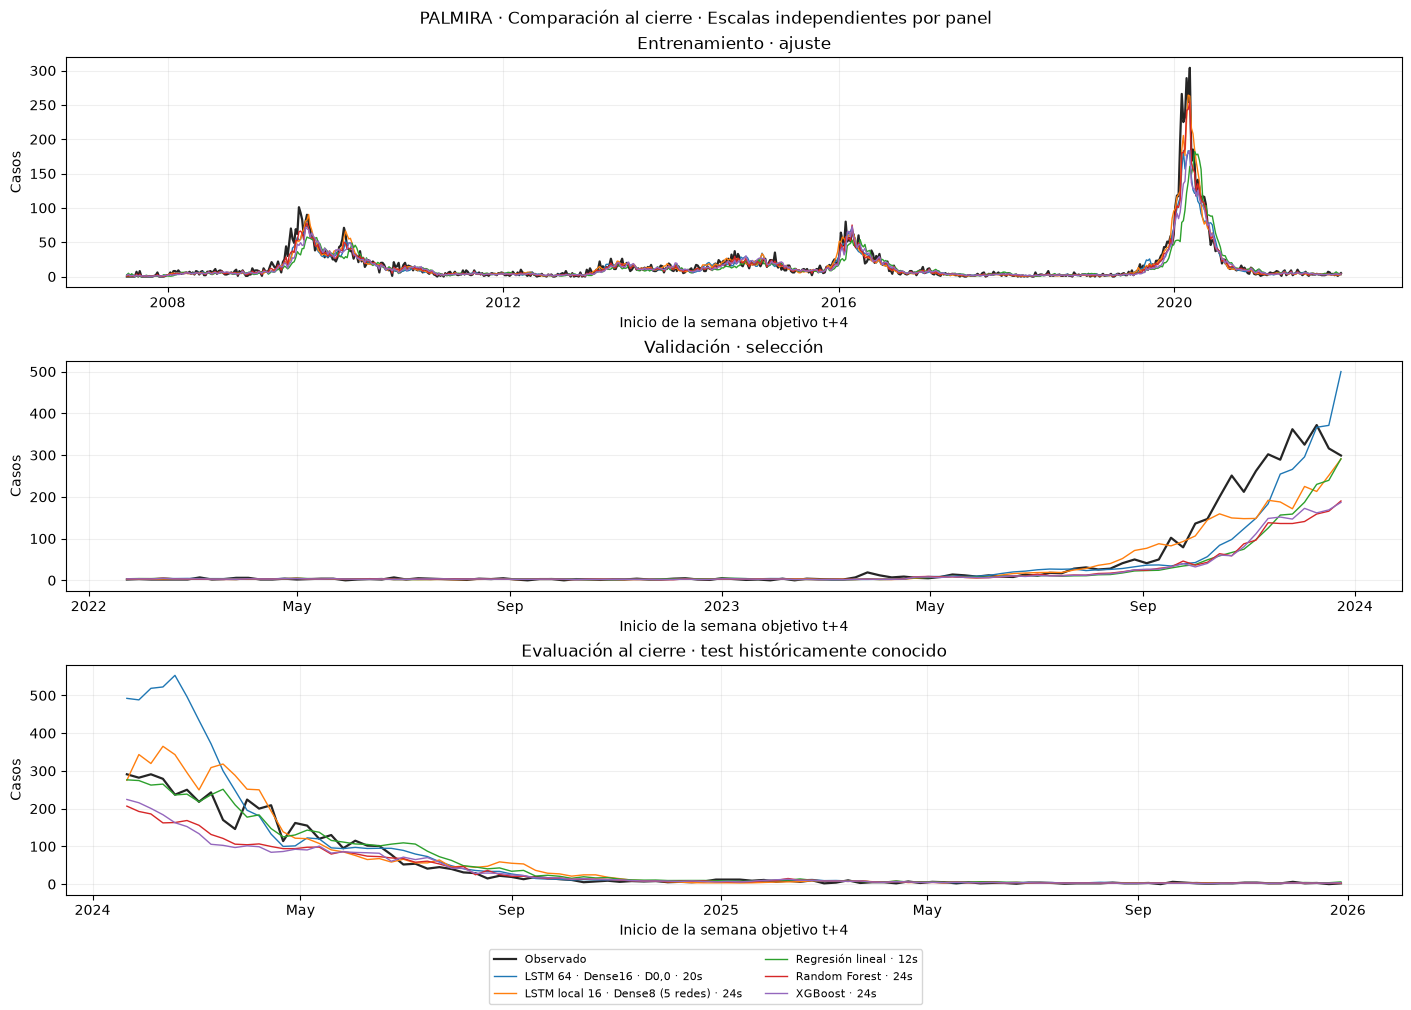

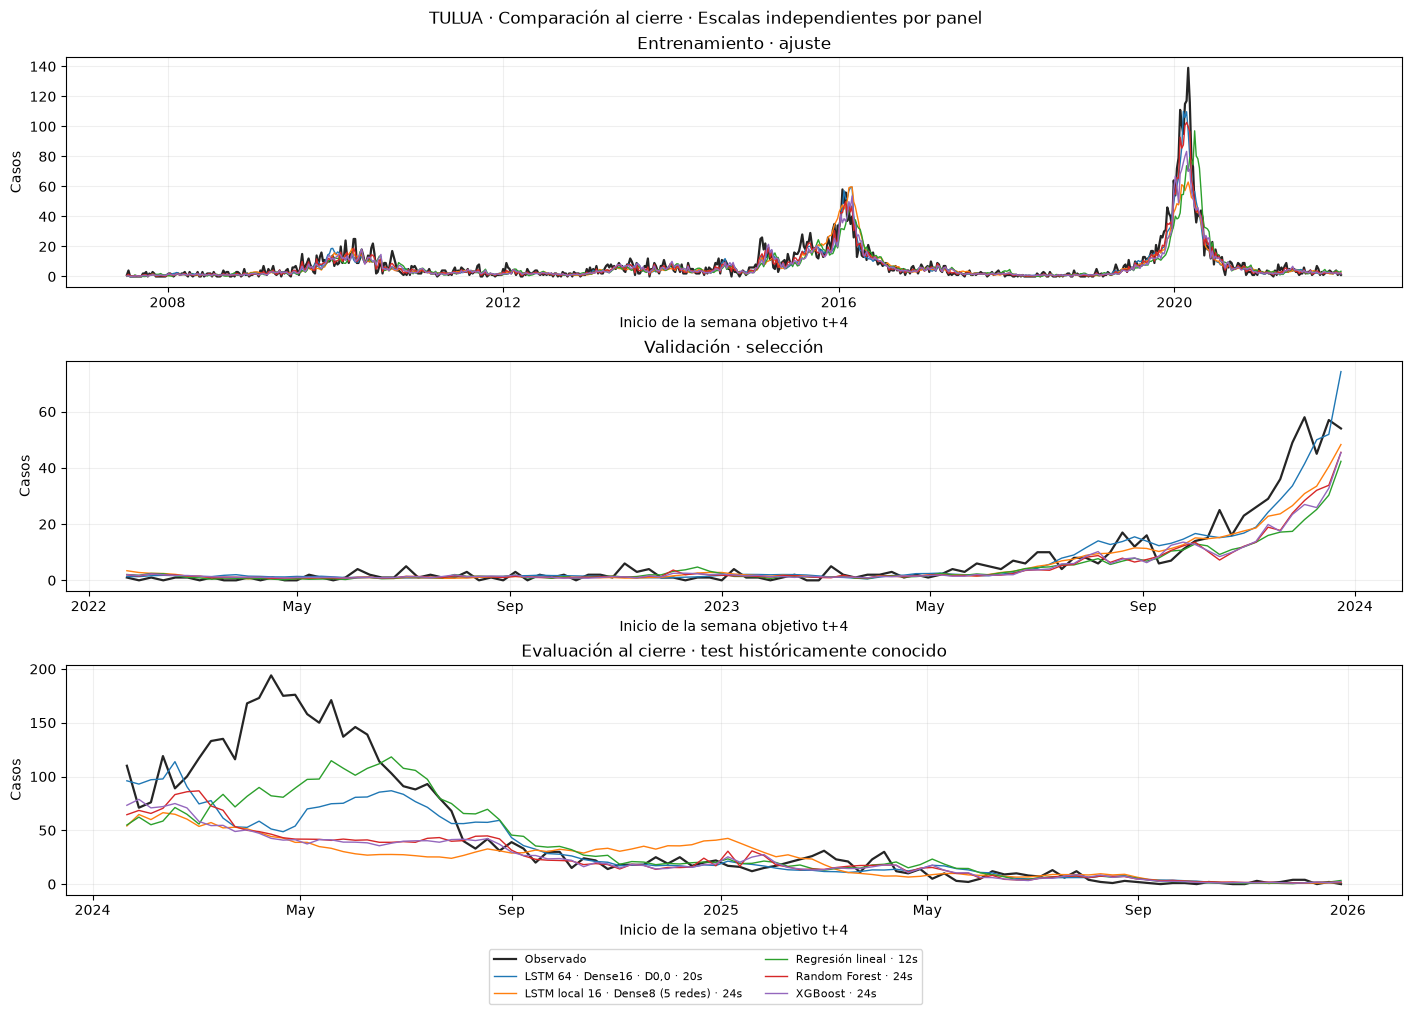

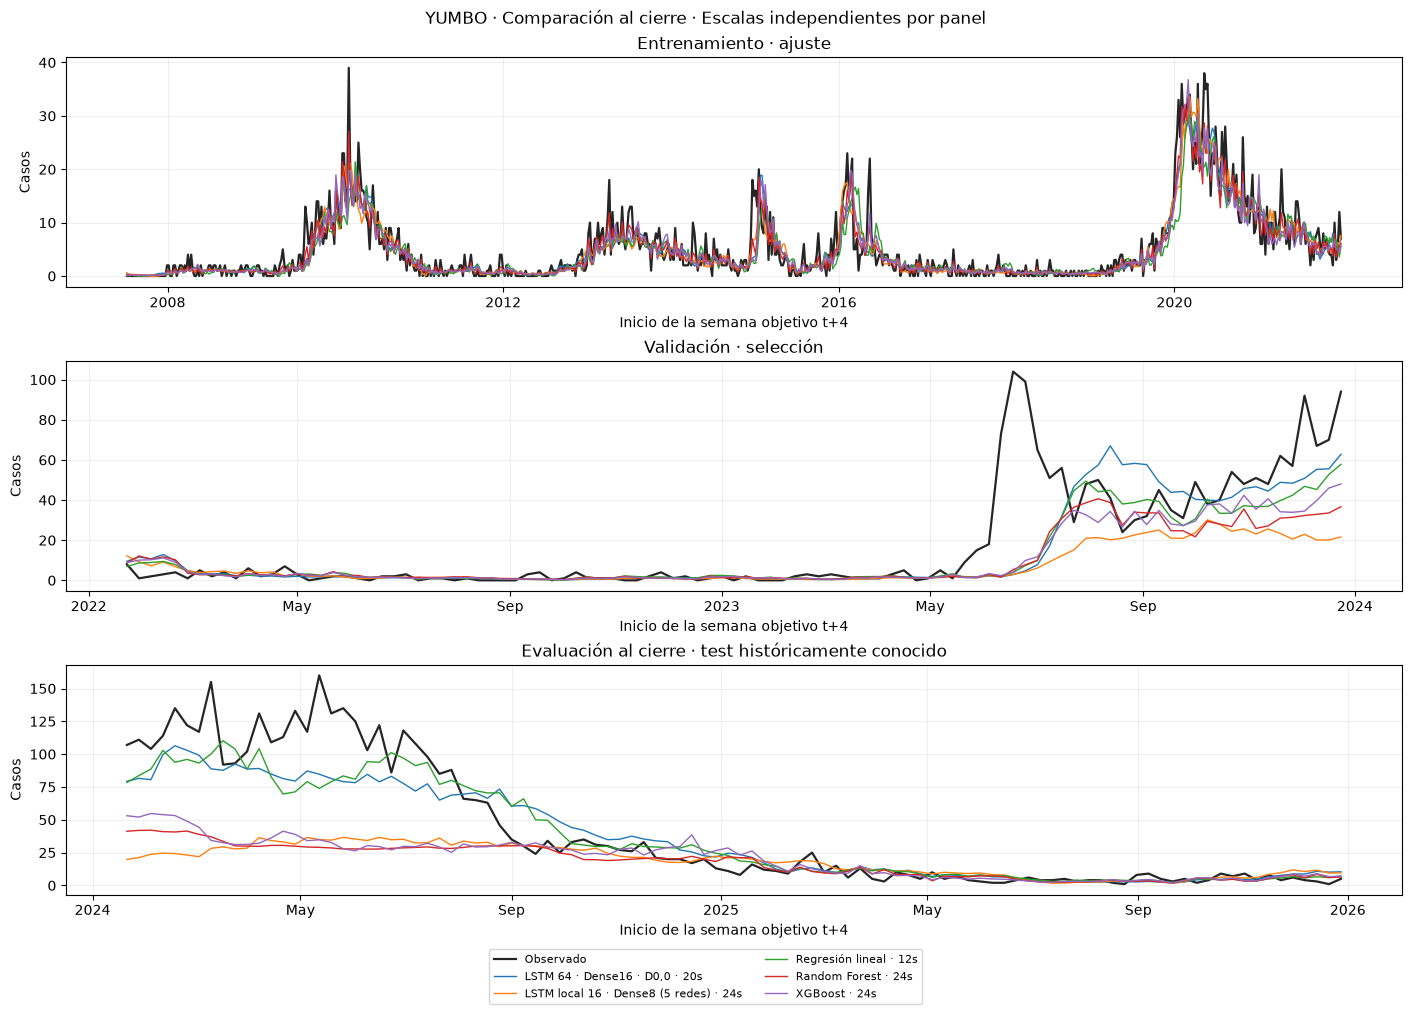

In [82]:
metricas_tres_conjuntos_cierre, figuras_finales = graficar_al_cierre(
    predicciones_desarrollo, predicciones_evaluacion_cierre, RUTA_EVALUACION_CIERRE)
comparacion_tres_conjuntos_cierre = metricas_tres_conjuntos_cierre.pivot(
    index='MODELO',columns='CONJUNTO',values=['MAE','RMSE'])
comparacion_tres_conjuntos_cierre = comparacion_tres_conjuntos_cierre.reindex(
    columns=pd.MultiIndex.from_product([['MAE','RMSE'],['training','validation','evaluation']],
        names=comparacion_tres_conjuntos_cierre.columns.names))
display(comparacion_tres_conjuntos_cierre.style.format('{:.3f}'))

### 20.4. Guardar el modelo seleccionado

Guardamos el enfoque elegido por MAE de validación junto con los escaladores, el codificador municipal, las variables y la configuración. Si se selecciona un enfoque local, se guardan sus cinco redes. La exportación utiliza los mismos archivos evaluados, sin volver a entrenar con validación o test.

Comprobamos la carga de los archivos y reproducimos una predicción de validación por municipio. En la carpeta exportada quedan un ejemplo de entradas, sus resultados y un script para comprobar la carga.


El paquete que vamos a incluir en el repositorio queda en **ModeloSeleccionado/**, en la raíz del proyecto. Allí están el modelo, los escaladores, la configuración y el ejemplo de carga. Esta copia se actualiza cada vez que ejecutamos el punto 20.4 y sus archivos están permitidos en el .gitignore. La copia de cada corrida se conserva también en ResultadosModelos/ como historial local.


In [83]:
# Copiar el modelo que obtuvo el menor MAE de validación, cualquiera que sea su familia.
especificacion_modelo_exportado = next(s for s in catalogo_actual if s['ID']==ID_ELEGIDO_AL_CIERRE)
RUTA_MODELO_EXPORTADO = RUTA_EVALUACION_CIERRE/'modelo_elegido'
RUTA_MODELO_EXPORTADO.mkdir(parents=True,exist_ok=True)
especificacion_copia = {**especificacion_modelo_exportado}
archivos_portables = {}
if especificacion_modelo_exportado['TIPO']=='local':
    (RUTA_MODELO_EXPORTADO/'modelos').mkdir(exist_ok=True)
    especificacion_copia['ARCHIVO'] = {}
    for codigo,origen in especificacion_modelo_exportado['ARCHIVO'].items():
        destino = RUTA_MODELO_EXPORTADO/'modelos'/f'{codigo}.keras'
        shutil.copy2(origen,destino)
        especificacion_copia['ARCHIVO'][codigo] = destino.as_posix()
        archivos_portables[codigo] = destino.relative_to(RUTA_MODELO_EXPORTADO).as_posix()
else:
    origen = Path(especificacion_modelo_exportado['ARCHIVO'])
    destino = RUTA_MODELO_EXPORTADO/f'modelo{origen.suffix}'
    shutil.copy2(origen,destino)
    especificacion_copia['ARCHIVO'] = destino.as_posix()
    archivos_portables = destino.name
shutil.copy2(RUTA_EJECUCION/'preprocesamiento_actual.joblib',RUTA_MODELO_EXPORTADO/'preprocesamiento.joblib')
shutil.copy2('requirements-lock.txt',RUTA_MODELO_EXPORTADO/'requirements-lock.txt')

historia_exportada = int(especificacion_modelo_exportado['HISTORIA'])
configuracion_modelo_exportado = {
    'ID':ID_ELEGIDO_AL_CIERRE,'nombre':especificacion_modelo_exportado['NOMBRE'],
    'tipo':especificacion_modelo_exportado['TIPO'],'archivos':archivos_portables,
    'arquitectura':especificacion_modelo_exportado['CONFIG'],
    'parametros':especificacion_modelo_exportado.get('PARAMETROS_RED'),
    'historia_semanas':historia_exportada,'horizonte_semanas':HORIZONTE,
    'objetivo':'Casos de la semana t+4; no acumulado mensual',
    'columnas_temporales':preprocesamiento_actual['columnas_temporales'],
    'orden_one_hot':preprocesamiento_actual['codificador_municipios'].categories_[0].tolist(),
    'salida':'log1p(casos) estandarizado por municipio',
    'seleccion':seleccion_validacion,'reentrenado_con_test':False,
    'metricas_test':metricas_evaluacion_cierre.loc[metricas_evaluacion_cierre.ID.eq(ID_ELEGIDO_AL_CIERRE)].iloc[0].to_dict(),
    'versiones':{p:importlib.metadata.version(p) for p in ['tensorflow','keras','scikit-learn','xgboost','numpy','pandas','joblib']},
}
(RUTA_MODELO_EXPORTADO/'configuracion.json').write_text(json.dumps(configuracion_modelo_exportado,
    ensure_ascii=False,indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')

# Verificar el archivo guardado con una ventana de validación por municipio.
datos_validacion_exportacion = secuencias_desarrollo[historia_exportada]['validation']
posiciones_ejemplo = datos_validacion_exportacion['meta'].groupby('COD_DANE',observed=True).head(1).index.to_numpy()
ejemplos_exportacion = {k:(v.iloc[posiciones_ejemplo].reset_index(drop=True) if k=='meta' else v[posiciones_ejemplo])
    for k,v in datos_validacion_exportacion.items()}
salida_ejemplos_exportados,_ = predecir_spec(especificacion_copia,ejemplos_exportacion)
preprocesamiento_exportado = joblib.load(RUTA_MODELO_EXPORTADO/'preprocesamiento.joblib')
casos_ejemplos_exportados = invertir(salida_ejemplos_exportados,
    ejemplos_exportacion['meta']['COD_DANE'],preprocesamiento_exportado)
predicciones_ejemplo_exportado = ejemplos_exportacion['meta'][['COD_DANE','MUNICIPIO','FECHA_EMISION','FECHA_OBJETIVO']].copy()
predicciones_ejemplo_exportado['CASOS_PREDICHOS'] = casos_ejemplos_exportados
referencias_exportacion = predicciones_desarrollo.loc[predicciones_desarrollo.ID.eq(ID_ELEGIDO_AL_CIERRE)
    & predicciones_desarrollo.CONJUNTO.eq('validation'),['COD_DANE','FECHA_OBJETIVO','CASOS_PREDICHOS']]
verificacion_ejemplos_exportados = predicciones_ejemplo_exportado.merge(referencias_exportacion,
    on=['COD_DANE','FECHA_OBJETIVO'],validate='one_to_one',suffixes=('_EXPORTADO','_ORIGINAL'))
assert len(verificacion_ejemplos_exportados)==len(orden_municipios_lstm)
np.testing.assert_allclose(verificacion_ejemplos_exportados.CASOS_PREDICHOS_EXPORTADO,
    verificacion_ejemplos_exportados.CASOS_PREDICHOS_ORIGINAL,rtol=1e-5,atol=1e-3)
np.savez_compressed(RUTA_MODELO_EXPORTADO/'entradas_ejemplo_validacion.npz',
    historia=ejemplos_exportacion['X'],municipio=ejemplos_exportacion['aux'],matriz=ejemplos_exportacion['matriz'],
    codigos=ejemplos_exportacion['meta']['COD_DANE'].to_numpy(dtype=str))
predicciones_ejemplo_exportado.to_csv(RUTA_MODELO_EXPORTADO/'predicciones_ejemplo_validacion.csv',
    index=False,encoding='utf-8-sig',date_format='%Y-%m-%d')

codigo_carga_exportado = '''from pathlib import Path
import json
import joblib
import numpy as np
import tensorflow as tf
from xgboost import XGBRegressor

carpeta = Path(__file__).resolve().parent
config = json.loads((carpeta/'configuracion.json').read_text(encoding='utf-8'))
prep = joblib.load(carpeta/'preprocesamiento.joblib')
with np.load(carpeta/'entradas_ejemplo_validacion.npz') as ejemplo:
    X, aux, matriz, codigos = (ejemplo[k] for k in ['historia','municipio','matriz','codigos'])
    if config['tipo']=='local':
        z = np.empty((len(X),1))
        for codigo,archivo in config['archivos'].items():
            pos = np.flatnonzero(codigos==codigo)
            if len(pos):
                modelo = tf.keras.models.load_model(carpeta/archivo,compile=False)
                z[pos] = modelo({'historia':X[pos]},training=False).numpy()
    elif config['tipo']=='red':
        modelo = tf.keras.models.load_model(carpeta/config['archivos'],compile=False)
        z = modelo({'historia':X,'municipio':aux},training=False).numpy()
    elif config['tipo']=='xgboost':
        modelo = XGBRegressor()
        modelo.load_model(carpeta/config['archivos'])
        z = modelo.predict(matriz,iteration_range=(0,modelo.best_iteration+1)).reshape(-1,1)
    else:
        modelo = joblib.load(carpeta/config['archivos'])
        z = modelo.predict(matriz).reshape(-1,1)
    casos = np.array([np.expm1(prep['escaladores_casos'][codigo].inverse_transform(z[i:i+1]))[0,0]
        for i,codigo in enumerate(codigos)])
print(casos)
'''
(RUTA_MODELO_EXPORTADO/'predecir_ejemplo.py').write_text(codigo_carga_exportado,encoding='utf-8')
(RUTA_MODELO_EXPORTADO/'README.md').write_text(
    '# Modelo seleccionado por MAE de validación\n\n'+especificacion_modelo_exportado['NOMBRE']+'\n\n'
    'Ejecuta predecir_ejemplo.py para reproducir cinco pronósticos de validación, uno por municipio. '
    'La configuración contiene el tipo de modelo, archivos, historia, variables y orden del codificador. '
    'preprocesamiento.joblib conserva los escaladores y el one-hot ajustados en entrenamiento. '
    'Los pesos se evaluaron sin volver a ajustar con test. Para nuevas entradas conserva el orden y las transformaciones del notebook.\n',encoding='utf-8')
hashes_modelo_exportado = {p.relative_to(RUTA_MODELO_EXPORTADO).as_posix():hashlib.sha256(p.read_bytes()).hexdigest()
    for p in RUTA_MODELO_EXPORTADO.rglob('*') if p.is_file() and p.name!='sha256.json'}
(RUTA_MODELO_EXPORTADO/'sha256.json').write_text(json.dumps(hashes_modelo_exportado,indent=2),encoding='utf-8')
print('Modelo guardado:',RUTA_MODELO_EXPORTADO.as_posix())
print('Carga comprobada: cinco predicciones de validación reproducidas.')


# Mantener una copia del paquete seleccionado en la carpeta incluida en Git.
RUTA_MODELO_GIT = Path('ModeloSeleccionado')
hashes_para_git = json.loads((RUTA_MODELO_EXPORTADO/'sha256.json').read_text(encoding='utf-8'))
for nombre,valor in hashes_para_git.items():
    archivo_origen = RUTA_MODELO_EXPORTADO/nombre
    archivo_origen.resolve().relative_to(RUTA_MODELO_EXPORTADO.resolve())
    assert hashlib.sha256(archivo_origen.read_bytes()).hexdigest()==valor, nombre

RUTA_MODELO_GIT.mkdir(parents=True,exist_ok=True)
manifiesto_git = RUTA_MODELO_GIT/'sha256.json'
hashes_anteriores = json.loads(manifiesto_git.read_text(encoding='utf-8')) if manifiesto_git.exists() else {}
# Retirar solo archivos del paquete anterior que ya no pertenecen al elegido.
for nombre in hashes_anteriores:
    archivo_anterior = RUTA_MODELO_GIT/nombre
    archivo_anterior.resolve().relative_to(RUTA_MODELO_GIT.resolve())
    if nombre not in hashes_para_git and archivo_anterior.is_file():
        archivo_anterior.unlink()
for nombre in hashes_para_git:
    archivo_destino = RUTA_MODELO_GIT/nombre
    archivo_destino.resolve().relative_to(RUTA_MODELO_GIT.resolve())
    archivo_destino.parent.mkdir(parents=True,exist_ok=True)
    shutil.copy2(RUTA_MODELO_EXPORTADO/nombre,archivo_destino)
shutil.copy2(RUTA_MODELO_EXPORTADO/'sha256.json',manifiesto_git)
for nombre,valor in hashes_para_git.items():
    assert hashlib.sha256((RUTA_MODELO_GIT/nombre).read_bytes()).hexdigest()==valor, nombre
print('Copia para Git:',RUTA_MODELO_GIT.as_posix())


Modelo guardado: ResultadosModelos/entrenamiento_en_notebook/ejecucion_5a3d407a/evaluacion_al_cierre/ejecucion_ecefe053/modelo_elegido
Carga comprobada: cinco predicciones de validación reproducidas.


Copia para Git: ModeloSeleccionado


### 20.5. Interpretar el desempeño en test

El modelo seleccionado, **LSTM 64 · Dense16 · D0,0 · 20s**, obtuvo en test **MAE de 38.139 y RMSE de 95.413 casos**. Se evaluaron **510 pronósticos**, 102 por municipio, entre **21/01/2024 y 28/12/2025**.

Su MAE pasó de **11.377 en validación a 38.139 en test**. La tabla de los tres conjuntos y las series permiten revisar ese cambio sin confundir entrenamiento, selección y evaluación. Entre las cinco referencias evaluadas, el menor MAE de test fue el de **Regresión lineal · 12s**, con **31.285** y RMSE **78.708**. La selección por validación se conserva; esta diferencia queda como resultado de evaluación.

En el elegido, el sesgo medio de test fue **-10.451 casos** y hubo **0 pronósticos negativos**, conservados en las métricas. El mayor MAE municipal fue el de **CALI**, con **106.906 casos**. Estas son cantidades de casos, sin ajuste por población.

En **2024**, el elegido tuvo **MAE 72.714 y RMSE 136.023**, con un promedio observado de **204.584 casos por municipio y semana**.

En **2025**, el elegido tuvo **MAE 4.894 y RMSE 8.155**, con un promedio observado de **15.688 casos por municipio y semana**.

Se guardaron el modelo seleccionado y las transformaciones para reproducir sus predicciones. No se reajustaron con test. Como 2024–2025 ya se había observado en etapas anteriores, este cierre no se presenta como una prueba ciega ni como demostración de estabilidad futura.


### 20.6. Ver el modelo seleccionado en validación y test

La figura sigue únicamente al enfoque elegido por el menor MAE de validación. Cada panel corresponde a un municipio y mantiene la misma escala entre periodos. El fondo azul identifica validación y el naranja, test; la línea discontinua marca el comienzo de 2024.

Los casos observados se muestran en negro y el pronóstico cambia de color según el conjunto. Conservamos el intervalo sin pronósticos entre ambos periodos. Las etiquetas presentan MAE y RMSE por municipio; el encabezado muestra las métricas globales. El eje corresponde a la fecha de la semana objetivo t+4.


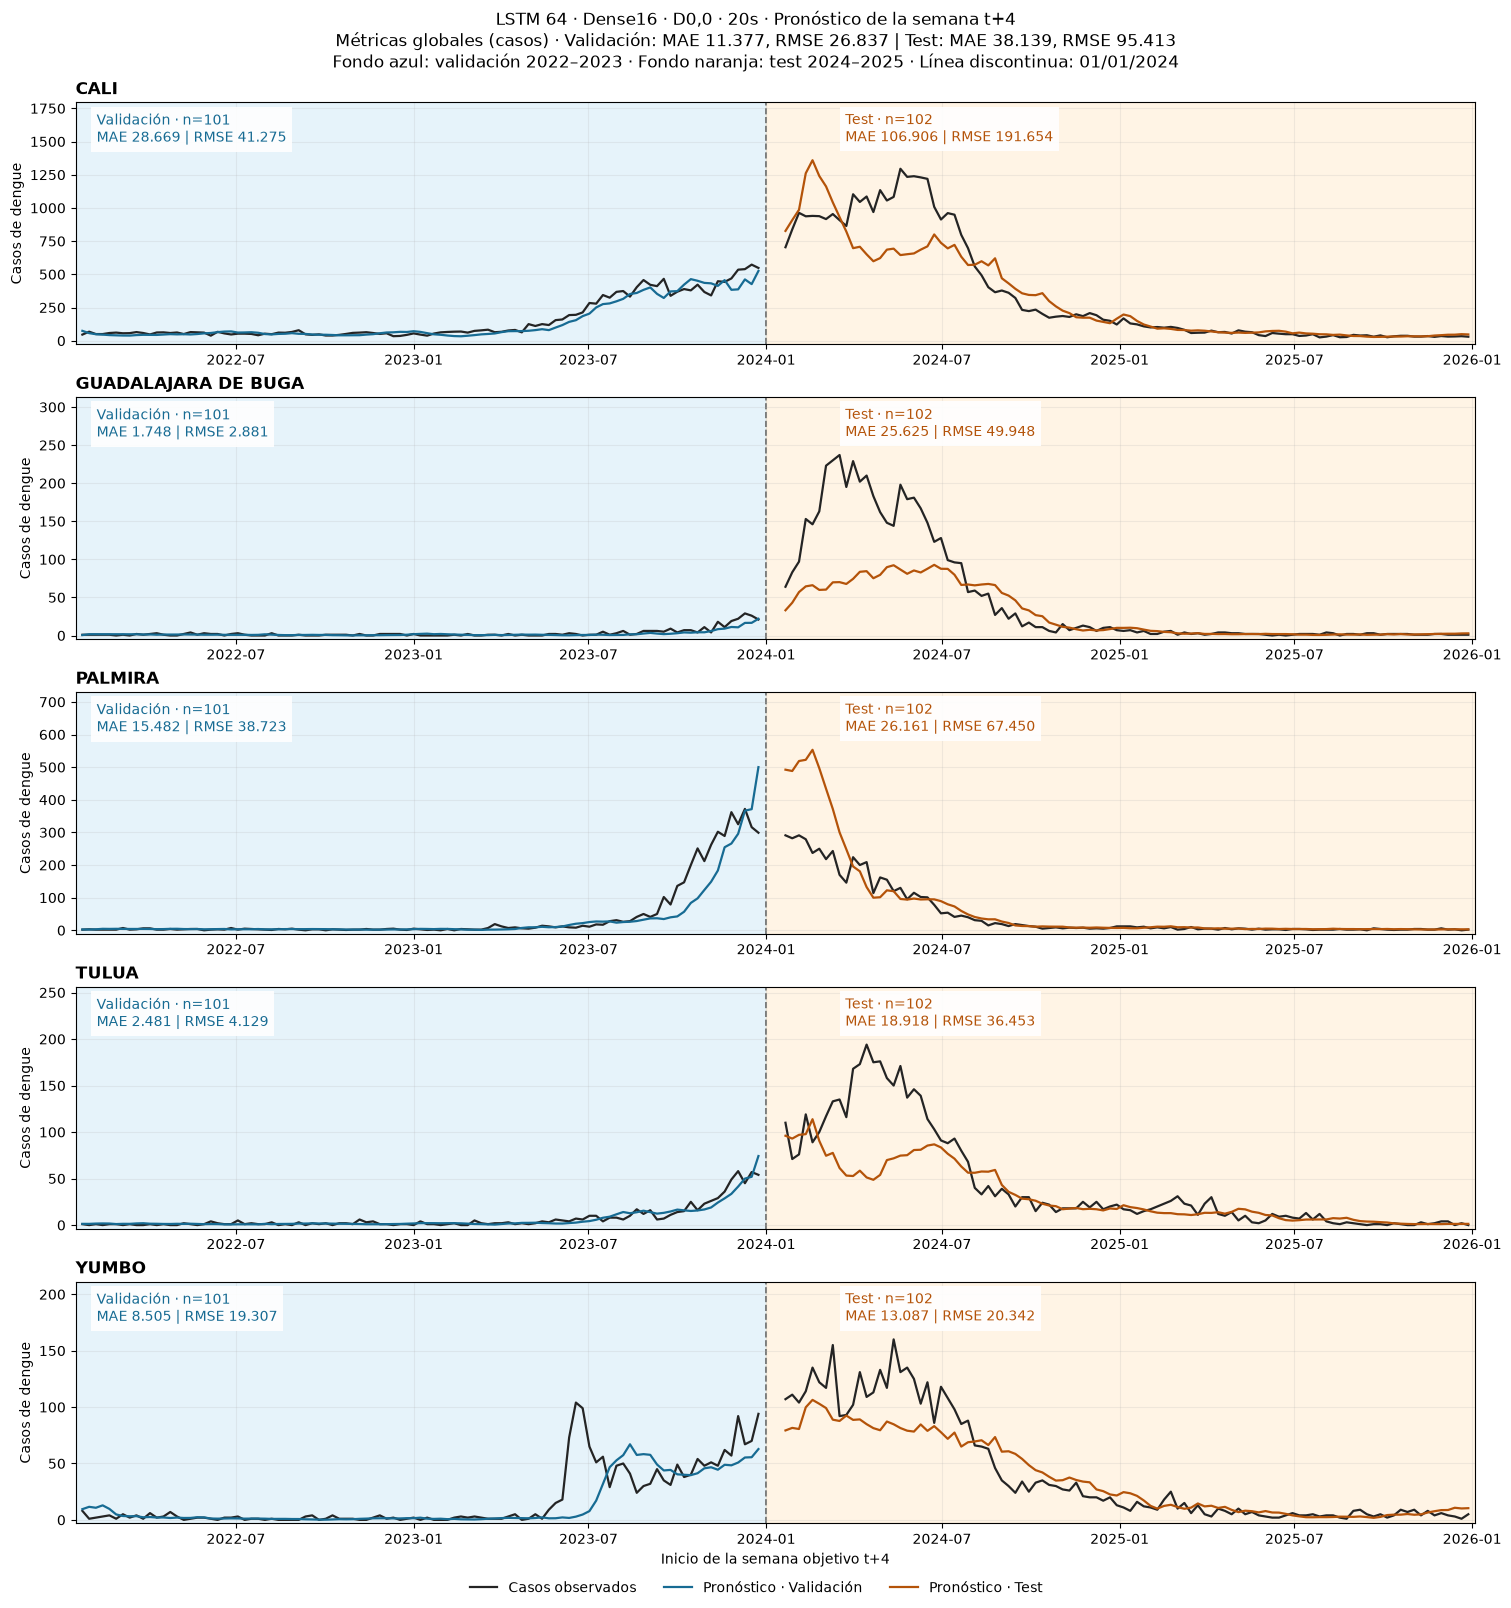

In [84]:
# Reutilizar exclusivamente las predicciones ya calculadas del modelo elegido.
predicciones_validacion_20_6 = predicciones_desarrollo.loc[
    predicciones_desarrollo['ID'].eq(ID_ELEGIDO_AL_CIERRE)
    & predicciones_desarrollo['CONJUNTO'].eq('validation')].copy()
predicciones_test_20_6 = predicciones_evaluacion_cierre.loc[
    predicciones_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].copy()
predicciones_test_20_6['CONJUNTO'] = 'test'
predicciones_modelo_val_test = pd.concat(
    [predicciones_validacion_20_6,predicciones_test_20_6],ignore_index=True)
predicciones_modelo_val_test['FECHA_OBJETIVO'] = pd.to_datetime(predicciones_modelo_val_test['FECHA_OBJETIVO'])
predicciones_modelo_val_test = predicciones_modelo_val_test.sort_values(
    ['COD_DANE','FECHA_OBJETIVO']).reset_index(drop=True)
assert not predicciones_modelo_val_test.duplicated(['COD_DANE','FECHA_OBJETIVO']).any()
assert not predicciones_validacion_20_6.empty and not predicciones_test_20_6.empty

filas_metricas_globales_20_6 = []
for conjunto,grupo in predicciones_modelo_val_test.groupby('CONJUNTO',sort=False):
    errores = grupo['CASOS_PREDICHOS'].to_numpy()-grupo['CASOS_REALES'].to_numpy()
    filas_metricas_globales_20_6.append({'CONJUNTO':conjunto,'N':len(grupo),
        'MAE':np.abs(errores).mean(),'RMSE':np.sqrt(np.mean(errores**2))})
metricas_globales_val_test = pd.DataFrame(filas_metricas_globales_20_6)

filas_metricas_municipales_20_6 = []
for (codigo,municipio,conjunto),grupo in predicciones_modelo_val_test.groupby(
        ['COD_DANE','MUNICIPIO','CONJUNTO'],sort=False,observed=True):
    errores = grupo['CASOS_PREDICHOS'].to_numpy()-grupo['CASOS_REALES'].to_numpy()
    filas_metricas_municipales_20_6.append({'COD_DANE':codigo,'MUNICIPIO':municipio,
        'CONJUNTO':conjunto,'N':len(grupo),'MAE':np.abs(errores).mean(),
        'RMSE':np.sqrt(np.mean(errores**2))})
metricas_municipales_val_test = pd.DataFrame(filas_metricas_municipales_20_6)

# El límite corresponde al comienzo del periodo test, según la semana objetivo.
inicio_periodo_test_20_6 = pd.Timestamp(
    year=predicciones_test_20_6['FECHA_OBJETIVO'].pipe(pd.to_datetime).dt.year.min(),month=1,day=1)
assert predicciones_validacion_20_6['FECHA_OBJETIVO'].pipe(pd.to_datetime).max()<inicio_periodo_test_20_6
fecha_inicial_20_6 = predicciones_modelo_val_test['FECHA_OBJETIVO'].min()-pd.Timedelta(days=7)
fecha_final_20_6 = predicciones_modelo_val_test['FECHA_OBJETIVO'].max()+pd.Timedelta(days=7)
grupos_municipales_20_6 = list(predicciones_modelo_val_test.groupby('COD_DANE',sort=True,observed=True))
figura_modelo_val_test,ejes_modelo_val_test = plt.subplots(
    len(grupos_municipales_20_6),1,figsize=(15,16),sharex=True,constrained_layout=True,squeeze=False)
colores_conjuntos_20_6 = {'validation':'#176B93','test':'#B45309'}

for eje,(codigo,grupo) in zip(ejes_modelo_val_test.ravel(),grupos_municipales_20_6):
    eje.axvspan(fecha_inicial_20_6,inicio_periodo_test_20_6,color='#DCEEF8',alpha=.7,zorder=0)
    eje.axvspan(inicio_periodo_test_20_6,fecha_final_20_6,color='#FFF0DB',alpha=.7,zorder=0)
    eje.axvline(inicio_periodo_test_20_6,color='#666666',linestyle='--',linewidth=1.2,zorder=1)
    for conjunto,x_texto,etiqueta in [('validation',.015,'Validación'),('test',.55,'Test')]:
        datos = grupo.loc[grupo['CONJUNTO'].eq(conjunto)].sort_values('FECHA_OBJETIVO')
        # Dibujar cada conjunto por separado para conservar el intervalo sin pronósticos.
        eje.plot(datos['FECHA_OBJETIVO'],datos['CASOS_ORIGINALES'],
            color='#242424',linewidth=1.6,label='Casos observados' if conjunto=='validation' else '_nolegend_')
        eje.plot(datos['FECHA_OBJETIVO'],datos['CASOS_PREDICHOS'],
            color=colores_conjuntos_20_6[conjunto],linewidth=1.6,label=f'Pronóstico · {etiqueta}')
        resumen = metricas_municipales_val_test.loc[
            metricas_municipales_val_test['COD_DANE'].eq(codigo)
            & metricas_municipales_val_test['CONJUNTO'].eq(conjunto)].iloc[0]
        eje.text(x_texto,.96,
            f"{etiqueta} · n={int(resumen['N'])}\nMAE {resumen['MAE']:.3f} | RMSE {resumen['RMSE']:.3f}",
            transform=eje.transAxes,ha='left',va='top',fontsize=10,
            color=colores_conjuntos_20_6[conjunto],bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=4))
    valores = grupo[['CASOS_ORIGINALES','CASOS_PREDICHOS']].to_numpy()
    minimo,maximo = min(0.,valores.min()),valores.max()
    amplitud = max(1.,maximo-minimo)
    eje.set_ylim(minimo-.02*amplitud,maximo+.32*amplitud)
    eje.set_title(grupo['MUNICIPIO'].iloc[0],loc='left',fontweight='bold',fontsize=12)
    eje.set_ylabel('Casos de dengue')
    eje.grid(alpha=.2)
    eje.set_xlim(fecha_inicial_20_6,fecha_final_20_6)
    eje.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    eje.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    eje.tick_params(axis='x',labelbottom=True)

resumen_global_20_6 = metricas_globales_val_test.set_index('CONJUNTO')
global_validacion_20_6,global_test_20_6 = resumen_global_20_6.loc['validation'],resumen_global_20_6.loc['test']
nombre_modelo_20_6 = predicciones_validacion_20_6['MODELO'].iloc[0]
figura_modelo_val_test.suptitle(
    f"{nombre_modelo_20_6} · Pronóstico de la semana t+4\n"
    f"Métricas globales (casos) · Validación: MAE {global_validacion_20_6['MAE']:.3f}, RMSE {global_validacion_20_6['RMSE']:.3f} "
    f"| Test: MAE {global_test_20_6['MAE']:.3f}, RMSE {global_test_20_6['RMSE']:.3f}\n"
    'Fondo azul: validación 2022–2023 · Fondo naranja: test 2024–2025 · Línea discontinua: 01/01/2024',fontsize=12)
ejes_modelo_val_test[-1,0].set_xlabel('Inicio de la semana objetivo t+4')
handles_20_6,labels_20_6 = ejes_modelo_val_test[0,0].get_legend_handles_labels()
figura_modelo_val_test.legend(handles_20_6,labels_20_6,loc='outside lower center',ncol=3,frameon=False)

RUTA_GRAFICA_20_6 = RUTA_EVALUACION_CIERRE/'validacion_test_modelo_elegido'
RUTA_GRAFICA_20_6.mkdir(parents=True,exist_ok=True)
for extension in ['png','svg']:
    figura_modelo_val_test.savefig(RUTA_GRAFICA_20_6/f'modelo_elegido_validacion_test.{extension}',
        dpi=220,bbox_inches='tight')
metricas_globales_val_test.to_csv(RUTA_GRAFICA_20_6/'metricas_globales.csv',index=False,encoding='utf-8-sig')
metricas_municipales_val_test.to_csv(RUTA_GRAFICA_20_6/'metricas_municipales.csv',index=False,encoding='utf-8-sig')
plt.show()
